# QAOA backend comparison

A self-contained study of one read matrix across ideal simulation, calibrated Berlin/Aachen noise and optionally the real devices. Run the settings and sections in order. Each new run stores its circuits, configuration, raw counts, plots and progress locally; no hardware job is submitted unless `RUN_REAL` is true.

Local ideal training is frozen before screening. The strongest method/depth in noisy screening is used for the separate, equal-budget technique study. This is an exploratory result for one problem and calibration, not a universal ranking.

## 1. Imports and user controls
Choose the project kernel and edit the labelled settings before running. `MODE="load"` reads saved results offline; `MODE="resume"` continues a version 2 run using its original settings. Saved cell outputs may show an earlier run; rerun the settings cell to display the current configuration. With `RUN_REAL=True`, Run All submits hardware jobs without pausing after the workload preview.

In [29]:
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import itertools, json, math, os, sys, time, zlib
from collections import deque
import numpy as np
import pandas as pd
import networkx as nx
from IPython.display import display, Image, Markdown
from scipy.optimize import minimize
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister, qpy
from qiskit.circuit import Delay, Parameter, ParameterVector, pauli_twirl_2q_gates
from qiskit.circuit.library import XGate
from qiskit.quantum_info import Statevector
from qiskit.transpiler import PassManager, generate_preset_pass_manager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay, PadDynamicalDecoupling
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise.passes import RelaxationNoisePass
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
print({name: metadata.version(name) for name in ('qiskit','qiskit-aer','qiskit-ibm-runtime','numpy','scipy','pandas')})

{'qiskit': '2.5.0', 'qiskit-aer': '0.17.2', 'qiskit-ibm-runtime': '0.47.0', 'numpy': '2.5.1', 'scipy': '1.18.0', 'pandas': '3.0.3'}


In [ ]:
# Run the local study, load a saved folder, or resume a version 2 run.
MODE = 'run'              # 'run', 'load', 'resume'
RUN_FOLDER = None         # required for load/resume
RECOVER_JOB_IDS = {}      # unknown submission: {'ibm_berlin|0': 'job-id'}
RUN_REAL = False           # Full real-device study; Run All submits hardware jobs
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'all_together.ipynb').exists())
OUTPUT_DIR = ROOT/'results'/'backend_comparison'
BACKENDS = ['ibm_berlin', 'ibm_aachen']
READS = [[0,1,1,-1,-1],[1,0,0,-1,-1],[-1,1,1,0,-1],[-1,0,0,1,-1],
         [-1,-1,1,0,1],[-1,-1,0,1,0],[0,-1,-1,0,1],[1,-1,-1,1,0],[0,0,-1,-1,-1]]
METHODS = ['standard', 'warm-start', 'multi-angle']
DEPTHS = [1,2,3]
OBJECTIVE = 'A baseline'
PRUNE_RULE = 'mstforest'  # or 'none'
SHOTS, SCREEN_SHOTS, REPEATS, SCREEN_REPEATS = 2048, 1024, 3, 3
TECHNIQUE_SHOTS = 4096    # total per technique arm, including calibration/folding
TECHNIQUES = ['readout','trex','dd','twirling','zne']  # raw reference always included
STANDARD_ITERATIONS, MULTI_ITERATIONS, STARTS = 100, 500, 5
SEED, TRAINING_SEED, TRANSPILE_SEED, LOCAL_SEED, PRUNING_SEED = 71, 71, 71, 17, 7  # forest pruning is deterministic
OPTIMIZATION_LEVEL, LOCAL_BUDGET, LOCAL_RESTARTS, EPSILON = 2, 128, 16, 0.25
SHOW_PLOTS = True
GENERATE_PROFESSIONAL_PLOTS = True  # save combined ideal/noisy/real figures after the run
ALL_DISTRIBUTION_DEPTHS = False
BACKEND_OVERRIDES = None  # optional injected fake backends for local tests
CONFIG = {'mode':MODE,'run_folder':str(RUN_FOLDER) if RUN_FOLDER is not None else None,
          'run_real':RUN_REAL,'recovery_job_ids':RECOVER_JOB_IDS,'output_dir':str(OUTPUT_DIR),'backends':BACKENDS,'reads':READS,
          'methods':METHODS,'depths':DEPTHS,'objective':OBJECTIVE,'prune_rule':PRUNE_RULE,'shots':SHOTS,
          'screen_shots':SCREEN_SHOTS,'repeats':REPEATS,'screen_repeats':SCREEN_REPEATS,
          'technique_shots':TECHNIQUE_SHOTS,'techniques':TECHNIQUES,'standard_iterations':STANDARD_ITERATIONS,
          'multi_iterations':MULTI_ITERATIONS,'starts':STARTS,'seed':SEED,'training_seed':TRAINING_SEED,
          'transpile_seed':TRANSPILE_SEED,'local_seed':LOCAL_SEED,'pruning_seed':PRUNING_SEED,'optimization_level':OPTIMIZATION_LEVEL,
          'local_budget':LOCAL_BUDGET,'local_restarts':LOCAL_RESTARTS,'epsilon':EPSILON,
          'all_distribution_depths':ALL_DISTRIBUTION_DEPTHS}
print('Run mode:', MODE, '| hardware submission:', RUN_REAL and MODE in ('run','resume'))
display(pd.DataFrame([CONFIG]).T.rename(columns={0:'setting'}))

Run mode: run | hardware submission: True


,setting
mode,run
run_folder,None
run_real,True
recovery_job_ids,{}
output_dir,c:\Users\Alex\Documents\Projects\Qiskit-Fall-F...
backends,"[ibm_berlin, ibm_aachen]"
reads,"[[0, 1, 1, -1, -1], [1, 0, 0, -1, -1], [-1, 1,..."
methods,"[standard, warm-start, multi-angle]"
depths,"[1, 2, 3]"
objective,A baseline


## 2. Evidence and exact references
Same/opposite pair votes define the full graph. Full pairwise and MEC minima judge every sample. State labels list SNP 1 first; Qiskit count strings are reversed when decoded.

In [31]:
def save_json(path, value):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, default=str, allow_nan=False), encoding='utf-8')
    os.replace(tmp, path)


def ibm_service(root):
    values = {}
    env_file = Path(root) / '.env'
    if env_file.exists():
        for line in env_file.read_text(encoding='utf-8').splitlines():
            if '=' in line and not line.lstrip().startswith('#'):
                key, val = line.split('=', 1)
                values[key.strip()] = val.strip().strip("\"'")
    token = os.getenv('IBM_API_KEY') or values.get('IBM_API_KEY')
    instance = (os.getenv('IBM_INSTANCE_CRN') or os.getenv('IBM_INSTANCE')
                or values.get('IBM_INSTANCE_CRN') or values.get('IBM_INSTANCE'))
    if not token:
        raise ValueError('Set IBM_API_KEY in the environment or project .env file.')
    options = {'channel': 'ibm_quantum_platform', 'token': token}
    if instance:
        options['instance'] = instance
    return QiskitRuntimeService(**options)


def problem(reads):
    reads = np.asarray(reads)
    if reads.ndim != 2 or not 1 <= reads.shape[1] <= 12 or not len(reads) or not np.isin(reads, [-1, 0, 1]).all():
        raise ValueError('Reads must be a nonempty matrix of -1/0/1 with 1–12 SNPs.')
    n = reads.shape[1]
    a, d = np.zeros((n,n)), np.zeros((n,n))
    for row in reads:
        for i,j in itertools.combinations(np.flatnonzero(row != -1), 2):
            (a if row[i] == row[j] else d)[i,j] += 1
    states = np.array(list(itertools.product([0,1], repeat=n)), dtype=int)
    full = sum((np.where(states[:,i] == states[:,j], d[i,j], a[i,j])
                for i,j in itertools.combinations(range(n),2)), np.zeros(len(states)))
    mec = np.zeros(len(states))
    for row in reads:
        seen = row != -1
        dist = (states[:,seen] != row[seen]).sum(axis=1)
        mec += np.minimum(dist, seen.sum()-dist)
    return reads, a, d, states, full, mec


def forest_j(a, d):
    # Same descending |A-D| Kruskal forest as the combined notebook.
    n = len(a); parent = list(range(n)); j = np.zeros_like(a)
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    edges = [(i,k) for i,k in itertools.combinations(range(n),2) if a[i,k] != d[i,k]]
    edges.sort(key=lambda e: abs(a[e]-d[e]), reverse=True)
    for i,k in edges:
        x,y = find(i), find(k)
        if x != y:
            parent[x] = y; j[i,k] = (d[i,k]-a[i,k])/2
    return j


def measurements(circuit):
    return {circuit.find_bit(item.clbits[0]).index: circuit.find_bit(item.qubits[0]).index
            for item in circuit.data if item.operation.name == 'measure'}


def calibrations(compiled):
    mapping = measurements(compiled)
    n = compiled.num_clbits
    if set(mapping) != set(range(n)):
        raise ValueError('Expected exactly one measured physical qubit per SNP.')
    circuits = []
    for prepared in (0,1):
        qc = QuantumCircuit(QuantumRegister(compiled.num_qubits, 'q'), ClassicalRegister(n, 'meas'), name=f'calibration_{prepared}')
        for bit, qubit in mapping.items():
            if prepared: qc.x(qubit)
            qc.measure(qubit, bit)
        circuits.append(qc)
    return circuits


def circuit_stats(qc):
    two = lambda inst: inst.operation.num_qubits == 2 and inst.operation.name != 'barrier'
    return {'depth': qc.depth(), 'two_qubit_depth': qc.depth(filter_function=two),
            'two_qubit_gates': sum(two(i) for i in qc.data),
            'physical_qubits_used': len({qc.find_bit(q).index for inst in qc.data
                                         if inst.operation.name != 'barrier' for q in inst.qubits}),
            'operations': dict(qc.count_ops()), 'measurement_map': measurements(qc)}


def probability_metrics(counts, states, full, mec, ideal_probs):
    n = states.shape[1]; total = sum(counts.values())
    if not total: raise ValueError('No counts returned')
    index = {tuple(s): i for i,s in enumerate(states)}
    probs = np.zeros(len(states))
    for key,count in counts.items():
        bits = tuple(int(b) for b in key.replace(' ','')[::-1])
        if len(bits) != n: raise ValueError(f'Unexpected measurement width: {key}')
        probs[index[bits]] += count/total
    success = float(probs[np.isclose(full, full.min(), rtol=0, atol=1e-9)].sum())
    return {'shots': total, 'full_optimum_probability': success,
            'full_optimum_standard_error': float(np.sqrt(success*(1-success)/total)),
            'mean_full_cost': float(probs @ full),
            'mec_optimum_probability': float(probs[np.isclose(mec,mec.min(),rtol=0,atol=1e-9)].sum()),
            'mean_mec': float(probs @ mec),
            'total_variation_from_ideal': float(np.abs(probs-ideal_probs).sum()/2)}


def correction(counts, cal_counts, a, d):
    n = len(a); response = np.zeros((n,2,2))
    for prepared, data in enumerate(cal_counts):
        total = sum(data.values())
        for key,count in data.items():
            for i,bit in enumerate(key.replace(' ','')[::-1]):
                response[i,int(bit),prepared] += count/total
    conditions = [float(np.linalg.cond(m)) for m in response]
    if not np.isfinite(conditions).all() or max(conditions) > 1e6:
        raise ValueError('Readout calibration is singular or unstable.')
    z = np.array([1.,-1.]) @ np.linalg.inv(response)
    total = sum(counts.values()); estimate = 0.
    for key,count in counts.items():
        bits = [int(b) for b in key.replace(' ','')[::-1]]
        for i,k in itertools.combinations(range(n),2):
            estimate += count*((a[i,k]+d[i,k])/2 + (d[i,k]-a[i,k])/2*z[i,bits[i]]*z[k,bits[k]])
    return float(estimate/total), response.tolist(), conditions


## 3. Pruning, local search and circuit families
The forest keeps the strongest connectivity-preserving edges. Warm-start uses the local-search candidate, never hidden truth or an enumerated solution. Circuit implementations below are from the combined notebook.

In [32]:
def _sym(J):
    return J + J.T


def _greedy(W, k, rng):
    """Randomised greedy: visit SNPs in random order, give each the letter that best fits so far."""
    n = len(W)
    order = np.argsort(rng.random((k, n)), axis=1)
    Z, ar = np.zeros((k, n)), np.arange(k)
    for t in range(n):
        i = order[:, t]
        fld = (W[i] * Z).sum(axis=1)
        tie = rng.choice([-1.0, 1.0], size=k)
        Z[ar, i] = np.where(fld > 0, -1.0, np.where(fld < 0, 1.0, tie))
    return Z


def greedy_local_search(J, offset, budget, runs, rng, target=-math.inf):
    """Greedy start + steepest 1-flip descent, restarting when stuck, until the budget is spent."""
    n, W = len(J), _sym(J)
    ar = np.arange(runs)
    Z = _greedy(W, runs, rng)
    used = np.full(runs, 2 * n)
    h = Z @ W
    E = offset + 0.5 * (Z * h).sum(axis=1)
    best, bestZ = E.copy(), Z.copy()
    hit = np.where(E <= target + 1e-9, used.astype(float), np.inf)
    while True:
        active = used + n <= budget
        if not active.any():
            break
        dE = -2.0 * Z * h                                  # cost change of every single flip
        j = dE.argmin(axis=1)
        m = dE[ar, j]
        used[active] += n
        imp = active & (m < -1e-12)
        if imp.any():
            idx, jj = ar[imp], j[imp]
            z_old = Z[idx, jj].copy()
            Z[idx, jj] = -z_old
            h[idx] -= 2.0 * z_old[:, None] * W[jj]
            E[imp] += m[imp]
        stuck = active & ~imp
        restart = stuck & (used + 2 * n <= budget)
        if restart.any():
            Z[restart] = _greedy(W, int(restart.sum()), rng)
            used[restart] += 2 * n
            h[restart] = Z[restart] @ W
            E[restart] = offset + 0.5 * (Z[restart] * h[restart]).sum(axis=1)
        newly = (E <= target + 1e-9) & np.isinf(hit)
        hit[newly] = used[newly]
        used[stuck & ~restart] = budget
        better = E < best - 1e-12
        best[better], bestZ[better] = E[better], Z[better]
    return best, ((1 - bestZ) / 2).astype(np.int8), np.minimum(used, budget), hit


def qaoa_scale(J):
    return float(max(1, np.max(np.abs(J))))


def make_qaoa(J, p=1):
    """Same circuit as the notebook's make_qaoa: H, then per layer RZZ on active pairs and RX."""
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector

    J = np.asarray(J, float)
    n = J.shape[0]
    scale = qaoa_scale(J)
    theta = ParameterVector("theta", 2 * p)
    gammas, betas = theta[:p], theta[p:]
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(p):
        for a in range(n):
            for b in range(a + 1, n):
                if J[a, b] != 0:
                    qc.rzz(2 * gammas[layer] * J[a, b] / scale, a, b)
        for q in range(n):
            qc.rx(2 * betas[layer], q)
    return qc, theta, scale


def warm_start_qaoa(n, J, c, p, eps):
    J = np.asarray(J, dtype=float)
    c = np.clip(c, eps, 1 - eps)
    theta = 2 * np.arcsin(np.sqrt(c))
    scale = float(max(1, np.max(np.abs(J))))
    gam = [Parameter(f'g{k}') for k in range(p)]
    bet = [Parameter(f'b{k}') for k in range(p)]
    qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(theta[i], i)                       # warm-start state
    for k in range(p):
        for i in range(n):
            for j in range(i + 1, n):
                if J[i, j] != 0:
                    qc.rzz(2 * gam[k] * J[i, j] / scale, i, j)
        for i in range(n):                       # warm-start mixer
            qc.ry(-theta[i], i)
            qc.rz(-2 * bet[k], i)
            qc.ry(theta[i], i)
    return qc, list(gam) + list(bet)


def make_ma_qaoa(J, p):
    J = np.asarray(J, dtype=float); n = J.shape[0]
    scale = float(max(1, np.max(np.abs(J))))
    active = [(a, b) for a in range(n) for b in range(a + 1, n) if J[a, b] != 0]
    per_layer = len(active) + n
    theta = ParameterVector('ma', p * per_layer)
    qc = QuantumCircuit(n); qc.h(range(n))
    for layer in range(p):
        base = layer * per_layer
        for idx, (a, b) in enumerate(active):
            qc.rzz(2 * theta[base + idx] * J[a, b] / scale, a, b)
        for q in range(n):
            qc.rx(2 * theta[base + len(active) + q], q)
    return qc, list(theta)


In [33]:
def native_scores(states, j, offset):
    z = 1 - 2 * np.asarray(states)
    return offset + sum((j[i, k] * z[:, i] * z[:, k]
                         for i, k in itertools.combinations(range(len(j)), 2)),
                        np.zeros(len(states)))


def make_template(method, j, depth, seed_bits, epsilon):
    if method == 'standard':
        circuit, params, _ = make_qaoa(j, depth)
    elif method == 'warm-start':
        circuit, params = warm_start_qaoa(len(j), j, seed_bits, depth, epsilon)
    elif method == 'multi-angle':
        circuit, params = make_ma_qaoa(j, depth)
    else:
        raise ValueError(f'Unknown QAOA method: {method}')
    return circuit, list(params)


def fit_template(circuit, params, states, native, full, maxiter, starts, seed):
    if len(set(params)) != len(params) or not set(circuit.parameters).issubset(params):
        raise ValueError('Circuit parameters disagree with their ordered list.')
    active = [p for p in params if p in circuit.parameters]
    indices = [sum(int(bit) << i for i, bit in enumerate(state)) for state in states]
    native_basis = np.zeros(len(states)); full_basis = np.zeros(len(states))
    native_basis[indices] = native; full_basis[indices] = full
    rng = np.random.default_rng(seed); trials = []; began = time.perf_counter()
    if not active:
        probabilities = Statevector.from_instruction(circuit).probabilities()
        return circuit.copy(), {'parameters': [str(p) for p in params], 'angles': [0.]*len(params), 'active_parameters': [], 'starts': [], 'evaluations': 1,
             'best_native_cost': float(probabilities @ native_basis), 'wall_seconds': time.perf_counter()-began}
    for start in range(starts):
        trace = []
        def objective(values):
            probabilities = Statevector.from_instruction(circuit.assign_parameters(dict(zip(active, values)))).probabilities()
            native_value = float(probabilities @ native_basis)
            trace.append({'evaluation': len(trace)+1, 'native_cost': native_value,
                          'full_cost': float(probabilities @ full_basis),
                          'active_angles': np.asarray(values, dtype=float).tolist()})
            return native_value
        initial = rng.uniform(0, np.pi, len(active))
        result = minimize(objective, initial, method='COBYLA', options={'maxiter': maxiter})
        full_angles = [float(result.x[active.index(p)]) if p in active else 0. for p in params]
        trials.append({'start': start, 'initial_active_angles': initial.tolist(),
                       'angles': np.asarray(result.x, float).tolist(), 'full_angles': full_angles,
                       'native_cost': float(result.fun), 'evaluations': int(result.nfev),
                       'success': bool(result.success), 'message': str(result.message), 'trace': trace})
    best = min(trials, key=lambda trial: trial['native_cost'])
    frozen = circuit.assign_parameters(dict(zip(active, best['angles'])))
    return frozen, {'parameters': [str(p) for p in params], 'angles': best['full_angles'],
                    'active_parameters': [str(p) for p in active],
                    'starts': trials, 'best_start': best['start'],
                    'best_native_cost': best['native_cost'],
                    'evaluations': sum(t['evaluations'] for t in trials),
                    'wall_seconds': time.perf_counter()-began}


def ideal_probabilities(circuit, states):
    vector = Statevector.from_instruction(circuit.remove_final_measurements(inplace=False)).probabilities()
    return np.array([vector[sum(int(bit) << i for i, bit in enumerate(state))] for state in states])


def save_circuit(path, circuit):
    with Path(path).open('wb') as f:
        qpy.dump(circuit, f)


def load_circuit(path):
    with Path(path).open('rb') as f:
        return qpy.load(f)[0]


def seeded(config, *parts):
    return int((config['seed'] + zlib.crc32('|'.join(map(str, parts)).encode())) % (2**32-1))


def trial_key(stage, backend, method, depth, repeat, technique, variant):
    return '|'.join(map(str, (stage, backend, method, depth, repeat, technique, variant)))


def workload(config):
    n = len(config['methods']) * len(config['depths'])
    shots = config['shots']; tech = config['technique_shots']; repeats = config['repeats']
    counts = {'raw': n*shots, 'raw_reference': tech}
    for name in ('readout', 'trex', 'dd', 'twirling', 'zne'):
        if name in config['techniques']:
            counts[name] = tech
    per_backend = repeats * sum(counts.values())
    return {'screening_simulator_shots': len(config['backends'])*n*config['screen_shots']*config['screen_repeats'],
            'ideal_shots': n*shots*repeats, 'noise_shots': per_backend*len(config['backends']),
            'hardware_shots_if_enabled': per_backend*len(config['backends']) if config['run_real'] else 0,
            'hardware_shots_full_plan': per_backend*len(config['backends']),
            'hardware_jobs_before_skips': len(config['backends'])*repeats if config['run_real'] else 0,
            'per_backend_per_repeat': counts}


def validate_config(config):
    if config['objective'] != 'A baseline':
        raise ValueError('Only the A baseline objective is supported.')
    if config['mode'] not in ('run', 'load', 'resume'):
        raise ValueError('MODE must be run, load or resume.')
    if type(config['run_real']) is not bool:
        raise ValueError('RUN_REAL must be a boolean.')
    if not config['methods'] or len(set(config['methods'])) != len(config['methods']) or not set(config['methods']) <= {'standard','warm-start','multi-angle'}:
        raise ValueError('Select at least one supported method.')
    if not config['backends'] or len(set(config['backends'])) != len(config['backends']):
        raise ValueError('Select distinct backend names.')
    if not config['depths'] or len(set(config['depths'])) != len(config['depths']) or any(type(p) is not int or p < 1 for p in config['depths']):
        raise ValueError('Depths must be positive integers.')
    for key in ('shots','screen_shots','repeats','screen_repeats','starts','standard_iterations','multi_iterations','technique_shots','local_budget','local_restarts'):
        if type(config[key]) is not int or config[key] < 1:
            raise ValueError(f'{key} must be a positive integer.')
    if not 0 < config['epsilon'] < .5:
        raise ValueError('EPSILON must be between 0 and 0.5.')
    if config['optimization_level'] not in (0,1,2,3):
        raise ValueError('OPTIMIZATION_LEVEL must be 0, 1, 2 or 3.')
    if config['technique_shots'] % 16:
        raise ValueError('TECHNIQUE_SHOTS must be divisible by 16.')
    if not set(config['techniques']) <= {'readout','trex','dd','twirling','zne'}:
        raise ValueError('Unknown noise technique.')
    if config['mode'] != 'run' and not config['run_folder']:
        raise ValueError('Set RUN_FOLDER for load or resume.')
    if 'trex' in config['techniques'] and config['technique_shots'] % (2 * min(16, 2 ** len(config['reads'][0]))):
        raise ValueError('TREX-style shots must divide evenly across target and calibration masks.')
    problem(config['reads'])


## 4. Compilation and noise techniques
Each arm has the same total shot budget. Readout correction and ZNE estimate cost only. DD requires verified delay relaxation; unsupported or unverified transformations are recorded as skips.

In [34]:
def compact_probabilities(circuit, n):
    """Logical classical-bit probabilities using only physically active qubits."""
    mapping = measurements(circuit)
    active = sorted({circuit.find_bit(q).index for item in circuit.data
                     if item.operation.name not in ('barrier', 'delay') for q in item.qubits})
    if len(active) > 12:
        raise ValueError(f'Cannot verify ideal equivalence: {len(active)} active qubits exceed 12.')
    remap = {physical: i for i, physical in enumerate(active)}
    small = QuantumCircuit(len(active))
    for item in circuit.data:
        if item.operation.name in ('barrier', 'delay', 'measure'):
            continue
        if item.clbits:
            raise ValueError('Classical control is unsupported in equivalence verification.')
        small.append(item.operation, [remap[circuit.find_bit(q).index] for q in item.qubits])
    vector = Statevector.from_instruction(small).probabilities(); output = np.zeros(2**n)
    for basis, probability in enumerate(vector):
        logical = sum(((basis >> remap[physical]) & 1) << bit for bit, physical in mapping.items())
        output[logical] += probability
    return output


def fold_two_qubit(circuit, factor, backend):
    if factor not in (1, 3):
        raise ValueError('Only factors 1 and 3 are supported.')
    folded = circuit.copy_empty_like()
    for item in circuit.data:
        gate = item.operation
        if gate.num_qubits == 2 and gate.name != 'barrier' and factor == 3:
            inverse = gate.inverse()
            if inverse.name not in backend.target.operation_names:
                raise ValueError(f'Inverse gate {inverse.name} is not in the backend target.')
            folded.append(gate, item.qubits, item.clbits)
            folded.append(inverse, item.qubits, item.clbits)
        folded.append(gate, item.qubits, item.clbits)
    return folded


def delay_relaxation_available(simulator):
    model = simulator.options.noise_model
    for noise_pass in getattr(model, '_custom_noise_passes', []):
        ops = getattr(noise_pass, '_ops', ()) or ()
        if isinstance(noise_pass, RelaxationNoisePass) and Delay in ops:
            return True
    return False


def trex_masks(n, seed):
    """Pairwise-balanced masks; bit i always denotes classical SNP bit i."""
    if not 1 <= n <= 12:
        raise ValueError('TREX-style masking supports 1–12 measured bits.')
    width = min(n, 4)
    columns = ([1 << i for i in range(n)] if n <= 4 else
               [1, 2, 4, 8, 3, 5, 6, 7, 9, 10, 11, 12][:n])
    rng = np.random.default_rng(seed)
    shifts = rng.integers(0, 2, size=n)
    rows = rng.permutation(1 << width)
    return [tuple(((int(row) & col).bit_count() % 2) ^ int(shifts[i])
                  for i, col in enumerate(columns)) for row in rows]


def trex_circuits(base, backend, masks, budget):
    """Build equally budgeted masked measurements and matching calibration circuits."""
    n = base.num_clbits
    if not masks or budget % (2 * len(masks)):
        raise ValueError('TREX-style budget must divide across target and calibration masks.')
    mapping = measurements(base)
    if set(mapping) != set(range(n)):
        raise ValueError('TREX-style calibration requires one measurement per SNP.')
    reference = compact_probabilities(base, n)
    shots = budget // (2 * len(masks)); variants = []
    for mask in masks:
        if len(mask) != n or any(bit not in (0, 1) for bit in mask):
            raise ValueError('Invalid TREX-style mask.')
        label = ''.join(map(str, mask))
        circuit = base.copy_empty_like()
        circuit.name = f'trex_target_mask_{label}'
        for item in base.data:
            if item.operation.name == 'measure':
                bit = base.find_bit(item.clbits[0]).index
                if mask[bit]: circuit.x(item.qubits[0])
            circuit.append(item.operation, item.qubits, item.clbits)
        mask_value = sum(int(bit) << i for i, bit in enumerate(mask))
        masked = compact_probabilities(circuit, n)
        if measurements(circuit) != mapping or not np.allclose(masked[np.arange(2**n) ^ mask_value], reference, atol=1e-8):
            raise ValueError('TREX-style target changed the unmasked ideal distribution.')
        cal = QuantumCircuit(QuantumRegister(base.num_qubits, 'q'), ClassicalRegister(n, 'meas'), name=f'trex_cal_mask_{label}')
        for bit, physical in mapping.items():
            if mask[bit]: cal.x(physical)
            cal.measure(physical, bit)
        variants.extend([(f'target_mask_{label}', circuit, shots), (f'cal_mask_{label}', cal, shots)])
    return variants


def trex_estimate(items, a, d):
    """TREX-style local-response cost estimate; counts remain uncorrected samples."""
    n = len(a); response = np.zeros((n, 2, 2)); target = []; target_masks = set(); cal_masks = set(); target_shots = set(); cal_shots = set()
    for variant, record in items.items():
        prefix, sep, label = variant.partition('_mask_')
        if not sep or prefix not in ('target', 'cal') or len(label) != n or set(label) - {'0', '1'}:
            raise ValueError(f'Invalid TREX-style variant {variant}')
        mask = tuple(int(bit) for bit in label)
        if prefix == 'target':
            target_masks.add(mask); target_shots.add(sum(record['counts'].values())); target.append((mask, record['counts']))
            continue
        cal_masks.add(mask); cal_shots.add(sum(record['counts'].values()))
        for key, count in record['counts'].items():
            observed = key.replace(' ', '')[::-1]
            if len(observed) != n: raise ValueError('Unexpected calibration measurement width.')
            for i, bit in enumerate(observed): response[i, int(bit), mask[i]] += count
    if target_masks != cal_masks or len(target_masks) != min(16, 2**n):
        raise ValueError('TREX-style target and calibration masks are incomplete or unpaired.')
    if len(target_shots) != 1 or len(cal_shots) != 1 or min(target_shots | cal_shots) <= 0:
        raise ValueError('TREX-style masks require equal, positive shots within each group.')
    totals = response.sum(axis=1)
    if np.any(totals == 0): raise ValueError('TREX-style calibration is incomplete.')
    response /= totals[:, None, :]
    gains = response[:, 0, 0] + response[:, 1, 1] - 1
    if not np.isfinite(gains).all() or np.min(np.abs(gains)) < .1:
        raise ValueError('TREX-style calibration has unstable readout gain.')
    pair_sum = np.zeros((n, n)); total = 0
    for mask, counts in target:
        for key, count in counts.items():
            observed = key.replace(' ', '')[::-1]
            if len(observed) != n: raise ValueError('Unexpected target measurement width.')
            z = np.array([1 - 2 * (int(bit) ^ mask[i]) for i, bit in enumerate(observed)])
            pair_sum += count * np.outer(z, z); total += count
    if not total: raise ValueError('TREX-style target samples are missing.')
    return float(sum((a[i,j]+d[i,j])/2 + (d[i,j]-a[i,j])/2 * pair_sum[i,j]/total/(gains[i]*gains[j])
                     for i,j in itertools.combinations(range(n),2)))


def prepare_techniques(compiled, backend, simulator, config, repeat):
    """Return circuits and shot allocations. Every non-skipped arm costs TECHNIQUE_SHOTS."""
    budget = config['technique_shots']; n = compiled.num_clbits
    try:
        reference = compact_probabilities(compiled, n)
    except ValueError as exc:
        return {'raw_reference':[('target',compiled,budget)]}, {name:f'Equivalence verification unavailable: {exc}' for name in config['techniques']}
    base = compiled; dd = None; skips = {}
    if 'dd' in config['techniques']:
        try:
            base = PassManager([ALAPScheduleAnalysis(target=backend.target),
                                PadDelay(target=backend.target)]).run(compiled)
            dd = PassManager([ALAPScheduleAnalysis(target=backend.target),
                              PadDynamicalDecoupling(dd_sequence=[XGate(),XGate()], qubits=sorted({compiled.find_bit(q).index for item in compiled.data if item.operation.name not in ('barrier','delay') for q in item.qubits}), target=backend.target)]).run(compiled)
            if not np.allclose(compact_probabilities(base,n), reference, atol=1e-8):
                raise ValueError('Scheduled baseline changed ideal probabilities.')
            if not np.allclose(compact_probabilities(dd,n), reference, atol=1e-8):
                raise ValueError('DD changed ideal probabilities.')
        except Exception as exc:
            base = compiled; dd = None; skips['dd'] = f'{type(exc).__name__}: {exc}'
    arms = {'raw_reference': [('target', base, budget)]}
    if 'readout' in config['techniques']:
        try:
            cal = calibrations(compiled)
            pm = generate_preset_pass_manager(backend=backend, optimization_level=0,
                  initial_layout=list(range(backend.num_qubits)), seed_transpiler=config['transpile_seed'])
            cal = pm.run(cal)
            if any(measurements(c) != measurements(compiled) for c in cal):
                raise ValueError('Calibration measurement mapping changed.')
            arms['readout'] = [('target',base,budget//2),('cal0',cal[0],budget//4),('cal1',cal[1],budget//4)]
        except Exception as exc:
            skips['readout'] = f'{type(exc).__name__}: {exc}'
    if 'trex' in config['techniques']:
        try:
            masks = trex_masks(n, seeded(config, backend.name, repeat, 'trex'))
            arms['trex'] = trex_circuits(base, backend, masks, budget)
        except Exception as exc:
            skips['trex'] = f'{type(exc).__name__}: {exc}'
    if dd is not None:
        arms['dd'] = [('target',dd,budget)]
    if 'twirling' in config['techniques']:
        try:
            variants = pauli_twirl_2q_gates(base, seed=seeded(config, backend.name, repeat, 'twirl'),
                                           num_twirls=16, target=backend.target)
            for circuit in variants:
                if measurements(circuit) != measurements(compiled) or not np.allclose(compact_probabilities(circuit,n),reference,atol=1e-8):
                    raise ValueError('Twirled circuit changed logical measurement probabilities.')
            arms['twirling'] = [(f'twirl_{i}',circuit,budget//16) for i,circuit in enumerate(variants)]
        except Exception as exc:
            skips['twirling'] = f'{type(exc).__name__}: {exc}'
    if 'zne' in config['techniques']:
        try:
            folded = fold_two_qubit(base, 3, backend)
            if not np.allclose(compact_probabilities(folded,n),reference,atol=1e-8):
                raise ValueError('Folding changed ideal probabilities.')
            arms['zne'] = [('factor_1',base,budget//2),('factor_3',folded,budget//2)]
        except Exception as exc:
            skips['zne'] = f'{type(exc).__name__}: {exc}'
    for arm in list(arms):
        try:
            for _,circuit,_ in arms[arm]:
                for item in circuit.data:
                    if item.operation.name == 'barrier':
                        continue
                    qargs = tuple(circuit.find_bit(q).index for q in item.qubits)
                    if not backend.target.instruction_supported(operation_name=item.operation.name, qargs=qargs):
                        raise ValueError(f'Unsupported target instruction {item.operation.name} on {qargs}')
        except Exception as exc:
            if arm == 'raw_reference':
                raise
            skips[arm] = f'{type(exc).__name__}: {exc}'
            del arms[arm]
    for arm, variants in arms.items():
        if sum(v[2] for v in variants) != budget:
            raise AssertionError(f'{arm} has the wrong shot budget')
    return arms, skips


def normalize_counts(counts, states):
    n = states.shape[1]; indices = {tuple(s): i for i,s in enumerate(states)}
    probs = np.zeros(len(states)); total = sum(counts.values())
    if total <= 0:
        raise ValueError('Empty counts.')
    for key, count in counts.items():
        bits = tuple(map(int,key.replace(' ','')[::-1]))
        if len(bits) != n:
            raise ValueError(f'Unexpected measurement width: {key}')
        probs[indices[bits]] += count/total
    return probs


def merge_counts(counts_list):
    merged = {}
    for counts in counts_list:
        for key, count in counts.items():
            merged[key] = merged.get(key, 0) + int(count)
    return merged


def result_row(task, counts, states, full, mec, ideal):
    metrics = probability_metrics(counts,states,full,mec,ideal)
    return {**{k: task[k] for k in ('stage','backend','method','depth','repeat','technique')}, **metrics}


## 5. Persistence and recovery
Version 2 stores individual raw records, circuits, settings and submitted job/PUB associations before result processing. Resume retrieves submitted jobs rather than resubmitting them.

In [35]:
import hashlib
import shutil


def write_manifest(path, manifest):
    save_json(path/'manifest.json', manifest)


def initialize_run(root, config):
    if config['mode'] == 'run':
        path = Path(config['output_dir'])/datetime.now().astimezone().strftime('%Y%m%d_%H%M%S_%f')
        path.mkdir(parents=True, exist_ok=False)
        for folder in ('circuits','records','plots'):
            (path/folder).mkdir()
        snapshot = Path(root)/'backend_comparison.ipynb'
        if snapshot.exists():
            shutil.copyfile(snapshot,path/'notebook_snapshot.ipynb')
        manifest = {'schema_version':2, 'status':'started', 'created_utc':datetime.now(timezone.utc).isoformat(),
                    'config':config, 'jobs':[], 'skips':[], 'champion':None,
                    'versions':{name:metadata.version(name) for name in ('qiskit','qiskit-aer','qiskit-ibm-runtime','numpy','scipy','pandas')}}
        write_manifest(path,manifest)
        return path, manifest
    path = Path(config['run_folder'])
    manifest = json.loads((path/'manifest.json').read_text(encoding='utf8'))
    if config['mode'] == 'resume' and manifest.get('schema_version') != 2:
        raise ValueError('Resume requires a version 2 run; older runs can be loaded.')
    return path, manifest


def record_path(path, key):
    return path/'records'/f'{hashlib.sha256(key.encode()).hexdigest()}.json'


def circuit_path(path, key):
    return path/'circuits'/f'{hashlib.sha256(key.encode()).hexdigest()}.qpy'


def existing_record(path, key):
    file = record_path(path,key)
    return json.loads(file.read_text(encoding='utf8')) if file.exists() else None


def store_result(path, task, counts, extra):
    payload = {'key':task['key'], 'stage':task['stage'], 'backend':task['backend'],
               'method':task['method'], 'depth':task['depth'], 'repeat':task['repeat'],
               'technique':task['technique'], 'variant':task['variant'], 'shots':task['shots'],
               'circuit_file':str(circuit_path(path,task['key']).relative_to(path)),
               'circuit_resources':task['resources'], 'counts':{str(k):int(v) for k,v in counts.items()}, **extra}
    if sum(payload['counts'].values()) != task['shots']:
        raise ValueError(f"Unexpected shot count for {task['key']}")
    save_json(record_path(path,task['key']),payload)


def task_for(path, circuit, stage, backend, method, depth, repeat, technique, variant, shots):
    key = trial_key(stage, backend, method, depth, repeat, technique, variant)
    filename = circuit_path(path,key)
    if not filename.exists():
        save_circuit(filename,circuit)
    return {'key':key,'circuit':circuit,'stage':stage,'backend':backend,'method':method,
            'depth':depth,'repeat':repeat,'technique':technique,'variant':variant,'shots':shots,
            'resources':circuit_stats(circuit)}


def run_local_tasks(path, simulator, tasks, config):
    pending = [task for task in tasks if existing_record(path,task['key']) is None]
    for shots in sorted({task['shots'] for task in pending}):
        group = [task for task in pending if task['shots'] == shots]
        if not group: continue
        seed = seeded(config, group[0]['stage'], group[0]['backend'], group[0]['repeat'], shots)
        began = time.perf_counter()
        result = simulator.run([t['circuit'] for t in group], shots=shots, seed_simulator=seed).result()
        elapsed = time.perf_counter()-began
        for i, task in enumerate(group):
            store_result(path,task,result.get_counts(i),{'seed_simulator':seed,'batch_wall_seconds':elapsed,
                                                       'batch_circuits':len(group),'batch_task_keys':[t['key'] for t in group], 'job_id':None,'pub_index':i})


def submit_remote_tasks(path, manifest, service, backend, tasks):
    """Submit without waiting, recording the job and PUB mapping before returning."""
    expected = [task['key'] for task in tasks]
    if not expected:
        return None
    previous = next((j for j in manifest['jobs'] if j['backend']==backend.name and j['task_keys']==expected),None)
    if previous is None:
        if all(existing_record(path,k) for k in expected):
            return None
        if any(existing_record(path,k) for k in expected):
            raise RuntimeError('Partial records have no matching job; refusing to resubmit.')
        if any(set(expected).intersection(j['task_keys']) for j in manifest['jobs']):
            raise RuntimeError('Tasks overlap a different recorded job; refusing to resubmit.')
        sampler = SamplerV2(mode=backend)
        sampler.options.dynamical_decoupling.enable = False
        sampler.options.twirling.enable_gates = False
        sampler.options.twirling.enable_measure = False
        pubs = [(t['circuit'],None,t['shots']) for t in tasks]
        previous = {'backend':backend.name,'job_id':None,'task_keys':expected,
                    'status':'submitting','created_utc':datetime.now(timezone.utc).isoformat(),
                    'tasks':[{k:v for k,v in t.items() if k != 'circuit'} for t in tasks]}
        manifest['jobs'].append(previous); write_manifest(path,manifest)
        job = sampler.run(pubs)
        previous['job_id']=job.job_id(); previous['status']='submitted'
        previous['submitted_utc']=datetime.now(timezone.utc).isoformat()
        write_manifest(path,manifest)
        print('Submitted:',backend.name,previous['job_id'],flush=True)
    else:
        if not previous.get('job_id'):
            raise RuntimeError('Submission outcome unknown; supply its job ID before resuming.')
        if all(existing_record(path,k) for k in expected):
            if previous['status'] != 'completed':
                previous['status']='completed'; write_manifest(path,manifest)
            return None
        job = service.job(previous['job_id'])
    return previous,job


def collect_remote_tasks(path, manifest, previous, job):
    """Save returned counts immediately, retaining the original job/PUB mapping."""
    tasks=previous['tasks']
    began=time.perf_counter()
    result=job.result(); elapsed=time.perf_counter()-began
    for i,task in enumerate(tasks):
        if existing_record(path,task['key']) is None:
            store_result(path,task,result[i].data.meas.get_counts(),
                         {'job_id':previous['job_id'],'pub_index':i,'batch_wall_seconds':elapsed,
                          'batch_wall_scope':'result_wait','batch_circuits':len(tasks)})
    previous['status']='completed'; write_manifest(path,manifest)


def run_remote_tasks(path, manifest, service, backend, tasks):
    """Compatibility wrapper for a single job; full studies submit all jobs first."""
    submission=submit_remote_tasks(path,manifest,service,backend,tasks)
    if submission is not None:
        collect_remote_tasks(path,manifest,*submission)


def provenance(backend):
    properties = backend.properties() if callable(getattr(backend,'properties',None)) else None
    if properties is None:
        return {'backend':backend.name,'properties':None}
    return {'backend':backend.name,'properties':properties.to_dict()}


def calibration_stamp(data):
    props = data.get('properties') or {}
    return str(props.get('last_update_date'))


def setup_backends(root, path, manifest, config, backend_objects=None):
    service = None if backend_objects is not None else ibm_service(root)
    backends = backend_objects if backend_objects is not None else {name:service.backend(name) for name in config['backends']}
    simulators = {}
    for name in config['backends']:
        backend = backends[name]
        if backend.num_qubits < len(config['reads'][0]):
            raise ValueError(f'{name} has insufficient qubits.')
        current = provenance(backend); snapshot = path/f'{name}_calibration.json'
        if snapshot.exists():
            previous = json.loads(snapshot.read_text(encoding='utf8'))
            if calibration_stamp(previous) != calibration_stamp(current):
                raise RuntimeError(f'{name} calibration changed since this run; start a new run for reproducible simulation.')
        else:
            save_json(snapshot,current)
        simulator = AerSimulator.from_backend(backend,method='matrix_product_state',max_parallel_threads=1)
        simulators[name]=simulator
        info = {'backend':name,'captured_utc':datetime.now(timezone.utc).isoformat(),
                'delay_relaxation_verified':delay_relaxation_available(simulator),
                'noise_model':NoiseModel.from_backend(backend).to_dict(serializable=True)}
        if not (path/f'{name}_noise.json').exists(): save_json(path/f'{name}_noise.json',info)
    return service,backends,simulators


def read_records(path):
    return [json.loads(f.read_text(encoding='utf8')) for f in sorted((path/'records').glob('*.json'))]


def summarize_records(path, states, full, mec, ideal, a, d, write_tables=True):
    records = read_records(path); raw = []; grouped = {}
    for r in records:
        if r['stage'] == 'screen' or (r['stage'] in ('ideal','noisy','real') and r['technique']=='raw'):
            raw.append(result_row(r,r['counts'],states,full,mec,ideal[(r['method'],r['depth'])]))
        elif r['stage'] in ('noisy','real'):
            key=(r['stage'],r['backend'],r['method'],r['depth'],r['repeat'],r['technique'])
            grouped.setdefault(key,{})[r['variant']]=r
    estimates=[]
    for key, items in grouped.items():
        stage,backend,method,depth,repeat,technique=key
        row={'stage':stage,'backend':backend,'method':method,'depth':depth,'repeat':repeat,'technique':technique,
             'total_shots':sum(r['shots'] for r in items.values()),'mean_full_cost':None,'optimum_probability':None,
             'diagnostic':None}
        try:
            expected = {'raw_reference':1,'readout':3,'trex':2*min(16,2**len(a)),'dd':1,'twirling':16,'zne':2}[technique]
            if len(items) != expected: continue
            if technique=='readout':
                row['mean_full_cost'],_,_=correction(items['target']['counts'],
                    [items['cal0']['counts'],items['cal1']['counts']],a,d)
            elif technique=='trex':
                row['mean_full_cost']=trex_estimate(items,a,d)
            elif technique=='zne':
                one=probability_metrics(items['factor_1']['counts'],states,full,mec,ideal[(method,depth)])['mean_full_cost']
                three=probability_metrics(items['factor_3']['counts'],states,full,mec,ideal[(method,depth)])['mean_full_cost']
                row.update(factor_1_cost=one,factor_3_cost=three,mean_full_cost=(3*one-three)/2)
            else:
                samples=merge_counts([item['counts'] for item in items.values()])
                metrics=probability_metrics(samples,states,full,mec,ideal[(method,depth)])
                row.update(mean_full_cost=metrics['mean_full_cost'],optimum_probability=metrics['full_optimum_probability'])
            if row['mean_full_cost'] < float(full.min()) or row['mean_full_cost'] > float(full.max()):
                row['diagnostic']='Estimate lies outside the exact cost range.'
        except (ValueError,KeyError) as exc:
            row['diagnostic']=f'{type(exc).__name__}: {exc}'
        estimates.append(row)
    frame=pd.DataFrame(raw); tech=pd.DataFrame(estimates)
    if write_tables and not frame.empty: frame.to_csv(path/'results.csv',index=False)
    if write_tables and not tech.empty: tech.to_csv(path/'techniques.csv',index=False)
    return frame,tech,records


def attach_recovery_ids(path, manifest, recovery_ids):
    for job in manifest['jobs']:
        if job['status'] == 'completed' or job.get('job_id'):
            continue
        repeat=job['tasks'][0]['repeat']
        key=f"{job['backend']}|{repeat}"
        if not recovery_ids.get(key):
            raise RuntimeError(f'Submission outcome unknown for {key}; check IBM and supply RECOVER_JOB_IDS before resuming.')
        job['job_id']=str(recovery_ids[key]); job['status']='submitted'
        write_manifest(path,manifest)


def recover_submitted(path, manifest, service):
    for job in manifest['jobs']:
        if job['status'] == 'completed':
            continue
        if 'tasks' not in job:
            raise ValueError('Pending job lacks task metadata for automatic recovery.')
        if not job.get('job_id'):
            raise RuntimeError('Submission outcome unknown; supply its job ID before resuming.')
        result = service.job(job['job_id']).result()
        for i, task in enumerate(job['tasks']):
            if existing_record(path,task['key']) is None:
                store_result(path,task,result[i].data.meas.get_counts(),
                             {'job_id':job['job_id'],'pub_index':i,'batch_wall_seconds':None,
                              'batch_circuits':len(job['tasks'])})
        job['status']='completed'; write_manifest(path,manifest)


## 6. Plotting

All figure generation lives in `scripts/plots/make_plots.py`; the results section runs it after measurements are saved.

Plotting definitions moved to `scripts/plots/make_plots.py`.

## 7. Offline support for earlier runs

Saved runs are loaded without connecting to IBM. Plot generation is handled by the same standalone script.

Plotting definitions moved to `scripts/plots/make_plots.py`.

In [36]:
def load_run(path):
    path=Path(path); manifest=json.loads((path/'manifest.json').read_text(encoding='utf8'))
    if manifest.get('schema_version') != 2:
        print('Loaded legacy run; absent historical values are not recorded.')
        return path,pd.read_csv(path/'ranking.csv'),pd.read_csv(path/'results.csv'),pd.DataFrame()
    config=manifest['config']; reads,a,d,states,full,mec=problem(config['reads'])
    ideal_json=json.loads((path/'ideal_probabilities.json').read_text(encoding='utf8'))
    ideal={(method,int(depth)):np.array(values) for key,values in ideal_json.items() for method,depth in [key.split('|')]}
    frame,tech,_=summarize_records(path,states,full,mec,ideal,a,d,write_tables=False)
    ranking_file=path/'ranking.csv'
    return path,pd.read_csv(ranking_file) if ranking_file.exists() else pd.DataFrame(),frame,tech


## 8. Screening, independent evaluation and optional hardware
The following function coordinates local training, device-calibrated screening, champion selection, independent evaluation and optional real jobs. It checkpoints every circuit result and protects completed data from plotting errors.

In [37]:
def run_study(root, config, backend_objects=None, service_override=None):
    validate_config(config)
    path, manifest = initialize_run(root, config)
    if config['mode'] == 'load':
        return load_run(path)
    if config['mode'] == 'resume':
        previous = manifest['config']
        ignored = {'mode','run_folder','run_real','output_dir','recovery_job_ids'}
        changed = [key for key in previous if key not in ignored and previous.get(key) != config.get(key)]
        if changed:
            raise ValueError(f'Resume settings differ from the saved run: {changed}')
    if config['mode']=='resume' and config['run_real']:
        manifest['config']['run_real']=True
        write_manifest(path,manifest)
    reads,a,d,states,full,mec = problem(config['reads'])
    forest = forest_j(a,d)
    j = forest if config['prune_rule']=='mstforest' else (d-a)/2
    if config['prune_rule'] not in ('mstforest','none'):
        raise ValueError('PRUNE_RULE must be mstforest or none.')
    native_offset = float(np.where(j != 0,(a+d)/2,0).sum()) if config['prune_rule']=='mstforest' else float((a+d).sum()/2)
    native = native_scores(states,j,native_offset)
    best, local_bits, used, hit = greedy_local_search(j,native_offset,config['local_budget'],config['local_restarts'],np.random.default_rng(config['local_seed']))
    warm_seed = local_bits[0].astype(float)
    save_json(path/'problem.json',{'reads':reads.tolist(),'same':a.tolist(),'opposite':d.tolist(),
        'native_j':j.tolist(),'native_offset':native_offset,'warm_seed':warm_seed.tolist(),
        'local_best':best.tolist(),'local_used':used.tolist(),
        'active_components':[sorted(c) for c in nx.connected_components(nx.from_numpy_array(j+j.T))],
        'native_minimizers_preserve_full':bool(np.all(np.isclose(full[np.isclose(native,native.min(),rtol=0,atol=1e-9)],full.min(),rtol=0,atol=1e-9))),
        'full_min':float(full.min()),
        'mec_min':float(mec.min()),'full_minimizers':[''.join(map(str,s)) for s in states[np.isclose(full,full.min(),atol=1e-9,rtol=0)]]})
    try:
        pending_recovery = config['mode']=='resume' and any(jb['status']!='completed' for jb in manifest['jobs'])
        if pending_recovery:
            attach_recovery_ids(path,manifest,config.get('recovery_job_ids',{}))
        try:
            service,backends,simulators = setup_backends(root,path,manifest,config,backend_objects)
        except RuntimeError as exc:
            # Even if changed calibration prevents continuing, preserve already submitted results.
            if pending_recovery and 'calibration changed since this run' in str(exc):
                recover_submitted(path,manifest,service_override or ibm_service(root))
            raise
        service = service_override or service
        if pending_recovery and not config['run_real']:
            if service is None: raise RuntimeError('A Runtime service is required to recover submitted jobs.')
            recover_submitted(path,manifest,service)
        circuits={}; training={}; ideal={}; stats={}
        for method in config['methods']:
            for depth in config['depths']:
                ident=f'{method}_p{depth}'; logical_file=path/'circuits'/f'{ident}_logical.qpy'
                train_file=path/'circuits'/f'{ident}_training.json'
                if logical_file.exists() and train_file.exists():
                    circuit=load_circuit(logical_file); info=json.loads(train_file.read_text(encoding='utf8'))
                else:
                    print('Training',ident,flush=True)
                    template,params=make_template(method,j,depth,warm_seed,config['epsilon'])
                    iterations=config['multi_iterations'] if method=='multi-angle' else config['standard_iterations']
                    circuit,info=fit_template(template,params,states,native,full,iterations,config['starts'],config['training_seed'])
                    circuit.measure_all(); save_circuit(logical_file,circuit); save_json(train_file,info)
                circuits[method,depth]=circuit; training[ident]=info
                ideal[method,depth]=ideal_probabilities(circuit,states)
        save_json(path/'training.json',training)
        save_json(path/'ideal_probabilities.json',{f'{m}|{p}':v.tolist() for (m,p),v in ideal.items()})
        compiled={}
        for name,backend in backends.items():
            pm=generate_preset_pass_manager(backend=backend,optimization_level=config['optimization_level'],seed_transpiler=config['transpile_seed'])
            for (method,depth),circuit in circuits.items():
                fname=path/'circuits'/f'{name}_{method}_p{depth}_compiled.qpy'
                if fname.exists():
                    qc=load_circuit(fname); elapsed=None
                else:
                    began=time.perf_counter(); qc=pm.run(circuit); elapsed=time.perf_counter()-began
                    save_circuit(fname,qc)
                compiled[name,method,depth]=qc
                stats[f'{name}|{method}|{depth}']={**circuit_stats(qc),'compile_wall_seconds':elapsed}
        old_stats=path/'compiled_stats.json'
        if old_stats.exists():
            previous=json.loads(old_stats.read_text(encoding='utf8'))
            for key,val in stats.items():
                if val['compile_wall_seconds'] is None and key in previous:
                    val['compile_wall_seconds']=previous[key].get('compile_wall_seconds')
        save_json(old_stats,stats)
        for name,simulator in simulators.items():
            print('Screening',name,flush=True)
            for repeat in range(config['screen_repeats']):
                tasks=[task_for(path,compiled[name,m,p],'screen',name,m,p,repeat,'raw','target',config['screen_shots'])
                       for m,p in circuits]
                run_local_tasks(path,simulator,tasks,config)
        screen,_,_=summarize_records(path,states,full,mec,ideal,a,d)
        screen=screen[screen.stage=='screen'].copy()
        screen.to_csv(path/'screening.csv',index=False)
        ranking=(screen.groupby(['method','depth'],as_index=False)
                 .agg(full_optimum_probability=('full_optimum_probability','mean'),mean_full_cost=('mean_full_cost','mean')))
        ranking['mean_two_qubit_gates']=[np.mean([stats[f'{name}|{row.method}|{row.depth}']['two_qubit_gates']
                                                for name in backends]) for row in ranking.itertuples()]
        ranking=ranking.sort_values(['full_optimum_probability','mean_full_cost','mean_two_qubit_gates'],
                                    ascending=[False,True,True]).reset_index(drop=True)
        ranking.to_csv(path/'ranking.csv',index=False)
        champion={'method':str(ranking.iloc[0]['method']),'depth':int(ranking.iloc[0]['depth'])}
        if manifest.get('champion') and manifest['champion'] != champion:
            raise RuntimeError('Saved champion differs from recovered screening; refusing to mix runs.')
        manifest['champion']=champion; manifest['selection_rule']='mean noisy full optimum; tie-break full cost, then 2q gates'
        manifest['status']='screened'; write_manifest(path,manifest)
        print('Selected champion:',champion,'(exploratory screening)',flush=True)
        ideal_sim=AerSimulator(max_parallel_threads=1)
        for repeat in range(config['repeats']):
            tasks=[task_for(path,c,'ideal','ideal',m,p,repeat,'raw','target',config['shots']) for (m,p),c in circuits.items()]
            run_local_tasks(path,ideal_sim,tasks,config)
        hardware={}
        for name,backend in backends.items():
            print('Evaluating',name,flush=True)
            for repeat in range(config['repeats']):
                raw=[task_for(path,compiled[name,m,p],'noisy',name,m,p,repeat,'raw','target',config['shots'])
                     for m,p in circuits]
                run_local_tasks(path,simulators[name],raw,config)
                m,p=champion['method'],champion['depth']
                arms,skips=prepare_techniques(compiled[name,m,p],backend,simulators[name],config,repeat)
                for technique,reason in skips.items():
                    skip={'backend':name,'repeat':repeat,'technique':technique,'reason':reason}
                    if skip not in manifest['skips']: manifest['skips'].append(skip)
                write_manifest(path,manifest)
                noisy=[]; remote=[]
                for technique,variants in arms.items():
                    simulate = technique != 'dd' or delay_relaxation_available(simulators[name])
                    if not simulate:
                        skip={'backend':name,'repeat':repeat,'stage':'noisy','technique':'dd',
                              'reason':'No verified delay-relaxation pass in the calibrated simulator.'}
                        if skip not in manifest['skips']: manifest['skips'].append(skip)
                        write_manifest(path,manifest)
                    for variant,qc,shots in variants:
                        if simulate:
                            noisy.append(task_for(path,qc,'noisy',name,m,p,repeat,technique,variant,shots))
                        if config['run_real']:
                            remote.append(task_for(path,qc,'real',name,m,p,repeat,technique,variant,shots))
                run_local_tasks(path,simulators[name],noisy,config)
                if config['run_real']:
                    raw_real=[task_for(path,compiled[name,x,y],'real',name,x,y,repeat,'raw','target',config['shots'])
                              for x,y in circuits]
                    hardware[name,repeat]=raw_real+remote
        if config['run_real']:
            if service is None: raise RuntimeError('A Runtime service is required for hardware execution.')
            preview=[{'backend':name,'repeat':repeat,'pubs':len(tasks),'shots':sum(t['shots'] for t in tasks)}
                     for (name,repeat),tasks in hardware.items()]
            save_json(path/'hardware_preview.json',preview)
            print('Hardware workload:',preview,'total shots:',sum(x['shots'] for x in preview),flush=True)
            # Queue all independent jobs first; Runtime schedules them according to device availability.
            submissions=[]
            for (name,repeat),tasks in hardware.items():
                submission=submit_remote_tasks(path,manifest,service,backends[name],tasks)
                if submission is not None:
                    submissions.append(submission)
            queued_ids={entry['job_id'] for entry,_ in submissions}
            for job_info in manifest['jobs']:
                if job_info['status']!='completed' and job_info.get('job_id') not in queued_ids:
                    if not job_info.get('job_id'):
                        raise RuntimeError('Submission outcome unknown; supply its job ID before resuming.')
                    submissions.append((job_info,service.job(job_info['job_id'])))
            errors=[]
            for job_info,job in submissions:
                try:
                    collect_remote_tasks(path,manifest,job_info,job)
                except Exception as exc:
                    errors.append((job_info['job_id'],exc))
                    print('Could not collect job',job_info['job_id'],':',exc,flush=True)
            if errors:
                raise RuntimeError('Failed to collect jobs: '+', '.join(f'{job_id}: {error}' for job_id,error in errors)) from errors[0][1]
        frame,tech,records=summarize_records(path,states,full,mec,ideal,a,d)
        manifest.pop('error',None)
        manifest['status']='complete'; manifest['completed_utc']=datetime.now(timezone.utc).isoformat()
        write_manifest(path,manifest)
        return path,ranking,frame,tech
    except Exception as exc:
        manifest['status']='failed'; manifest['error']=f'{type(exc).__name__}: {exc}'; write_manifest(path,manifest)
        print('Partial data saved in',path,flush=True)
        raise


In [38]:
validate_config(CONFIG)
print('Planned workload (before unsupported-arm skips):')
display(pd.DataFrame([workload(CONFIG)]).T.rename(columns={0:'count'}))
run_dir, ranking, results, technique_results = run_study(ROOT, CONFIG, backend_objects=BACKEND_OVERRIDES)
print('Saved run:', run_dir)
display(ranking)
display(results)
if not technique_results.empty: display(technique_results)

Planned workload (before unsupported-arm skips):


,count
screening_simulator_shots,55296
ideal_shots,55296
noise_shots,258048
hardware_shots_if_enabled,258048
hardware_shots_full_plan,258048
hardware_jobs_before_skips,6
per_backend_per_repeat,"{'raw': 18432, 'raw_reference': 4096, 'readout..."


qiskit_runtime_service._discover_account:WARNING:2026-11-07 23:47:49,408: Loading account with the given token. A saved account will not be used.


Training standard_p1
Training standard_p2
Training standard_p3
Training warm-start_p1
Training warm-start_p2
Training warm-start_p3
Training multi-angle_p1
Training multi-angle_p2
Training multi-angle_p3
Screening ibm_berlin
Screening ibm_aachen
Selected champion: {'method': 'multi-angle', 'depth': 2} (exploratory screening)
Evaluating ibm_berlin
Evaluating ibm_aachen
Hardware workload: [{'backend': 'ibm_berlin', 'repeat': 0, 'pubs': 64, 'shots': 43008}, {'backend': 'ibm_berlin', 'repeat': 1, 'pubs': 64, 'shots': 43008}, {'backend': 'ibm_berlin', 'repeat': 2, 'pubs': 64, 'shots': 43008}, {'backend': 'ibm_aachen', 'repeat': 0, 'pubs': 64, 'shots': 43008}, {'backend': 'ibm_aachen', 'repeat': 1, 'pubs': 64, 'shots': 43008}, {'backend': 'ibm_aachen', 'repeat': 2, 'pubs': 64, 'shots': 43008}] total shots: 258048
Submitted: ibm_berlin dbnq1nsnqjds73evj030
Submitted: ibm_berlin dbnq1o00rnvc73974go0
Submitted: ibm_berlin dbnq1o80rnvc73974gp0
Submitted: ibm_aachen dbnq1oq4udtc73c409hg
Submitted

,method,depth,full_optimum_probability,mean_full_cost,mean_two_qubit_gates
0,multi-angle,2,0.939290,1.576660,16.0
1,multi-angle,3,0.924479,1.715007,24.0
2,warm-start,3,0.748698,3.984049,24.0
3,warm-start,2,0.567708,5.315918,16.0
4,standard,3,0.563477,5.871908,24.0
5,warm-start,1,0.534831,5.510091,8.0
6,multi-angle,1,0.474772,7.095866,8.0
7,standard,2,0.281087,8.403483,16.0
8,standard,1,0.080892,11.012370,8.0


,stage,backend,method,depth,repeat,technique,shots,full_optimum_probability,full_optimum_standard_error,mean_full_cost,mec_optimum_probability,mean_mec,total_variation_from_ideal
0,screen,ibm_berlin,warm-start,2,1,raw,1024,0.555664,0.015528,5.400391,0.555664,3.093750,0.058291
1,real,ibm_berlin,standard,1,1,raw,2048,0.083008,0.006096,10.980957,0.083008,5.675293,0.056991
2,noisy,ibm_berlin,standard,1,1,raw,2048,0.079590,0.005981,10.949219,0.079590,5.650391,0.057950
3,screen,ibm_berlin,standard,2,2,raw,1024,0.290039,0.014181,8.479492,0.290039,4.581055,0.062911
4,noisy,ibm_berlin,warm-start,1,0,raw,2048,0.531250,0.011027,5.572266,0.531250,3.152344,0.041797
...,...,...,...,...,...,...,...,...,...,...,...,...,...
184,screen,ibm_aachen,multi-angle,3,1,raw,1024,0.939453,0.007453,1.566406,0.939453,1.269531,0.060547
185,noisy,ibm_aachen,standard,3,0,raw,2048,0.573242,0.010929,5.740234,0.573242,3.323242,0.044436
186,screen,ibm_berlin,multi-angle,3,2,raw,1024,0.908203,0.009023,1.825195,0.908203,1.387695,0.091797
187,real,ibm_berlin,standard,3,2,raw,2048,0.538086,0.011016,6.123047,0.538086,3.507812,0.078124


,stage,backend,method,depth,repeat,technique,total_shots,mean_full_cost,optimum_probability,diagnostic,factor_1_cost,factor_3_cost
0,real,ibm_berlin,multi-angle,2,1,readout,4096,1.351547,NaN,None,NaN,NaN
1,real,ibm_aachen,multi-angle,2,2,trex,4096,1.538051,NaN,None,NaN,NaN
2,noisy,ibm_aachen,multi-angle,2,2,twirling,4096,1.559082,0.940186,None,NaN,NaN
3,noisy,ibm_berlin,multi-angle,2,1,twirling,4096,1.828369,0.914551,None,NaN,NaN
4,noisy,ibm_aachen,multi-angle,2,1,twirling,4096,1.590820,0.936768,None,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
67,noisy,ibm_aachen,multi-angle,2,2,dd,4096,1.504883,0.944824,None,NaN,NaN
68,real,ibm_berlin,multi-angle,2,1,dd,4096,1.716797,0.923584,None,NaN,NaN
69,real,ibm_aachen,multi-angle,2,2,dd,4096,1.877441,0.913574,None,NaN,NaN
70,real,ibm_aachen,multi-angle,2,2,raw_reference,4096,1.850098,0.915039,None,NaN,NaN


## 9. Results and plots
Success means matching any exact minimum of the full pairwise objective; it is not necessarily biological accuracy. Local noise approximates device behavior. Real-device differences include calibration and implementation as well as topology. Execution times can include calibration, network and queue overhead.

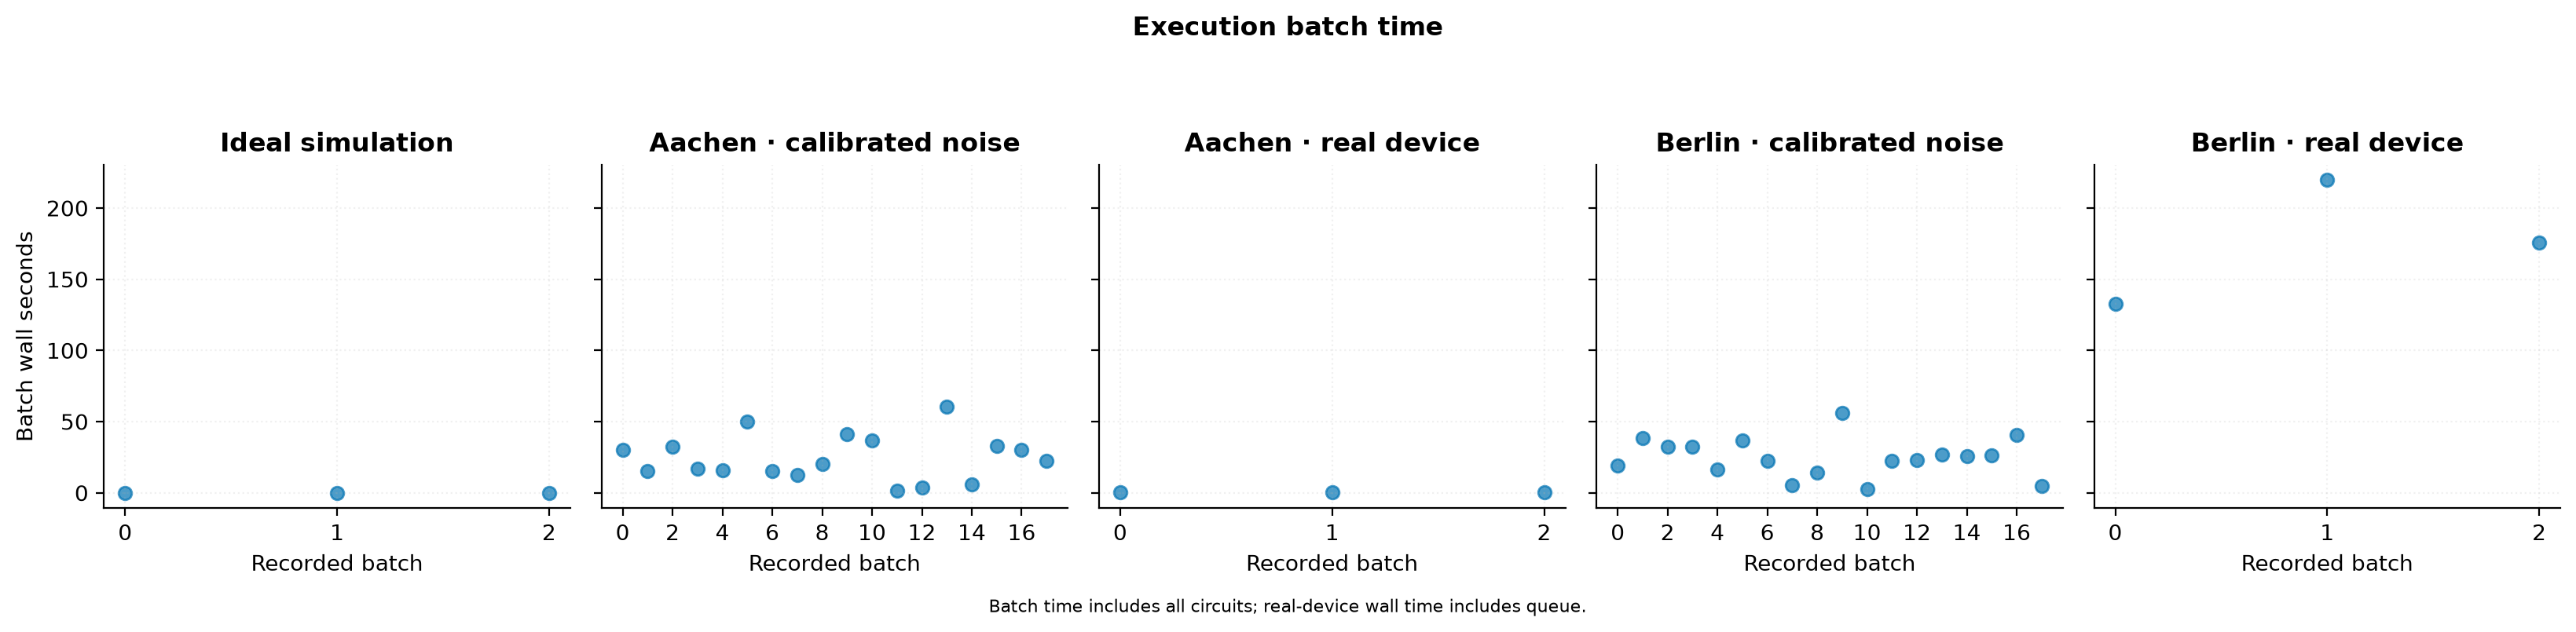

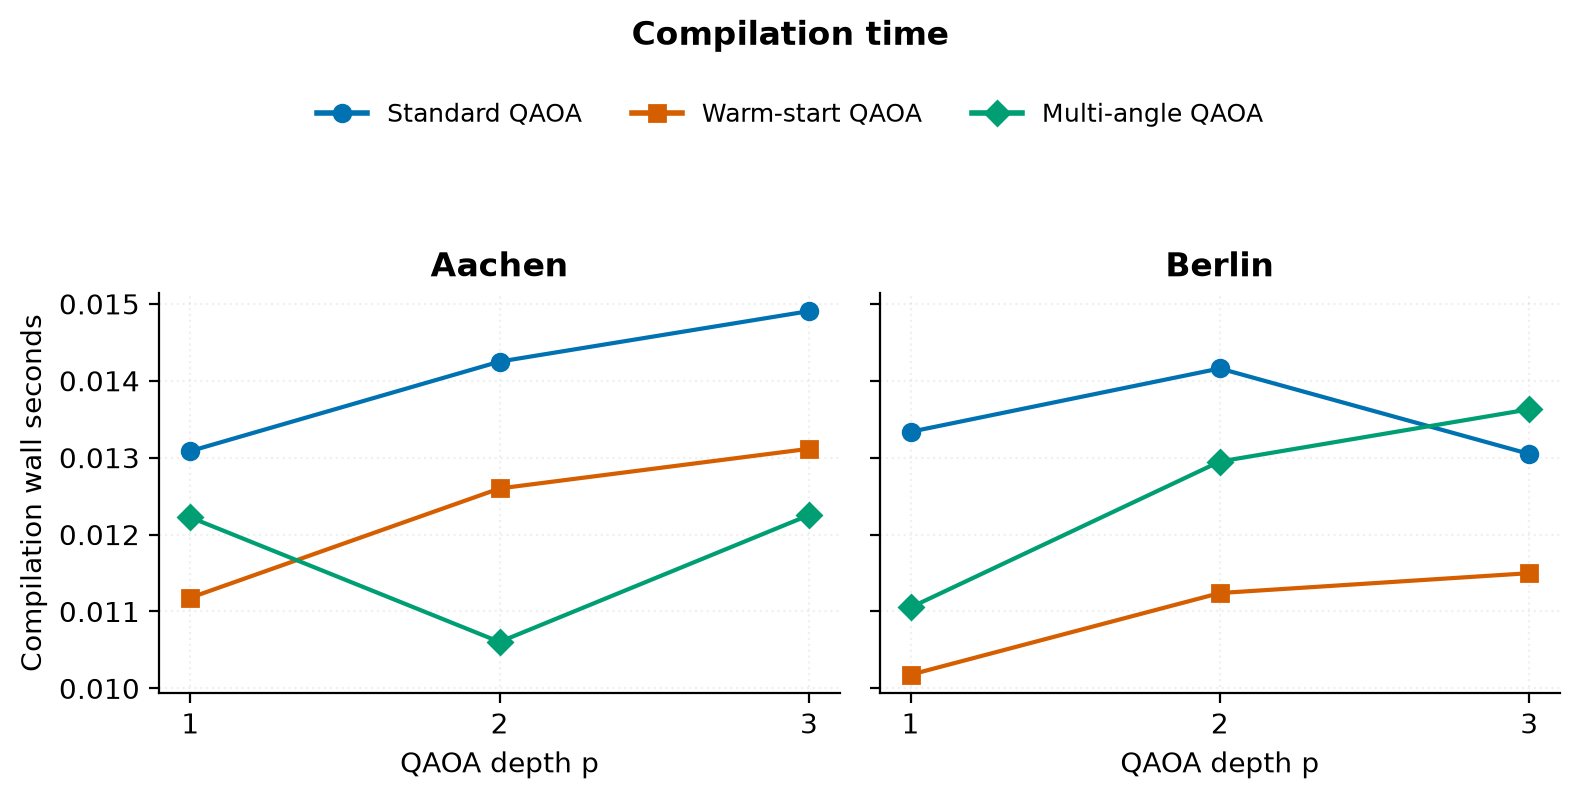

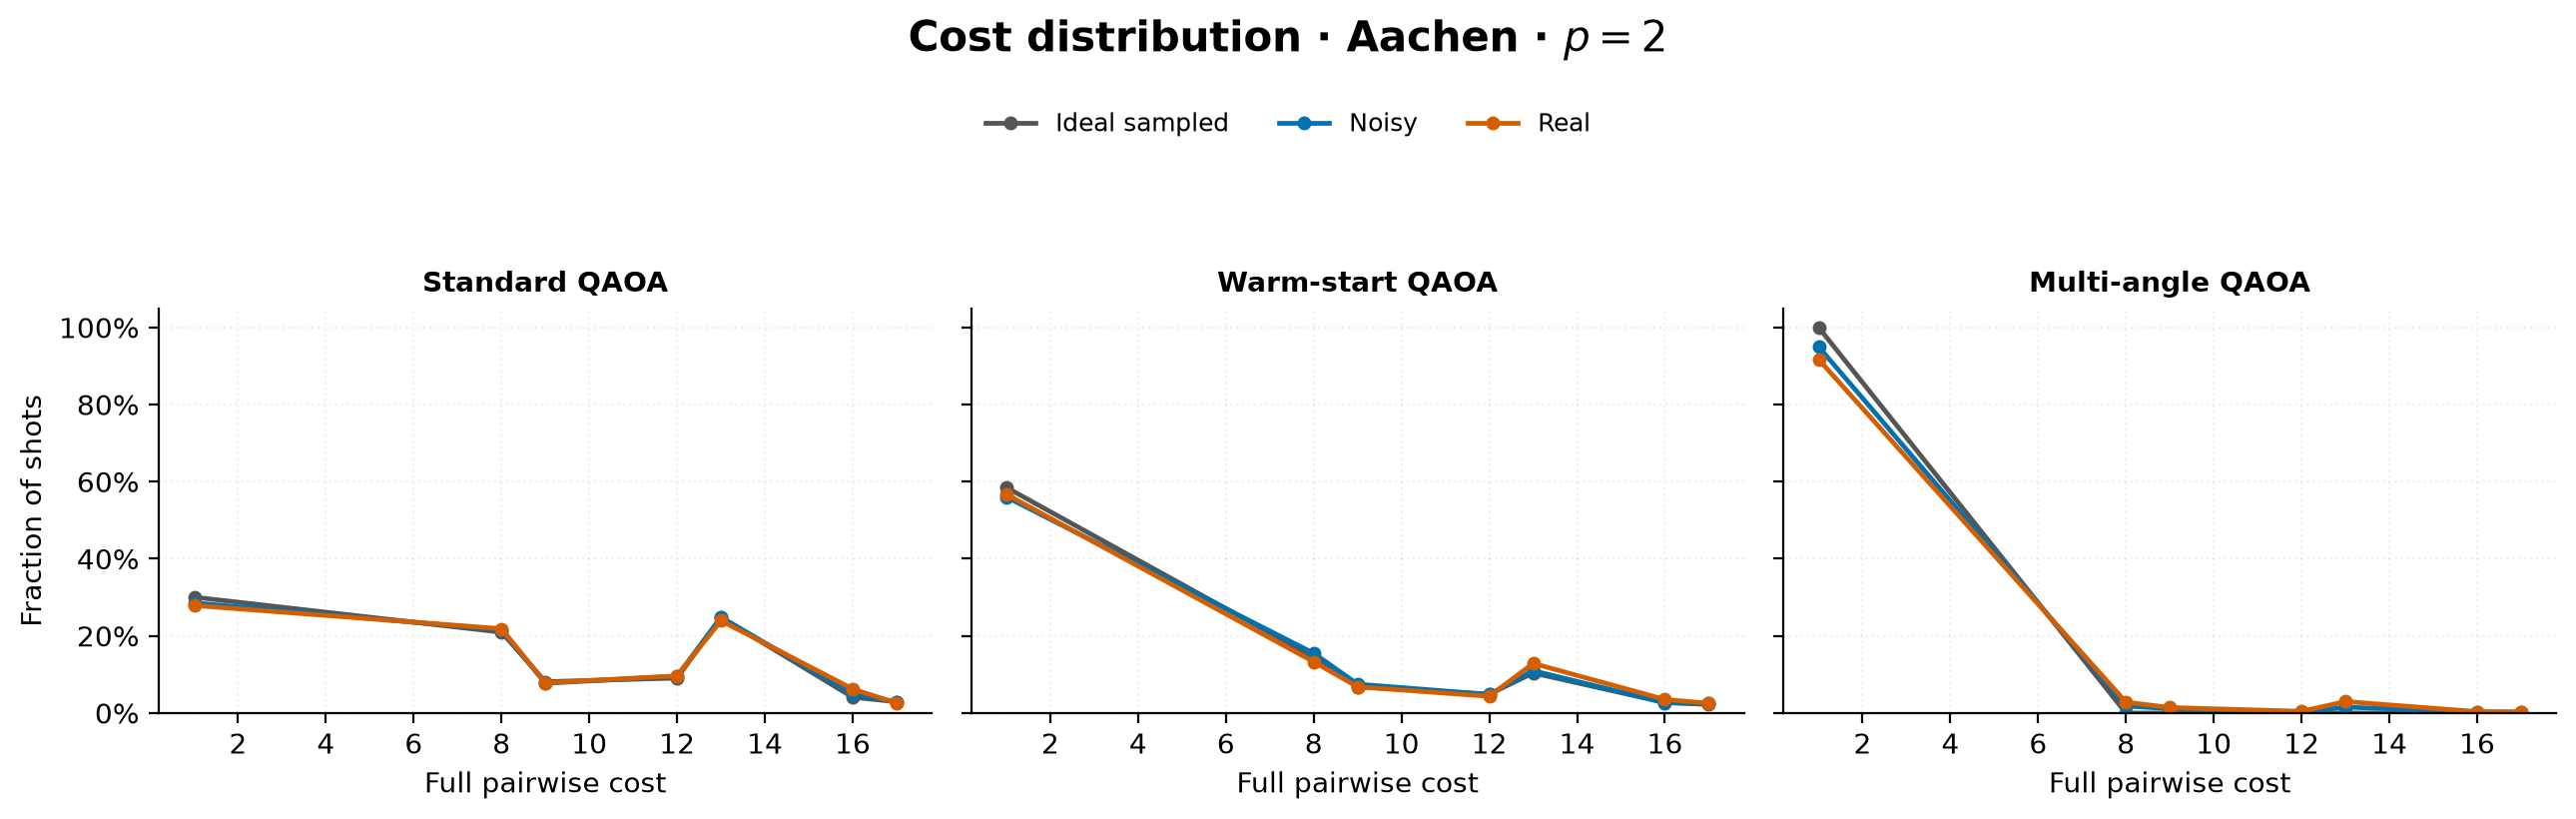

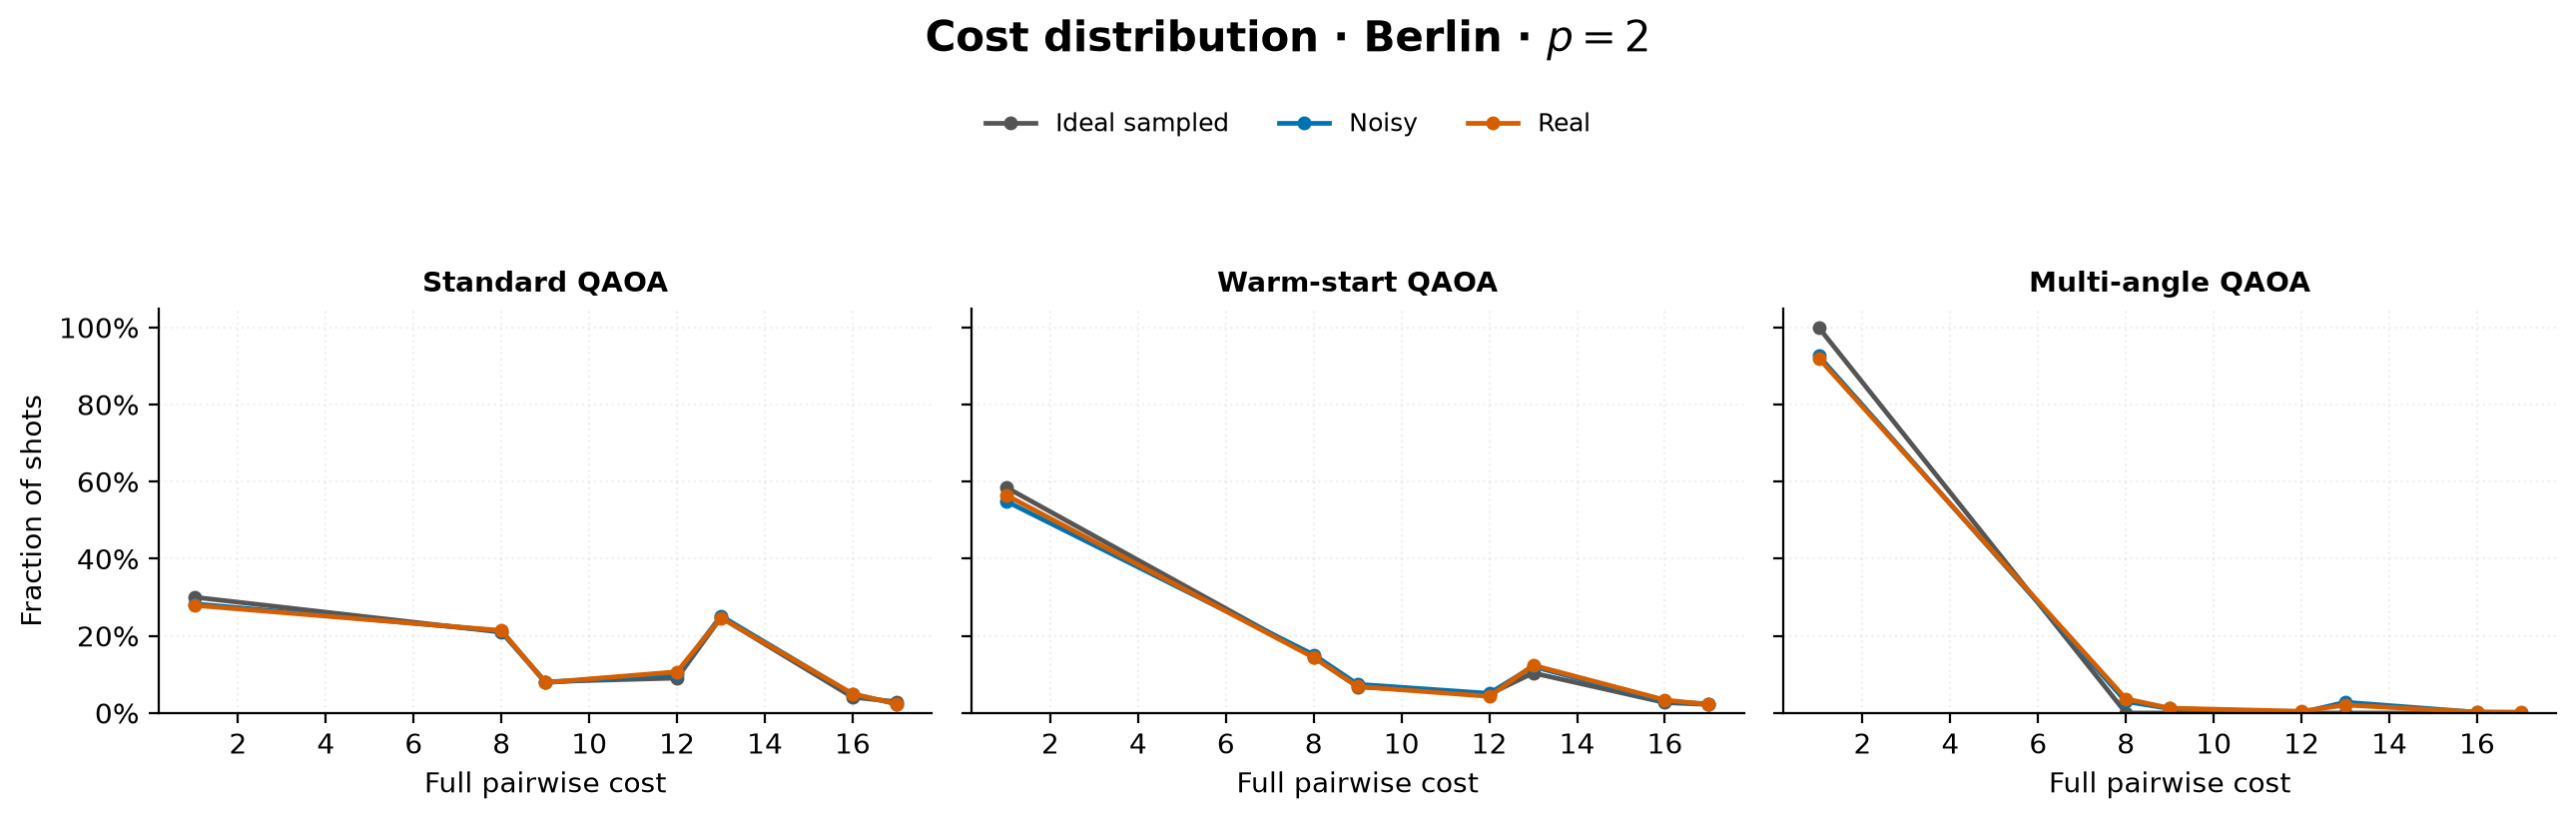

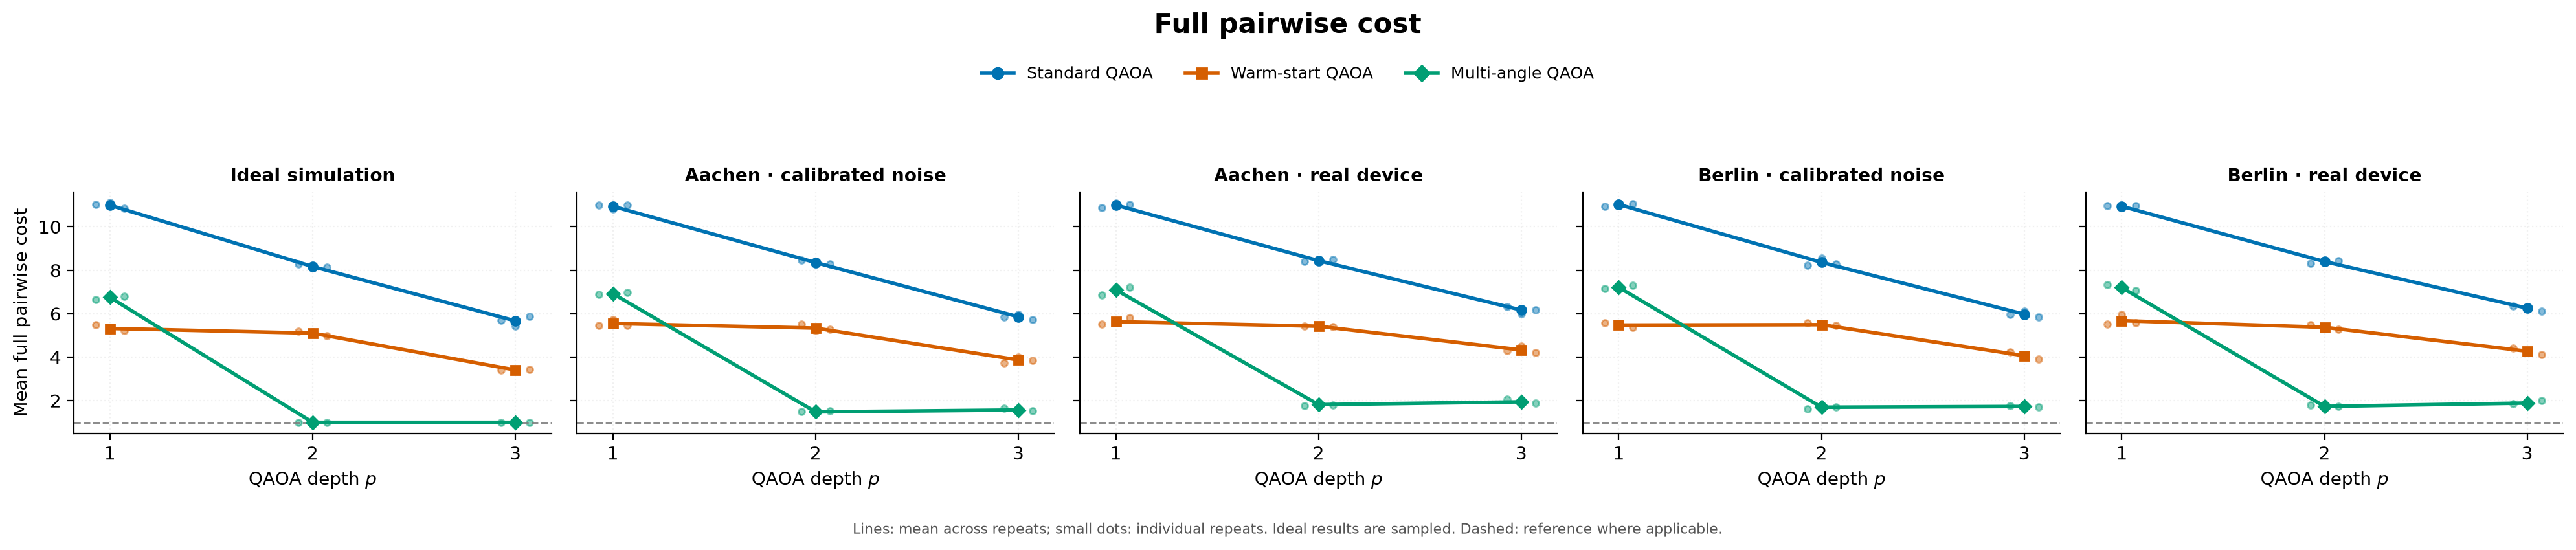

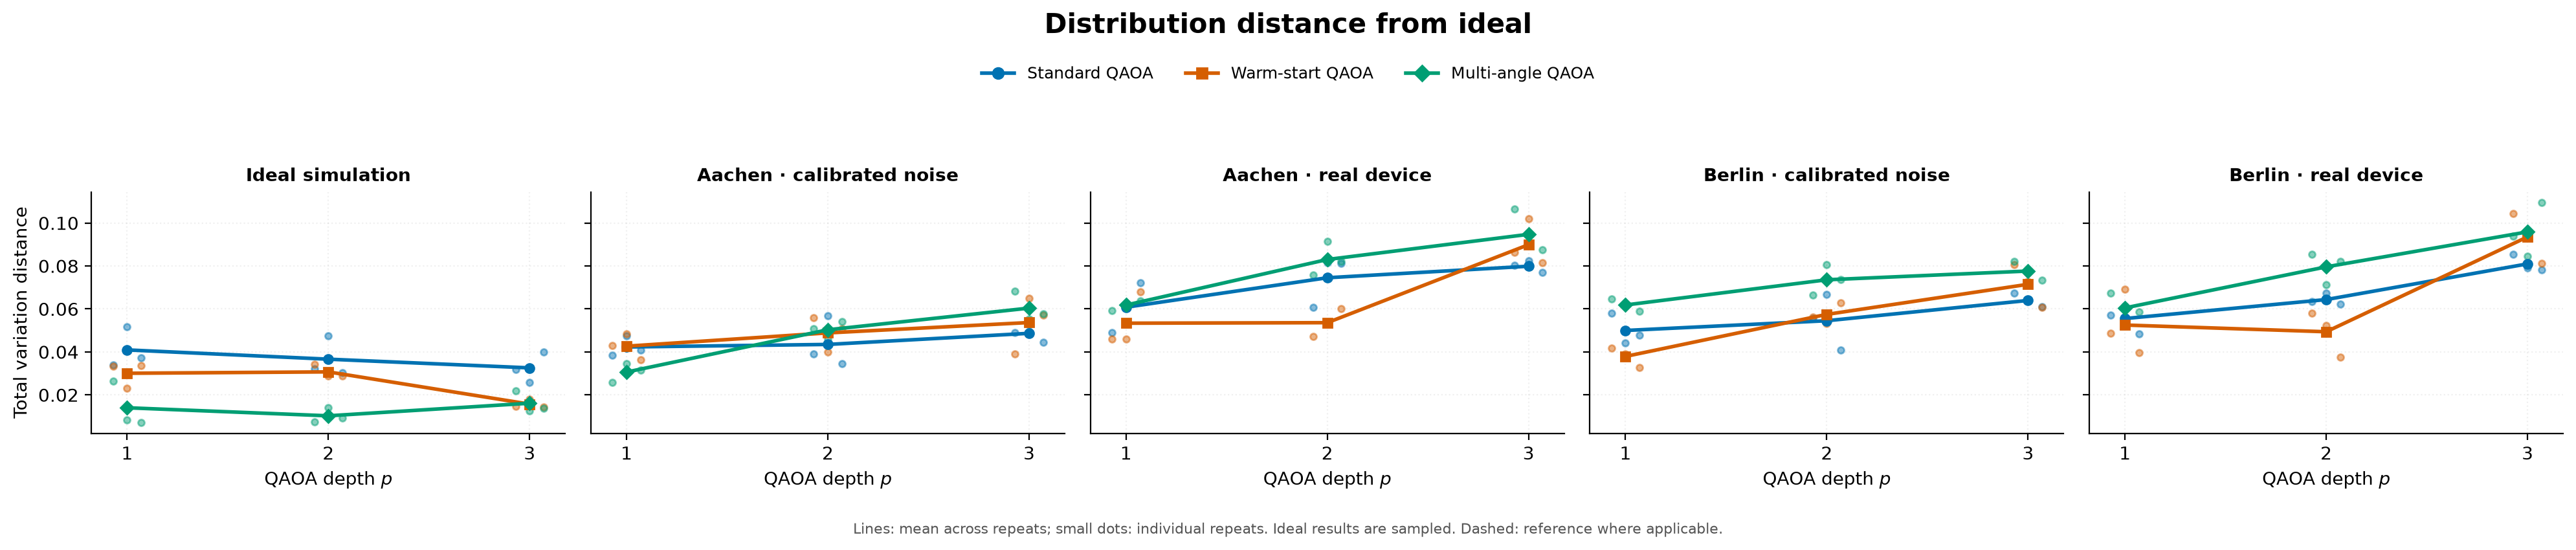

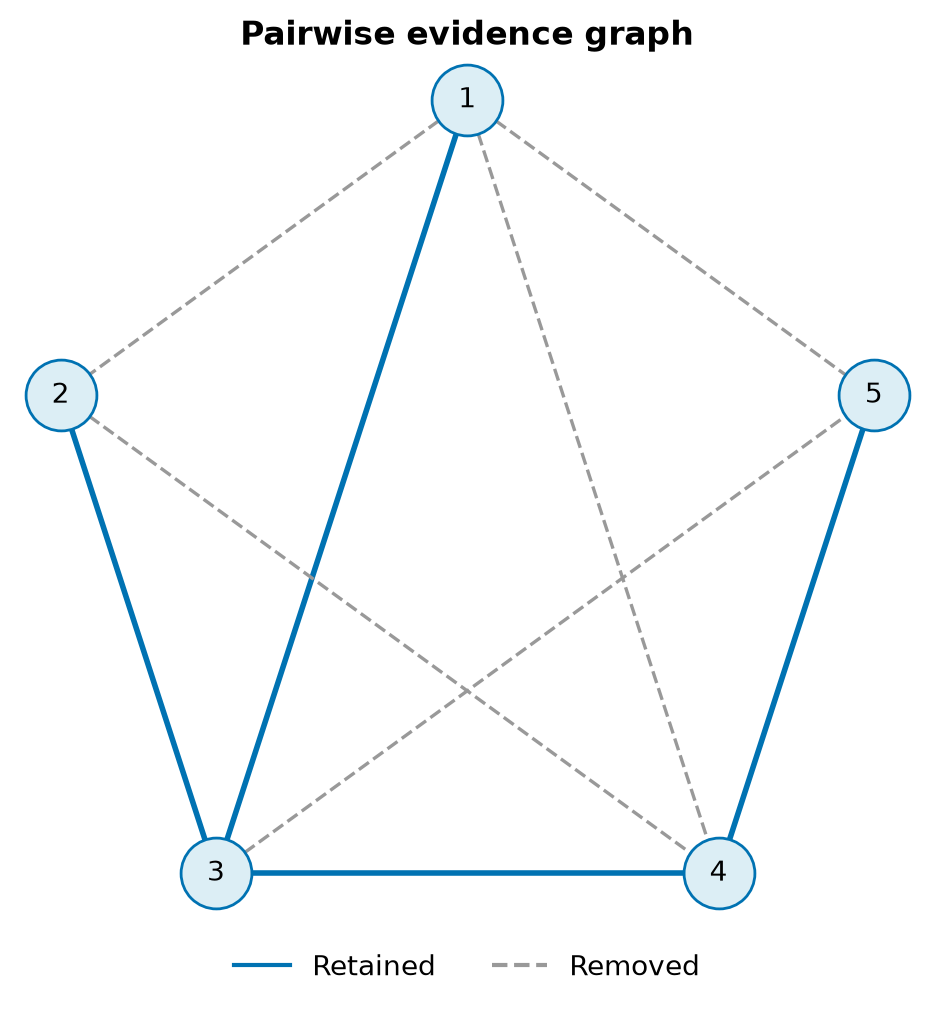

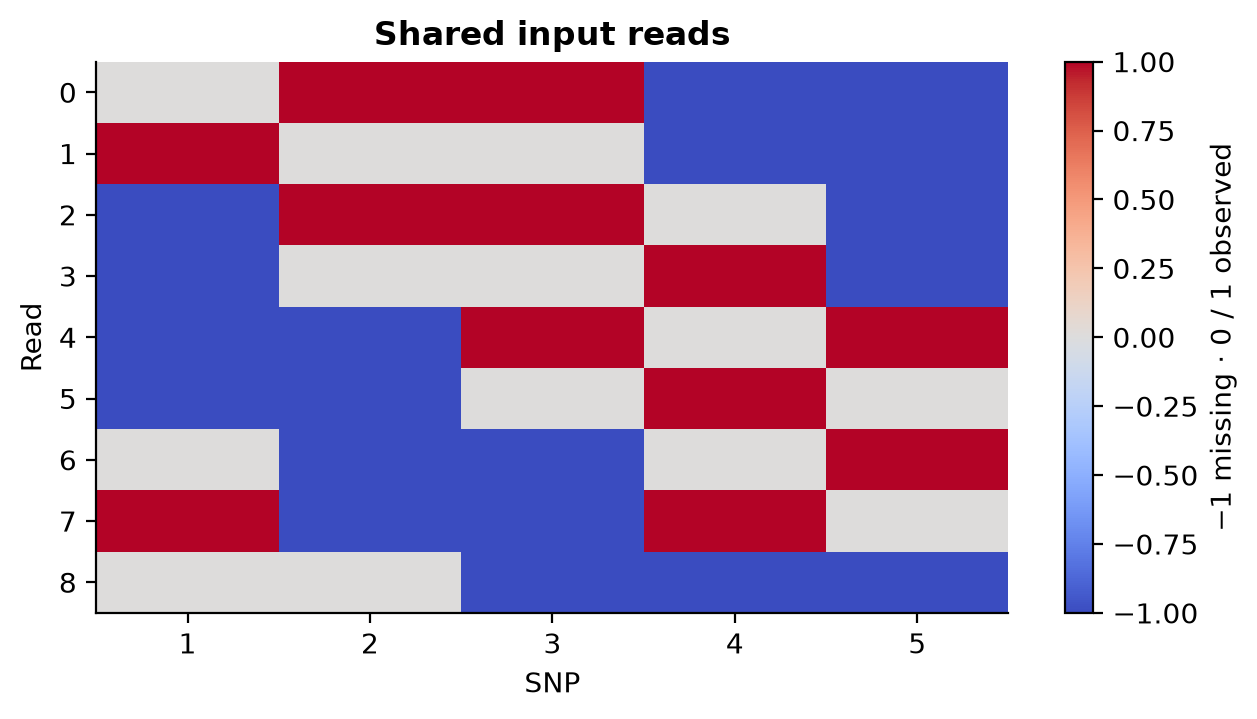

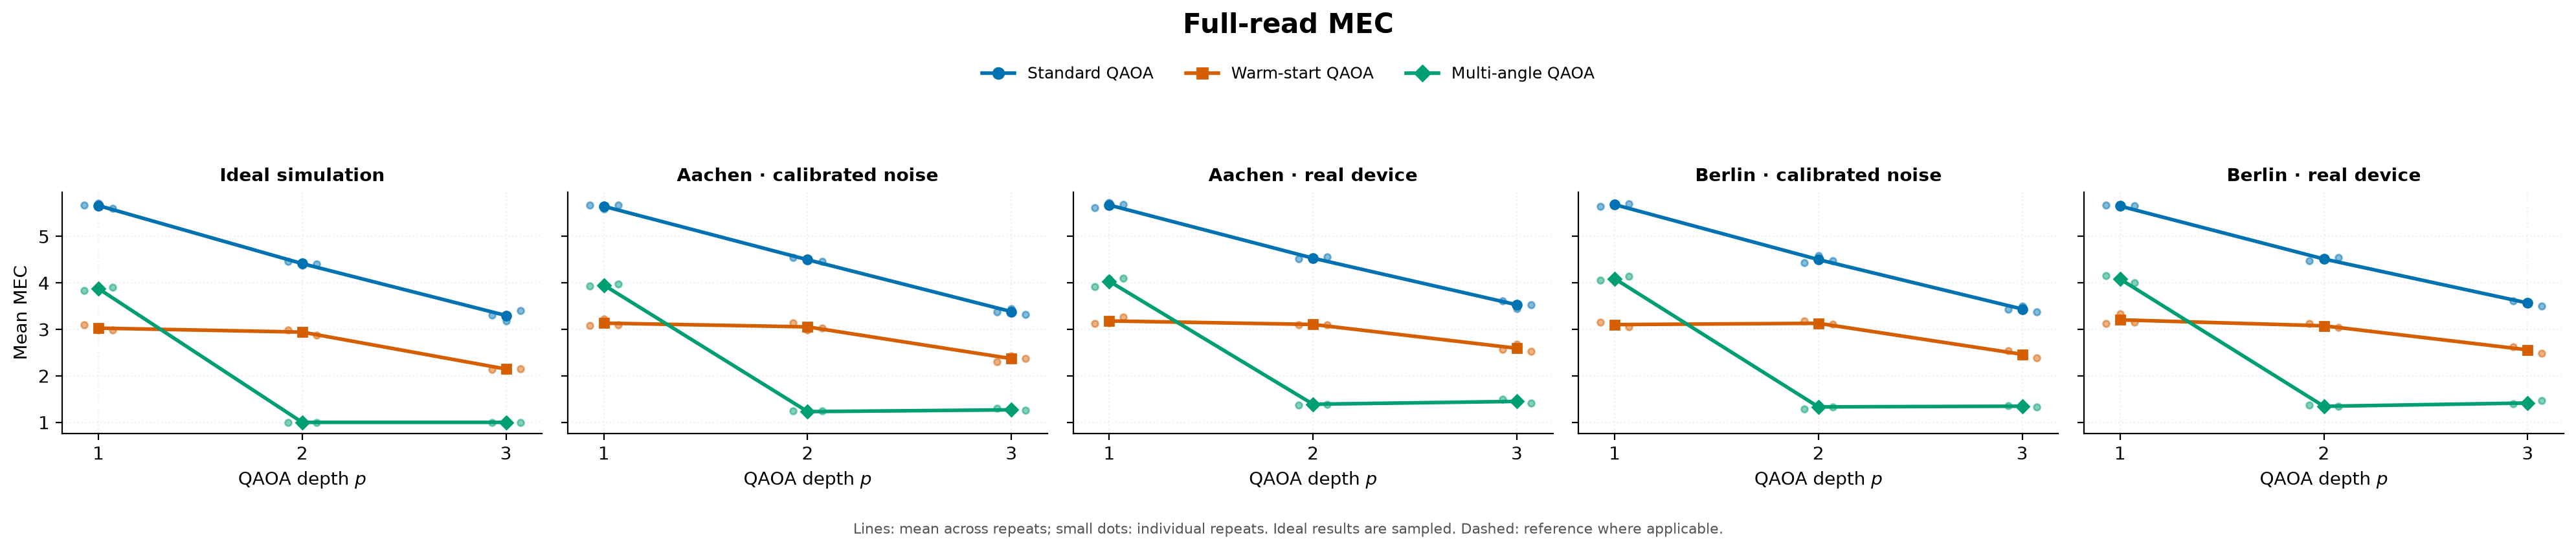

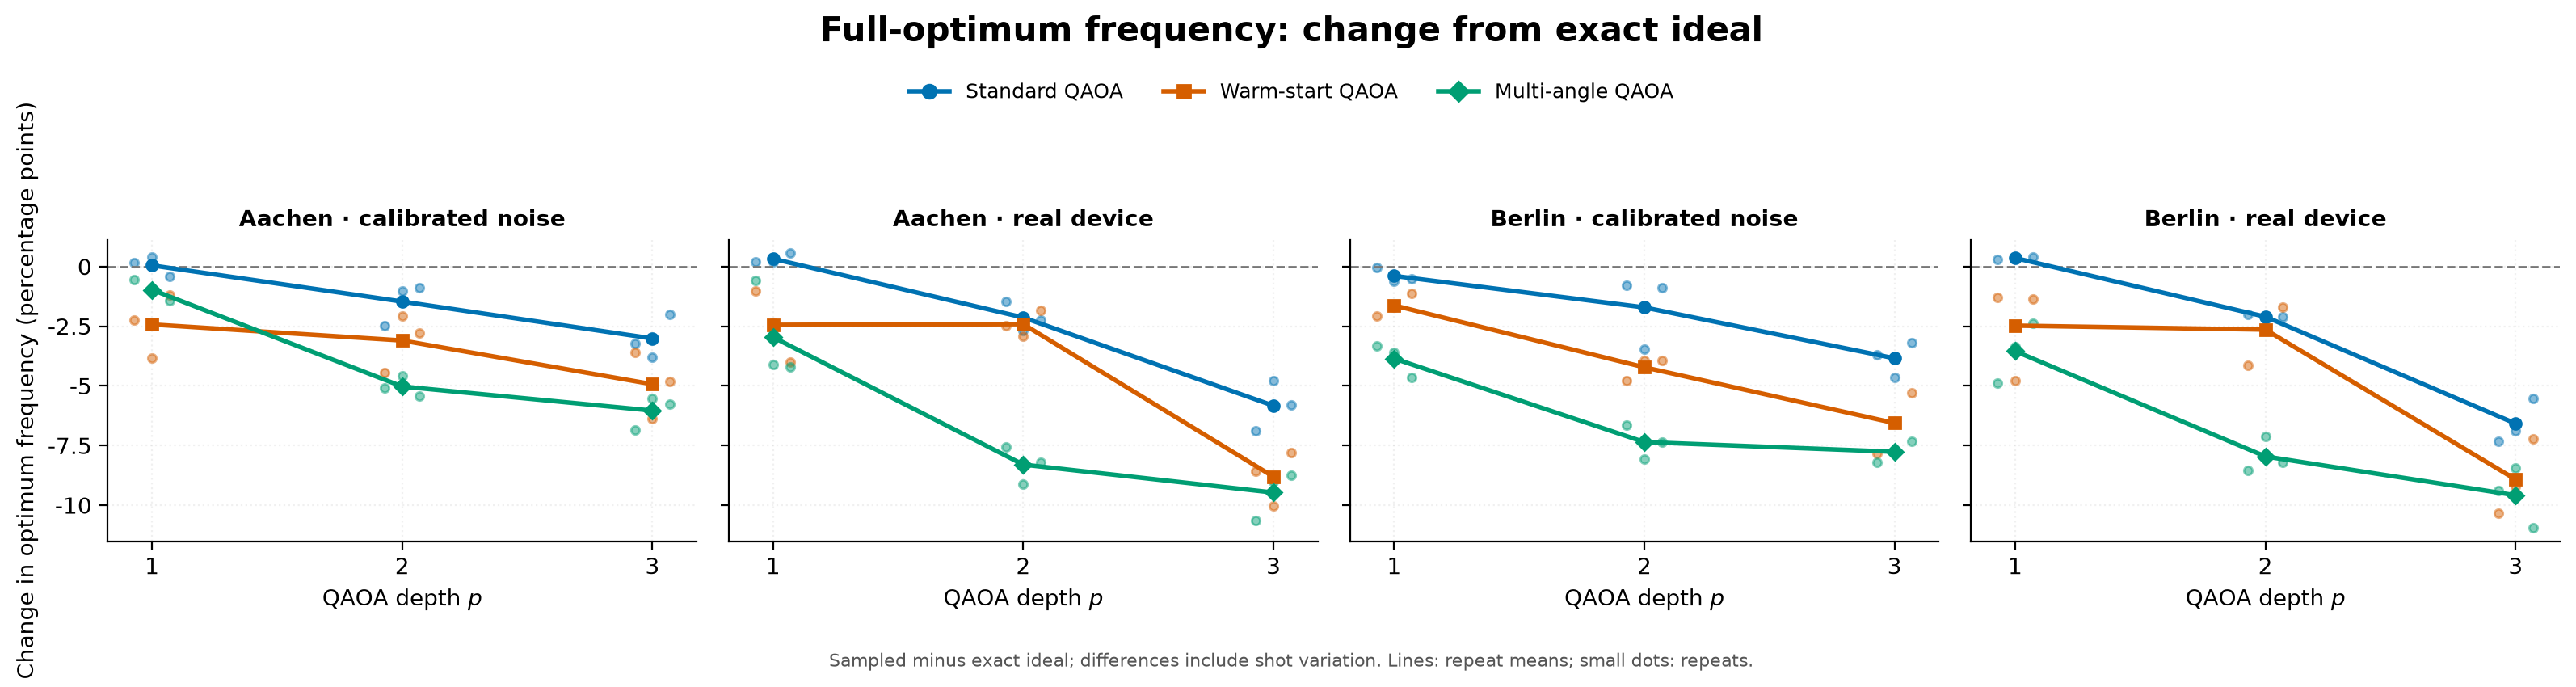

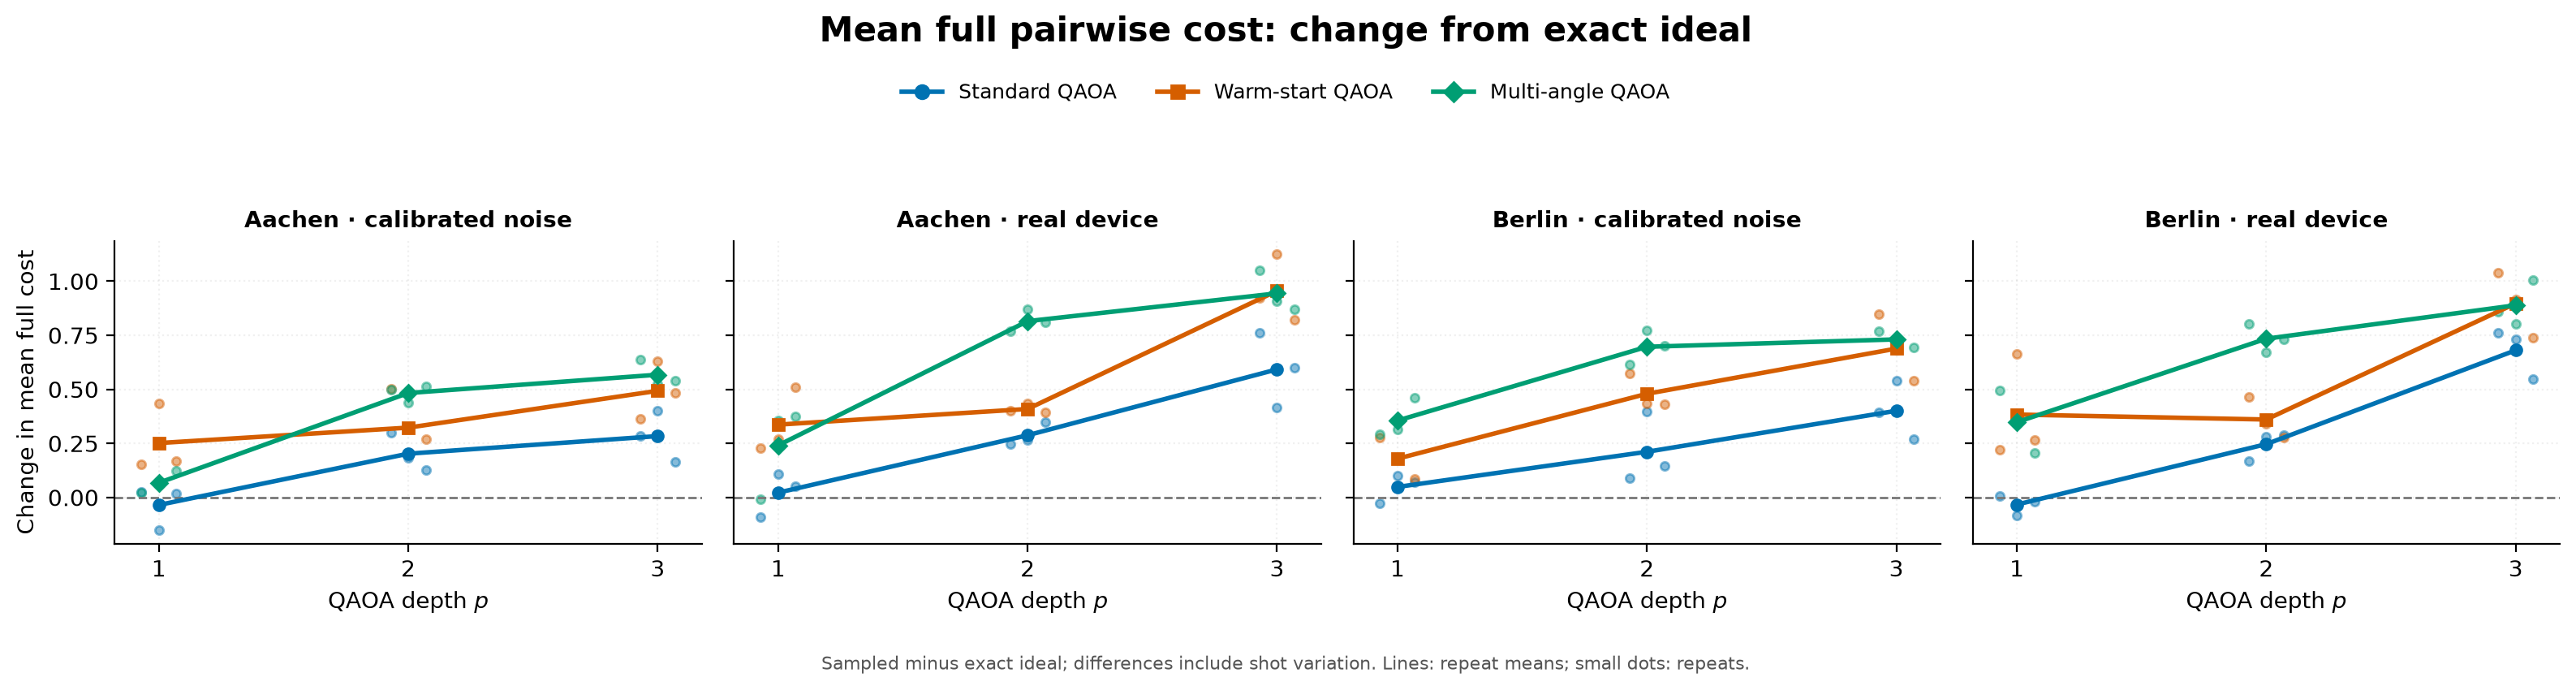

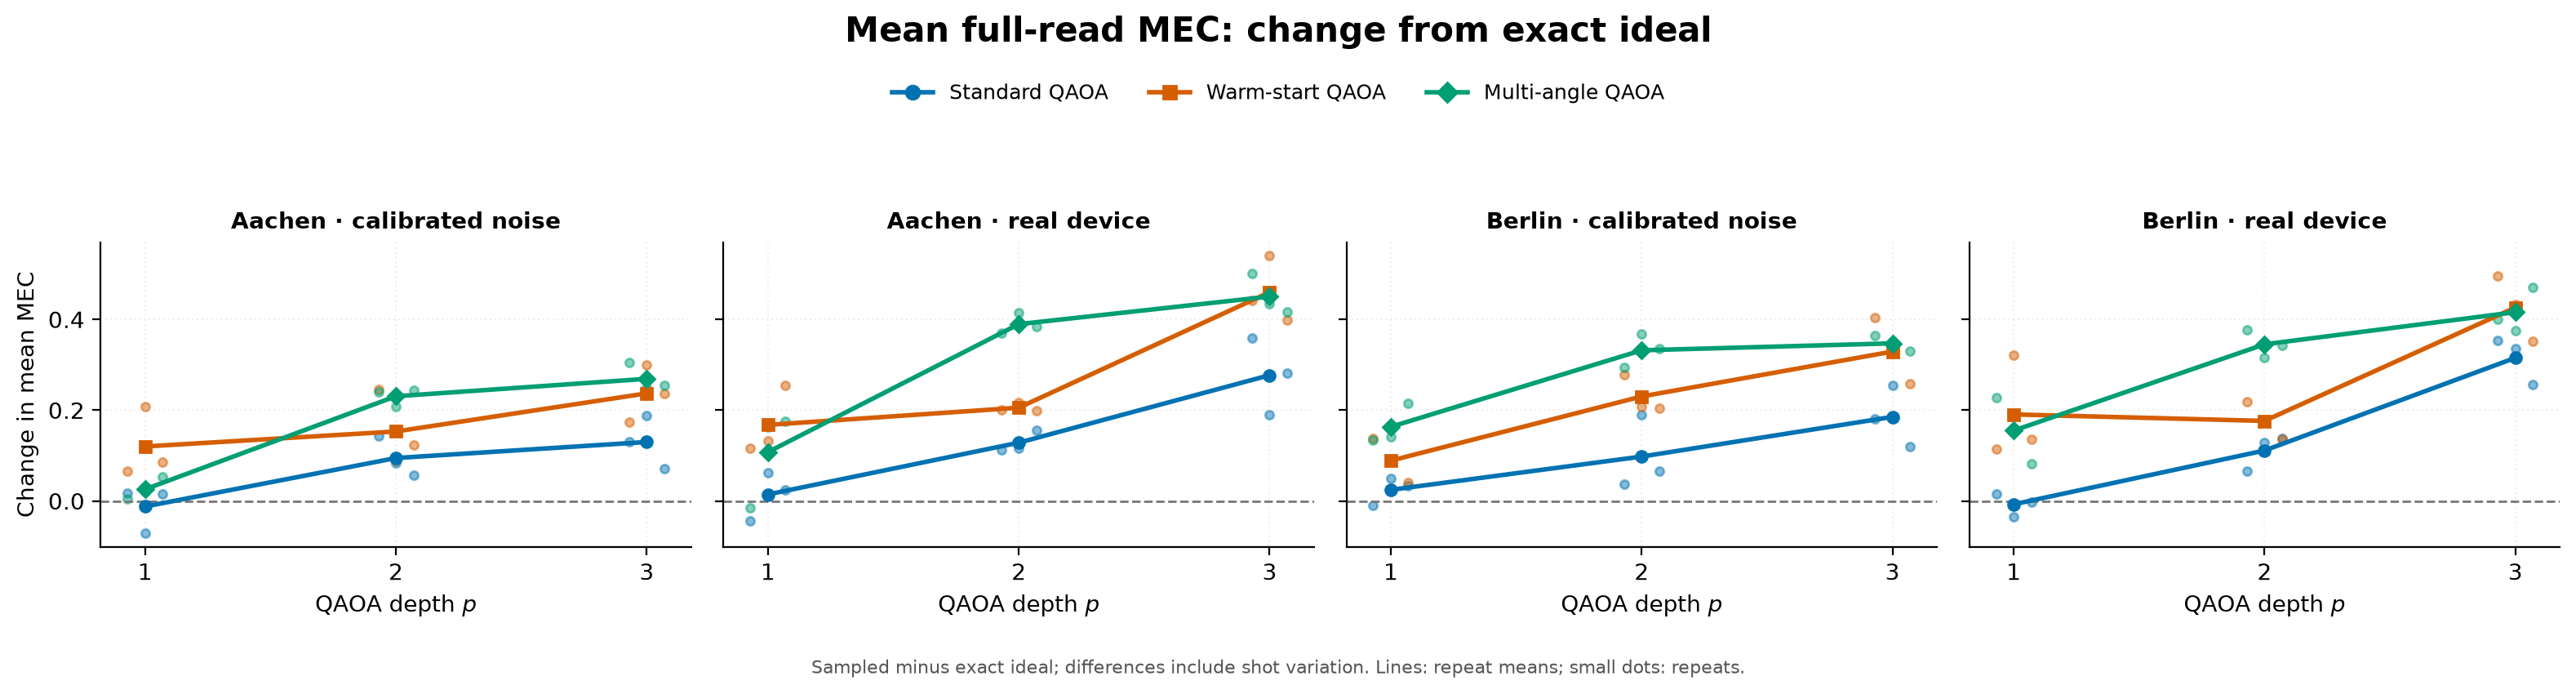

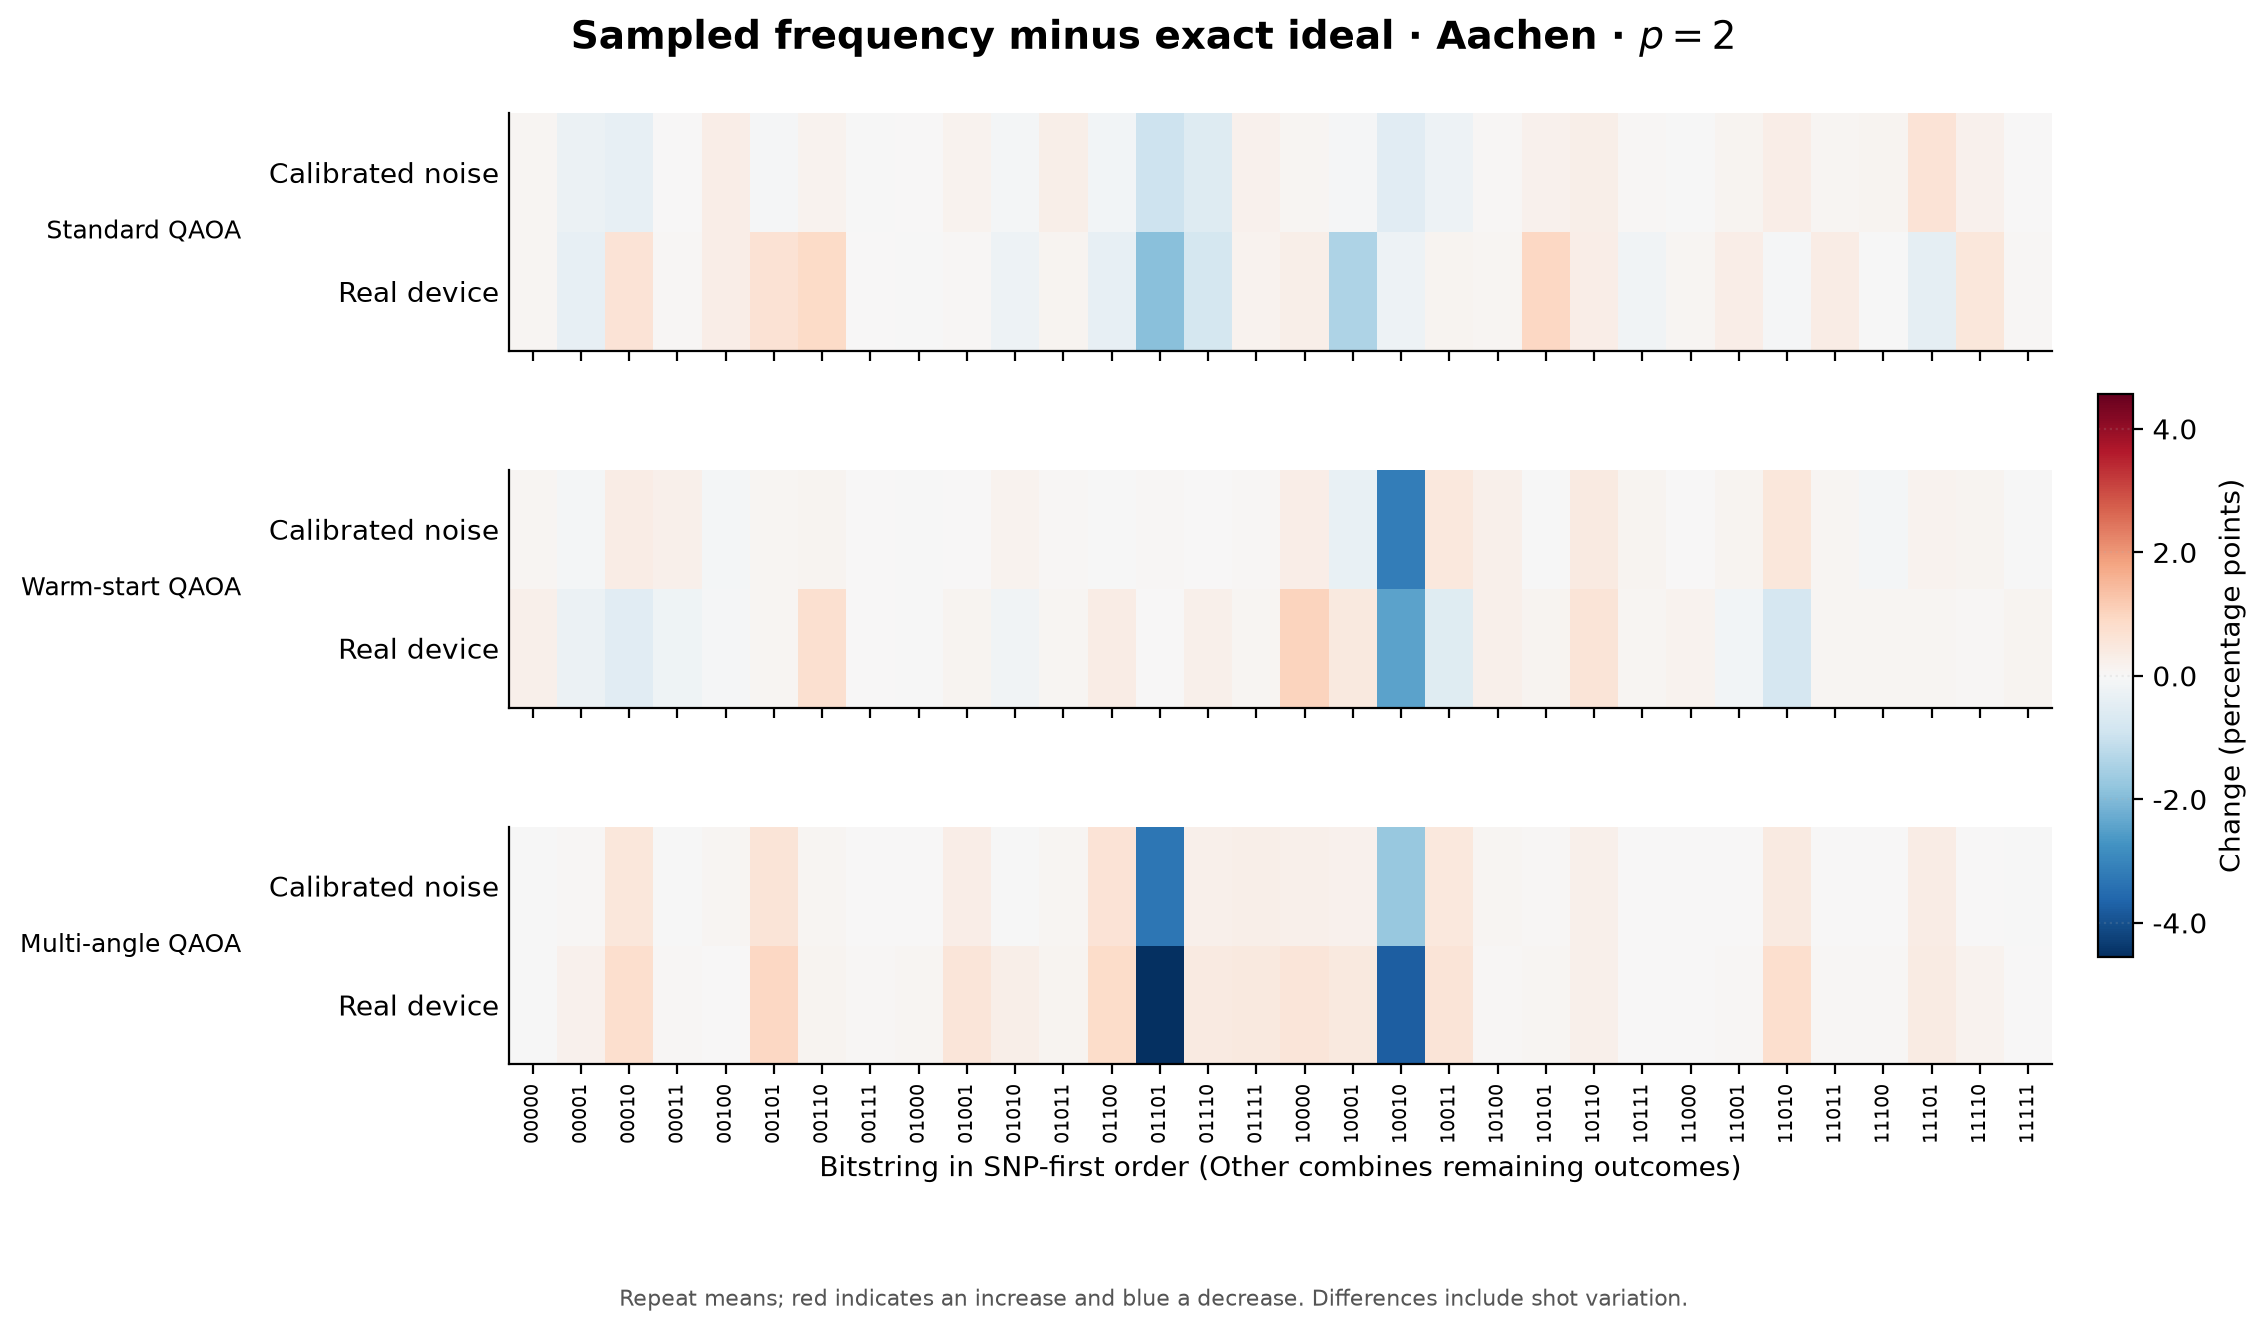

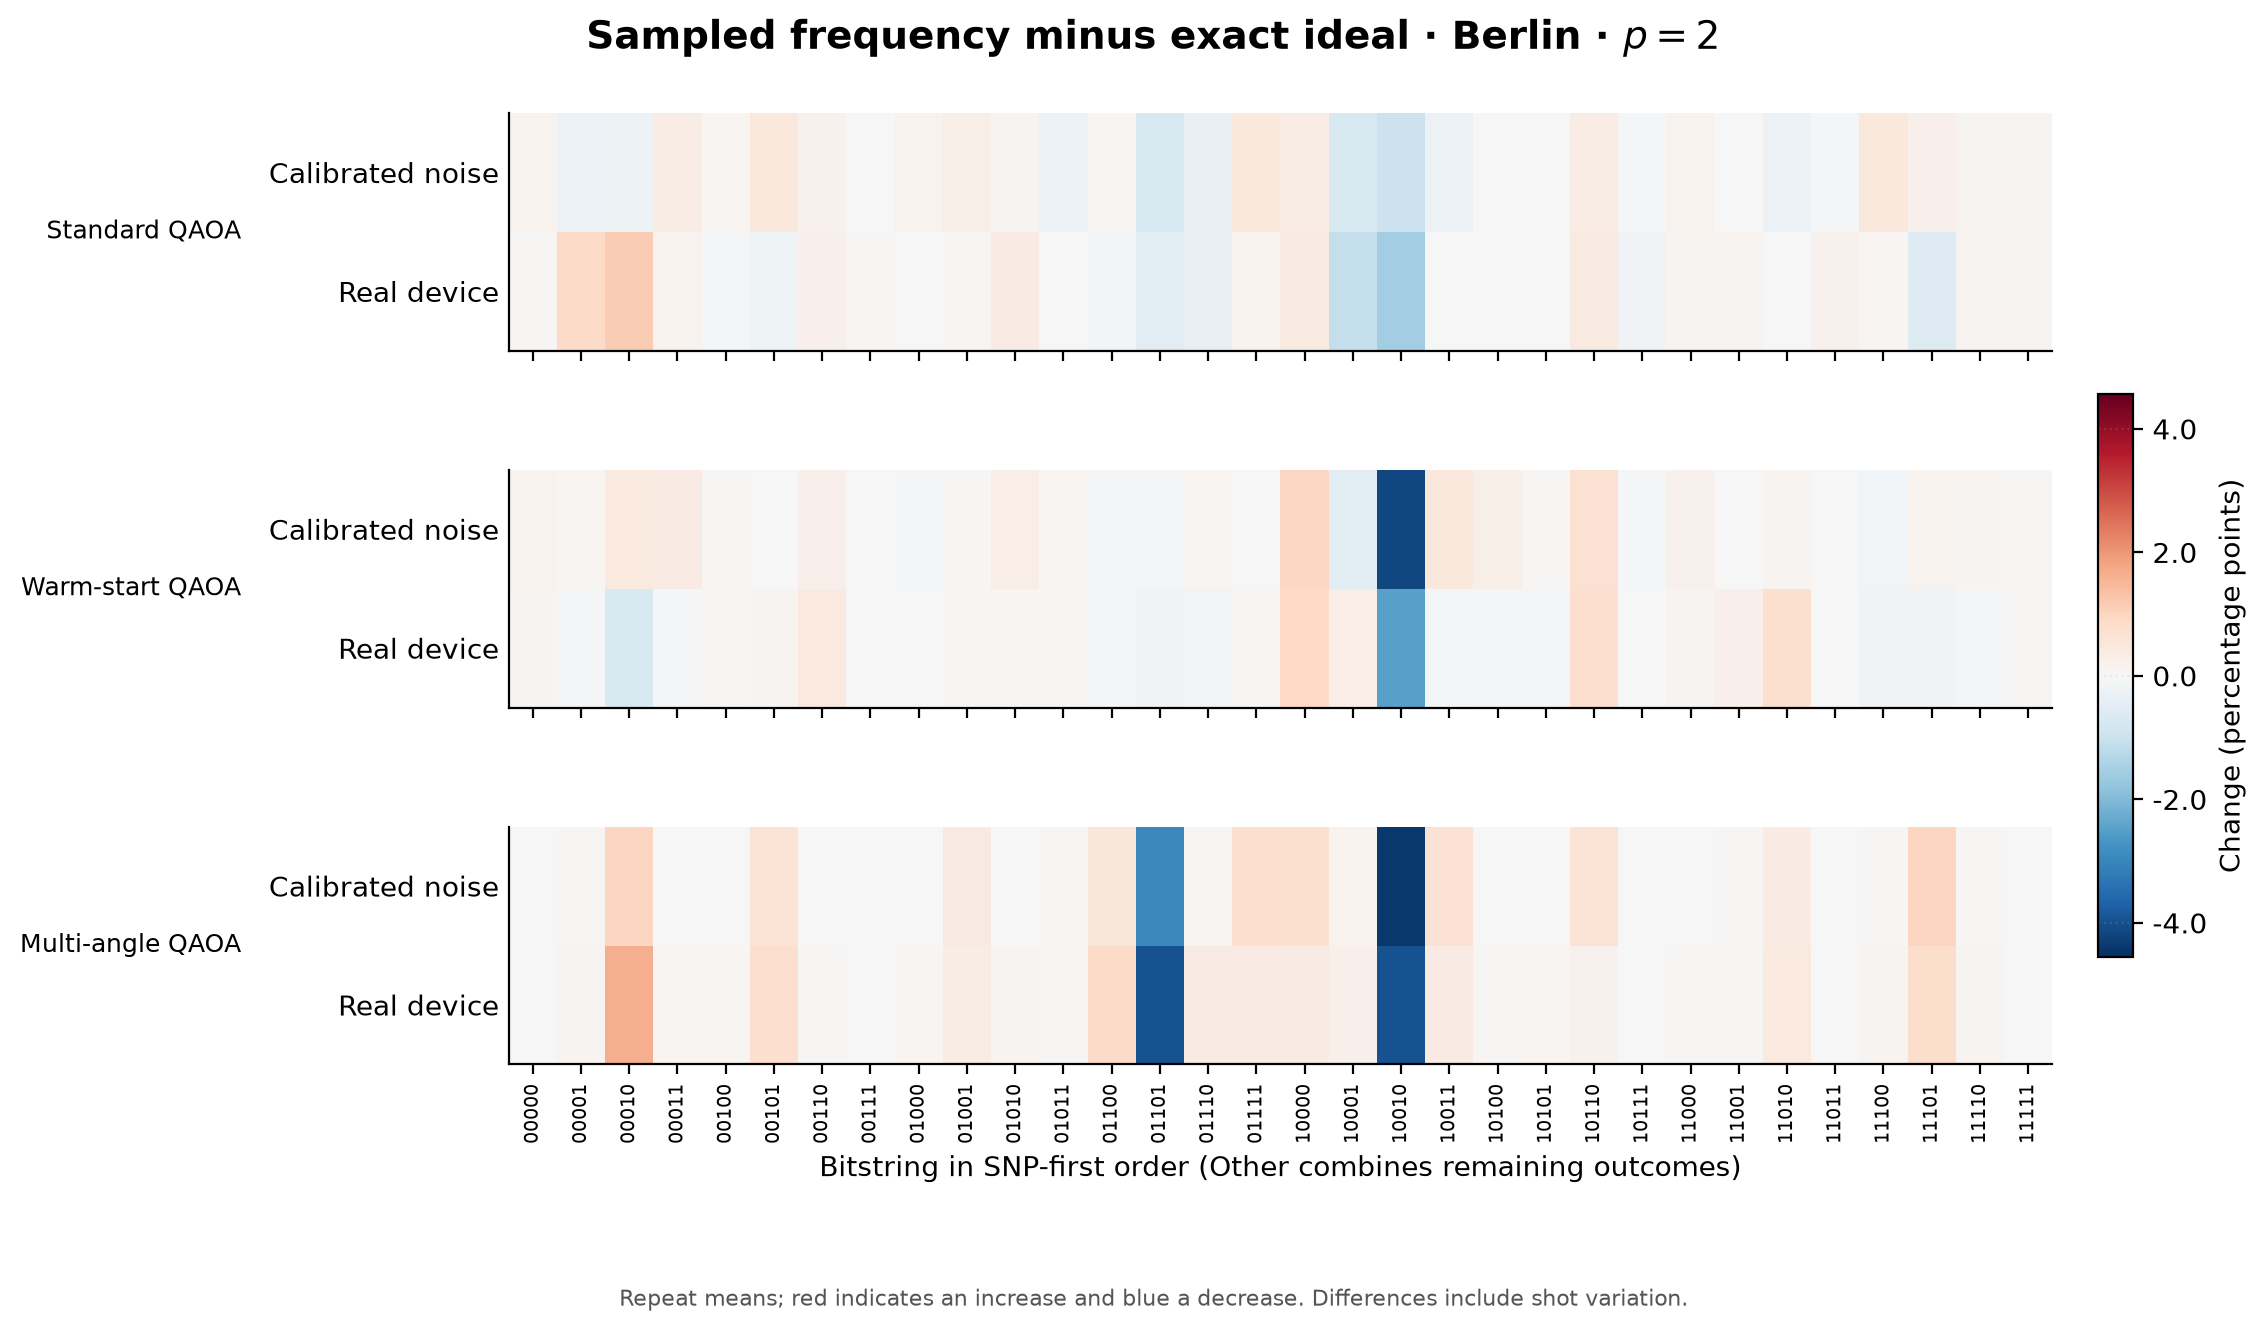

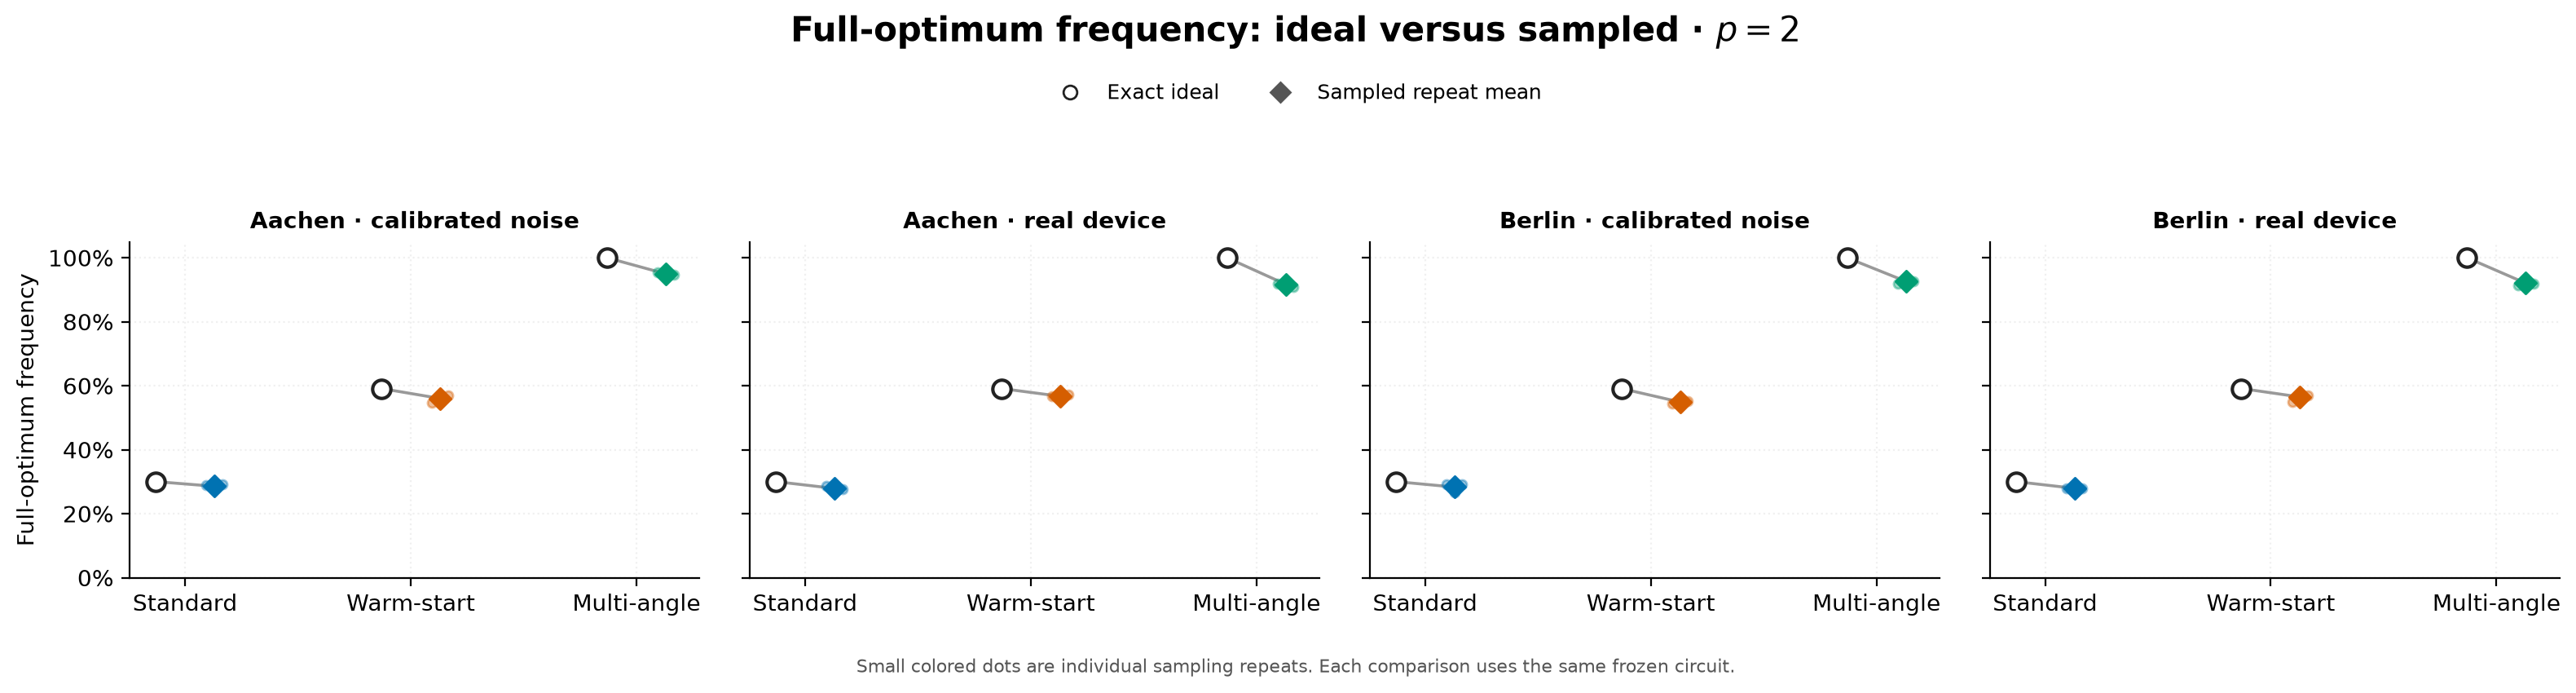

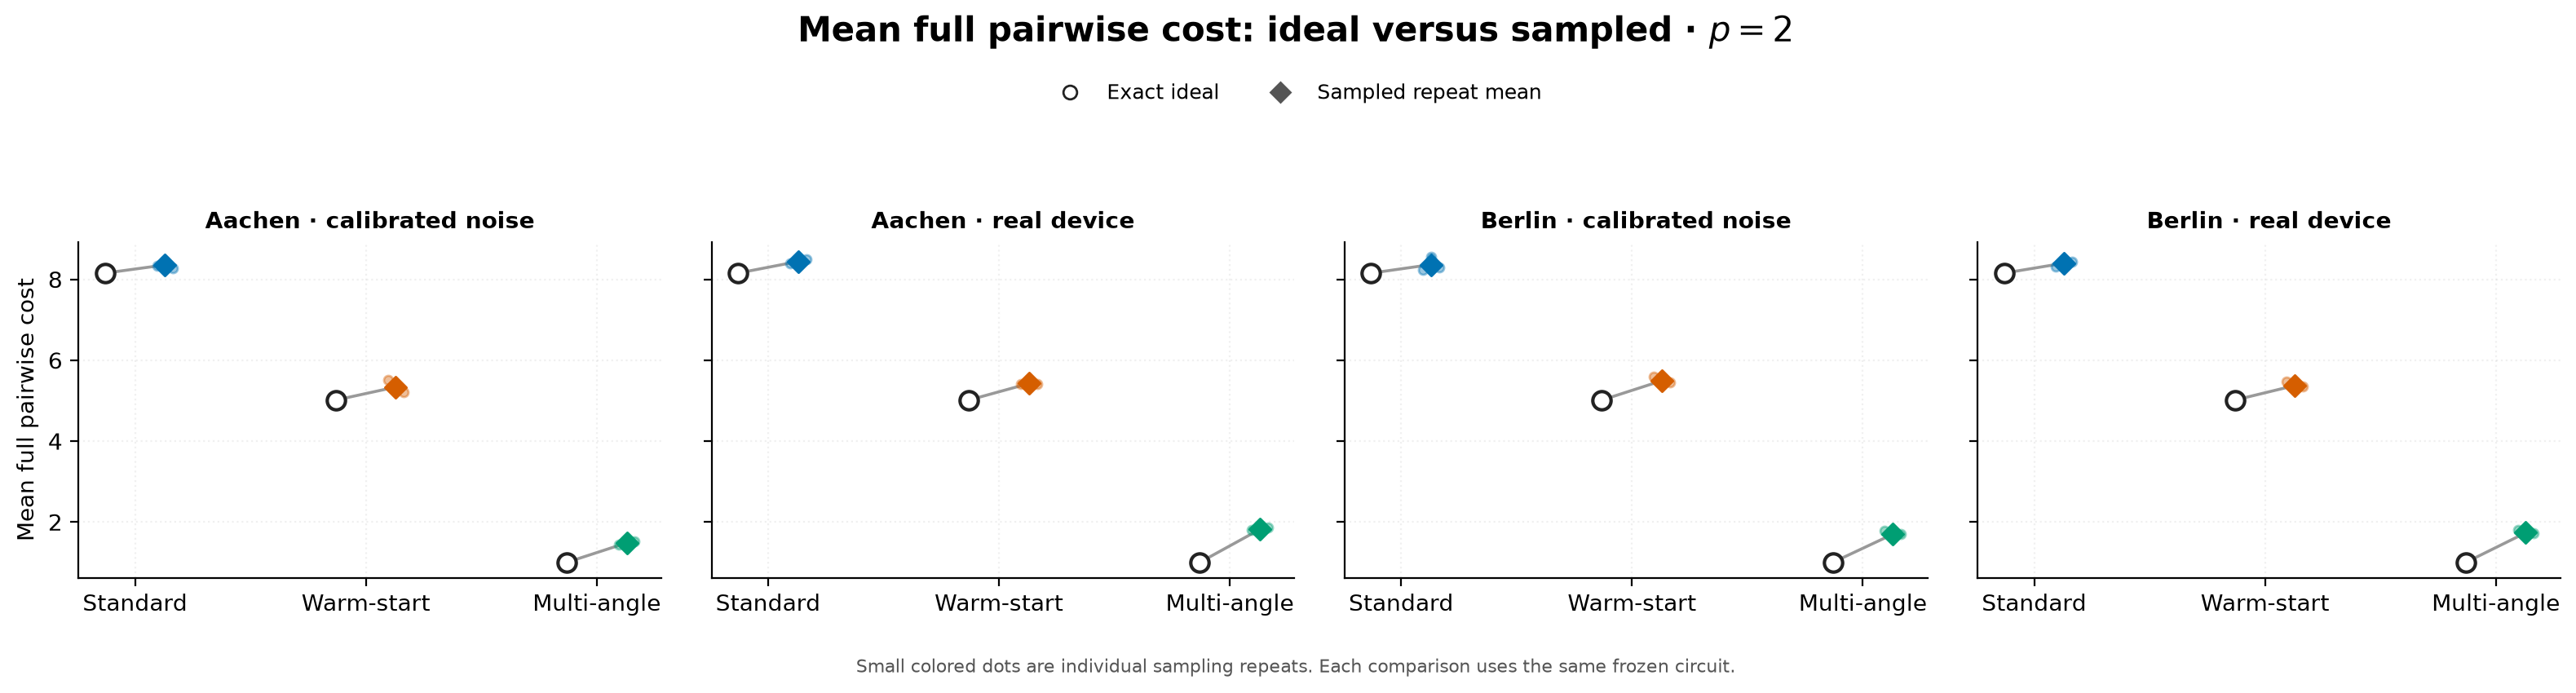

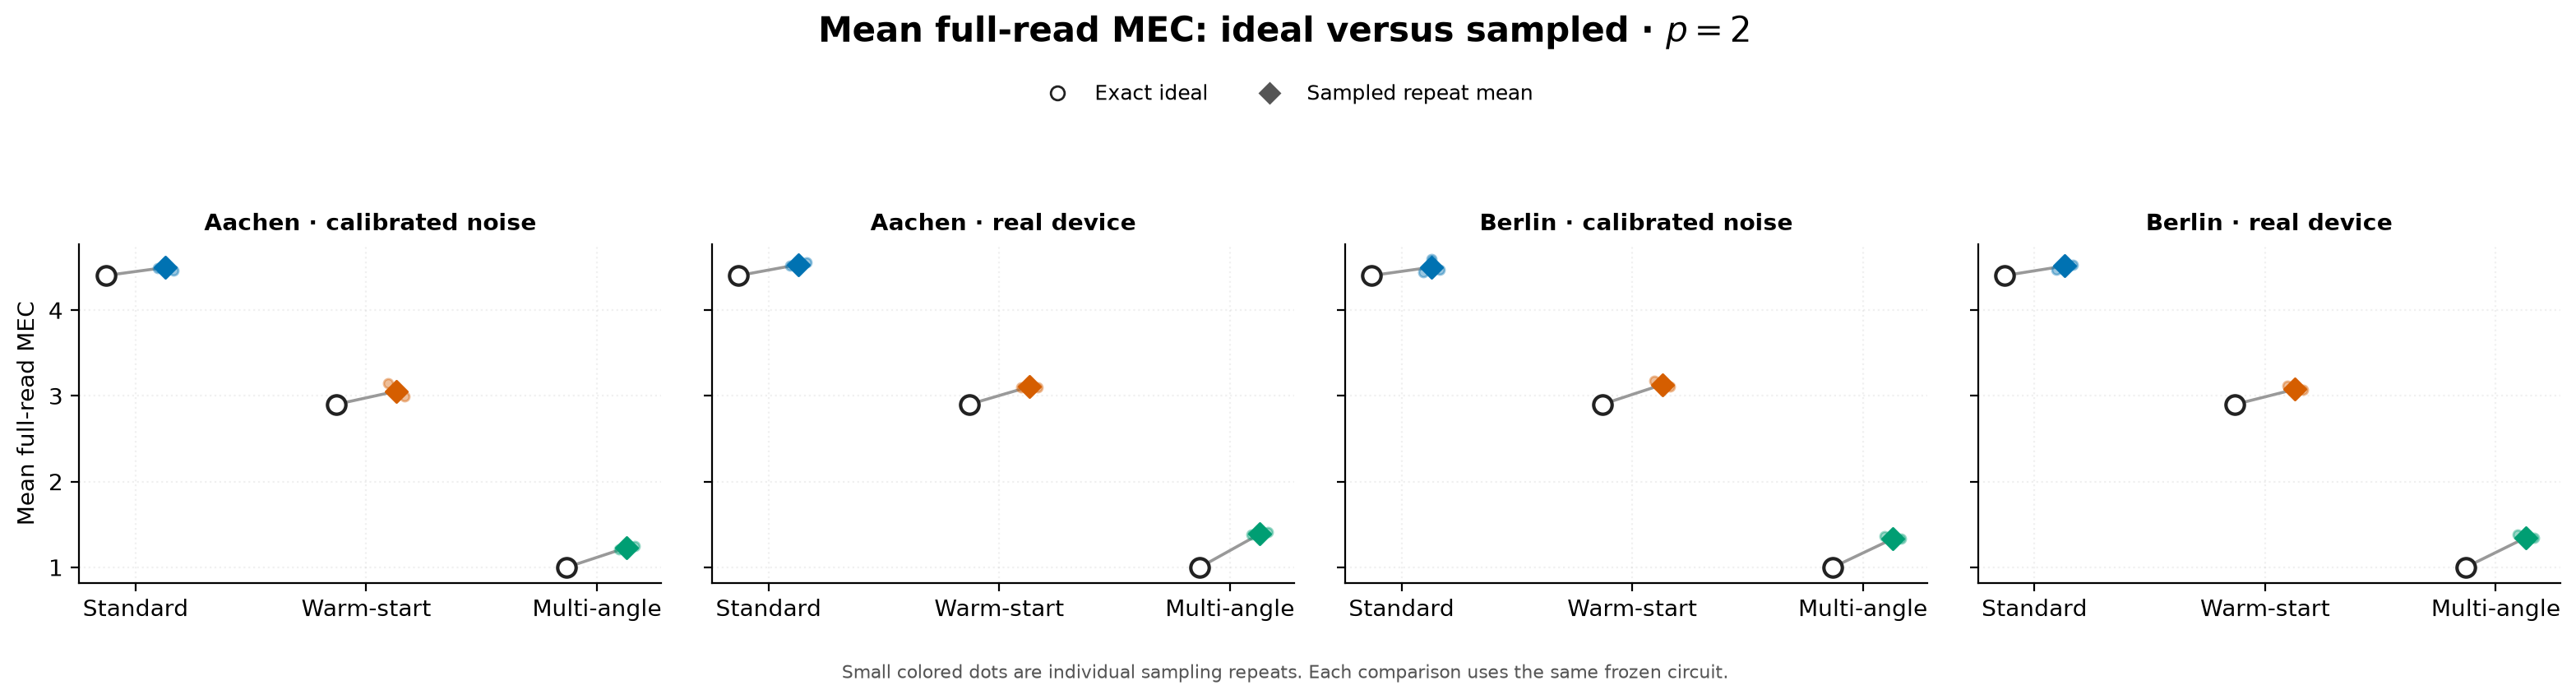

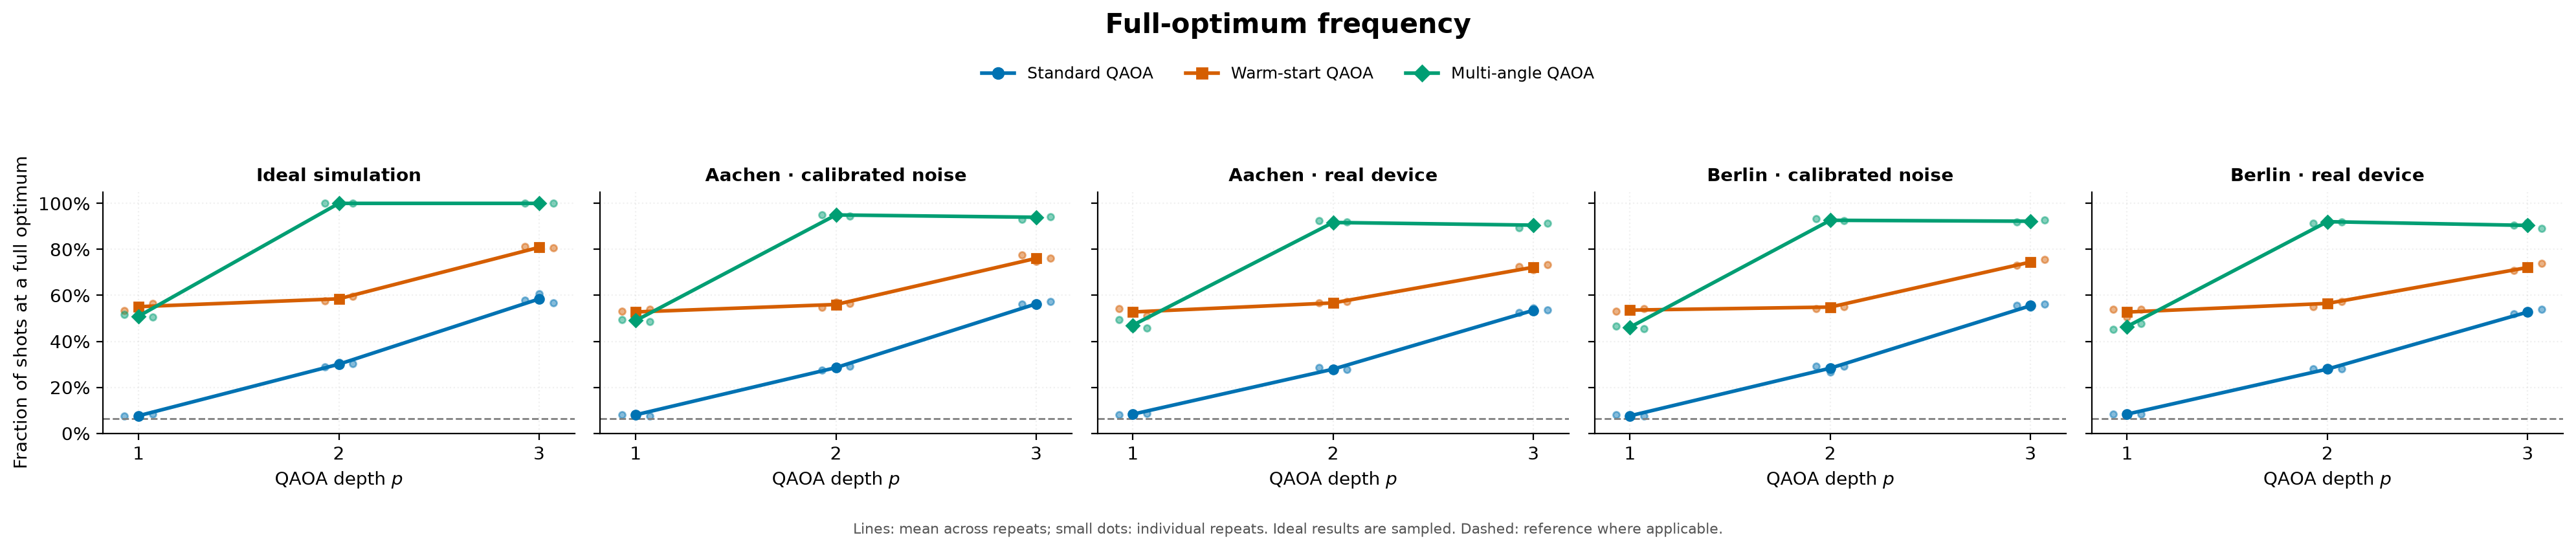

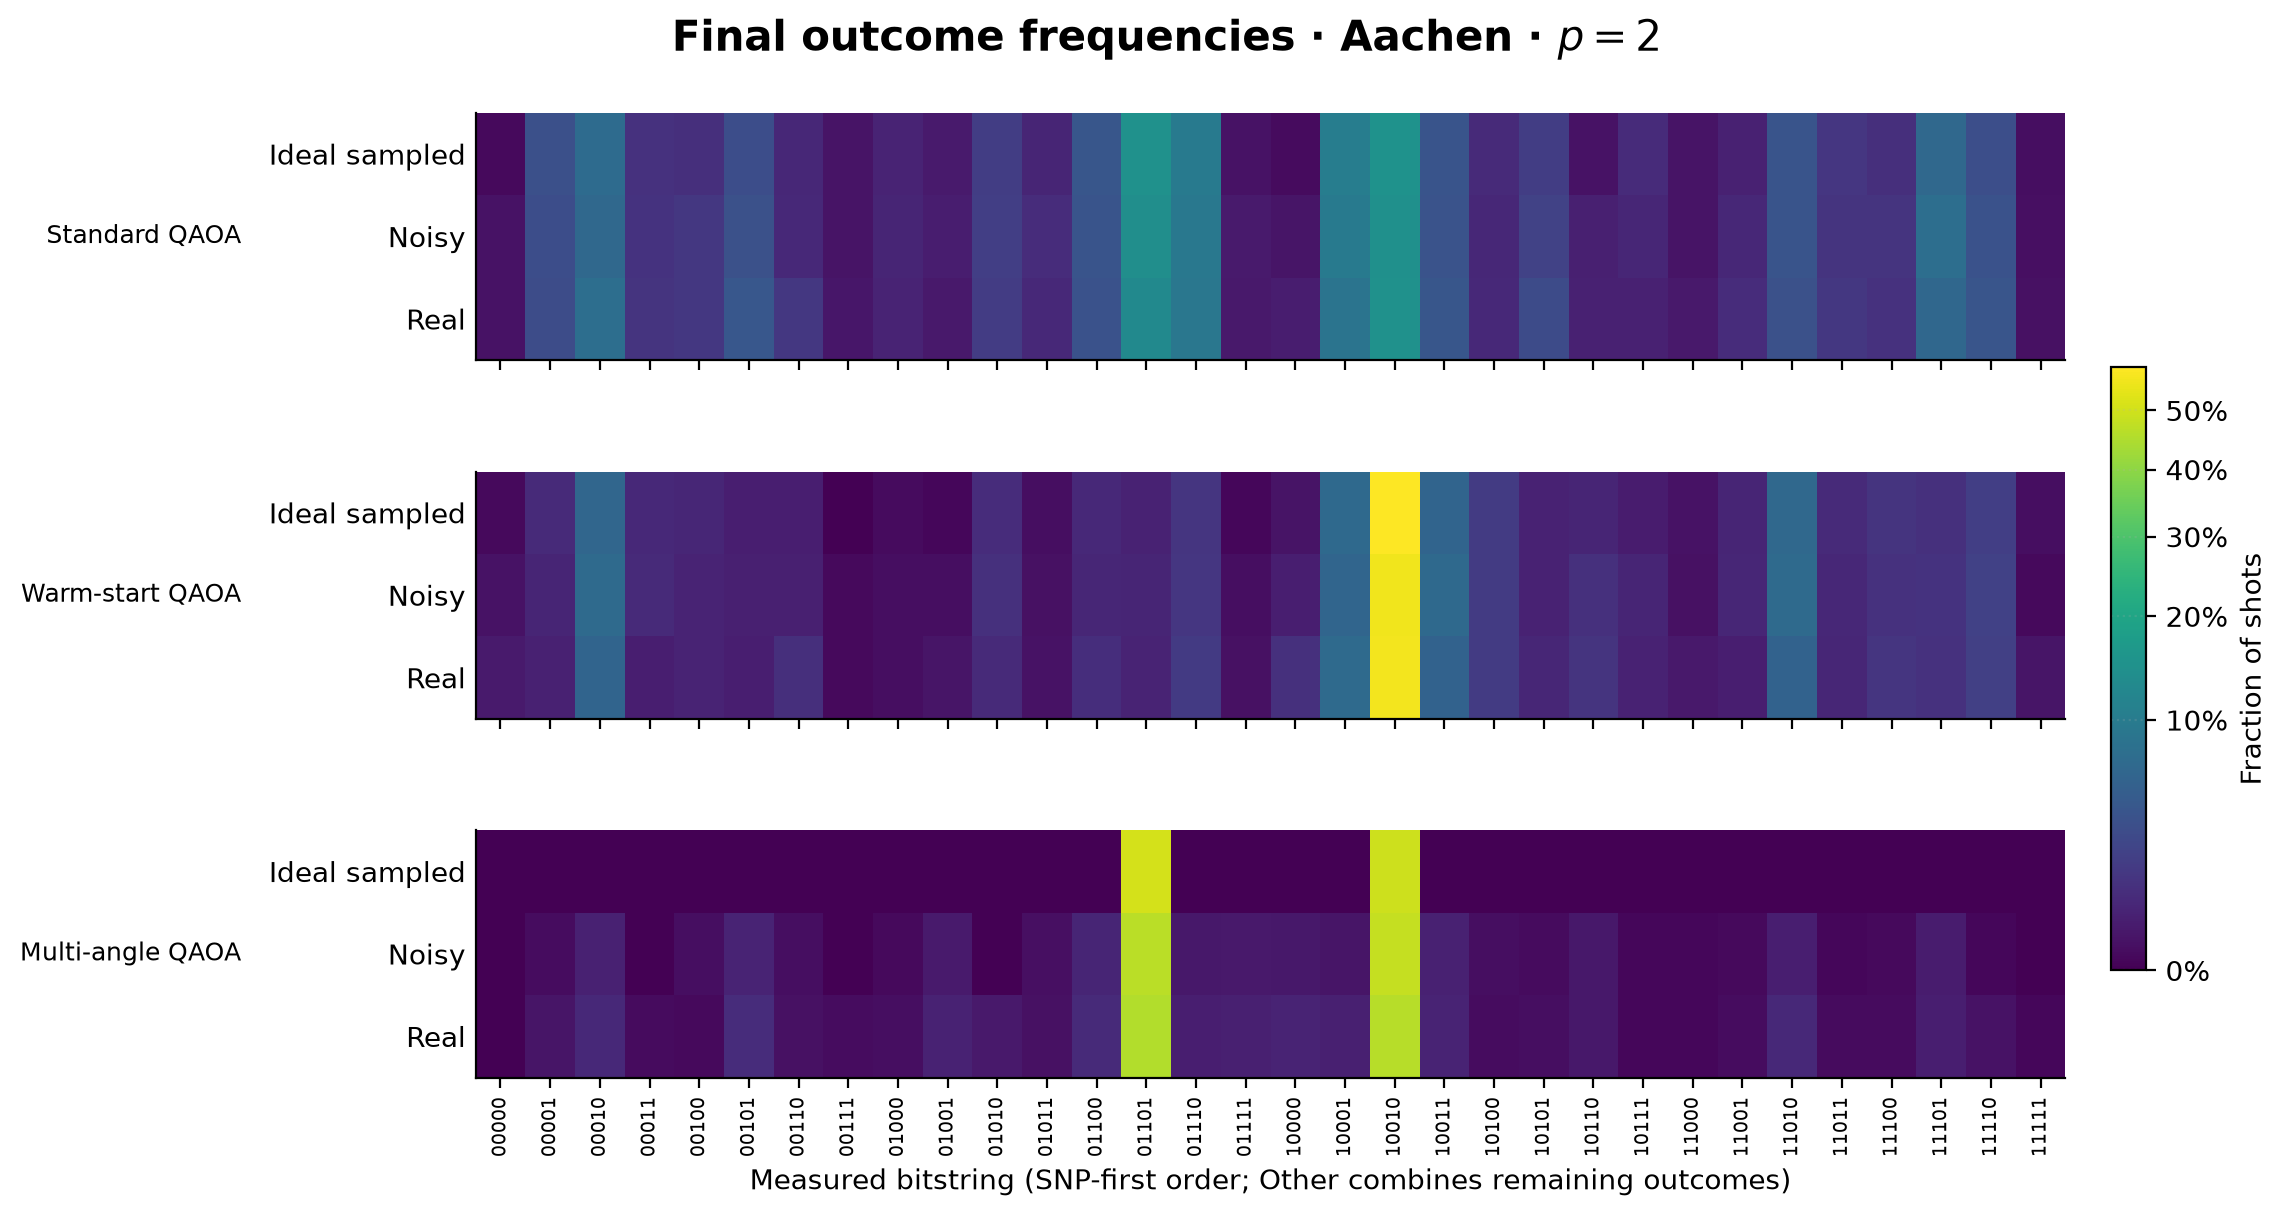

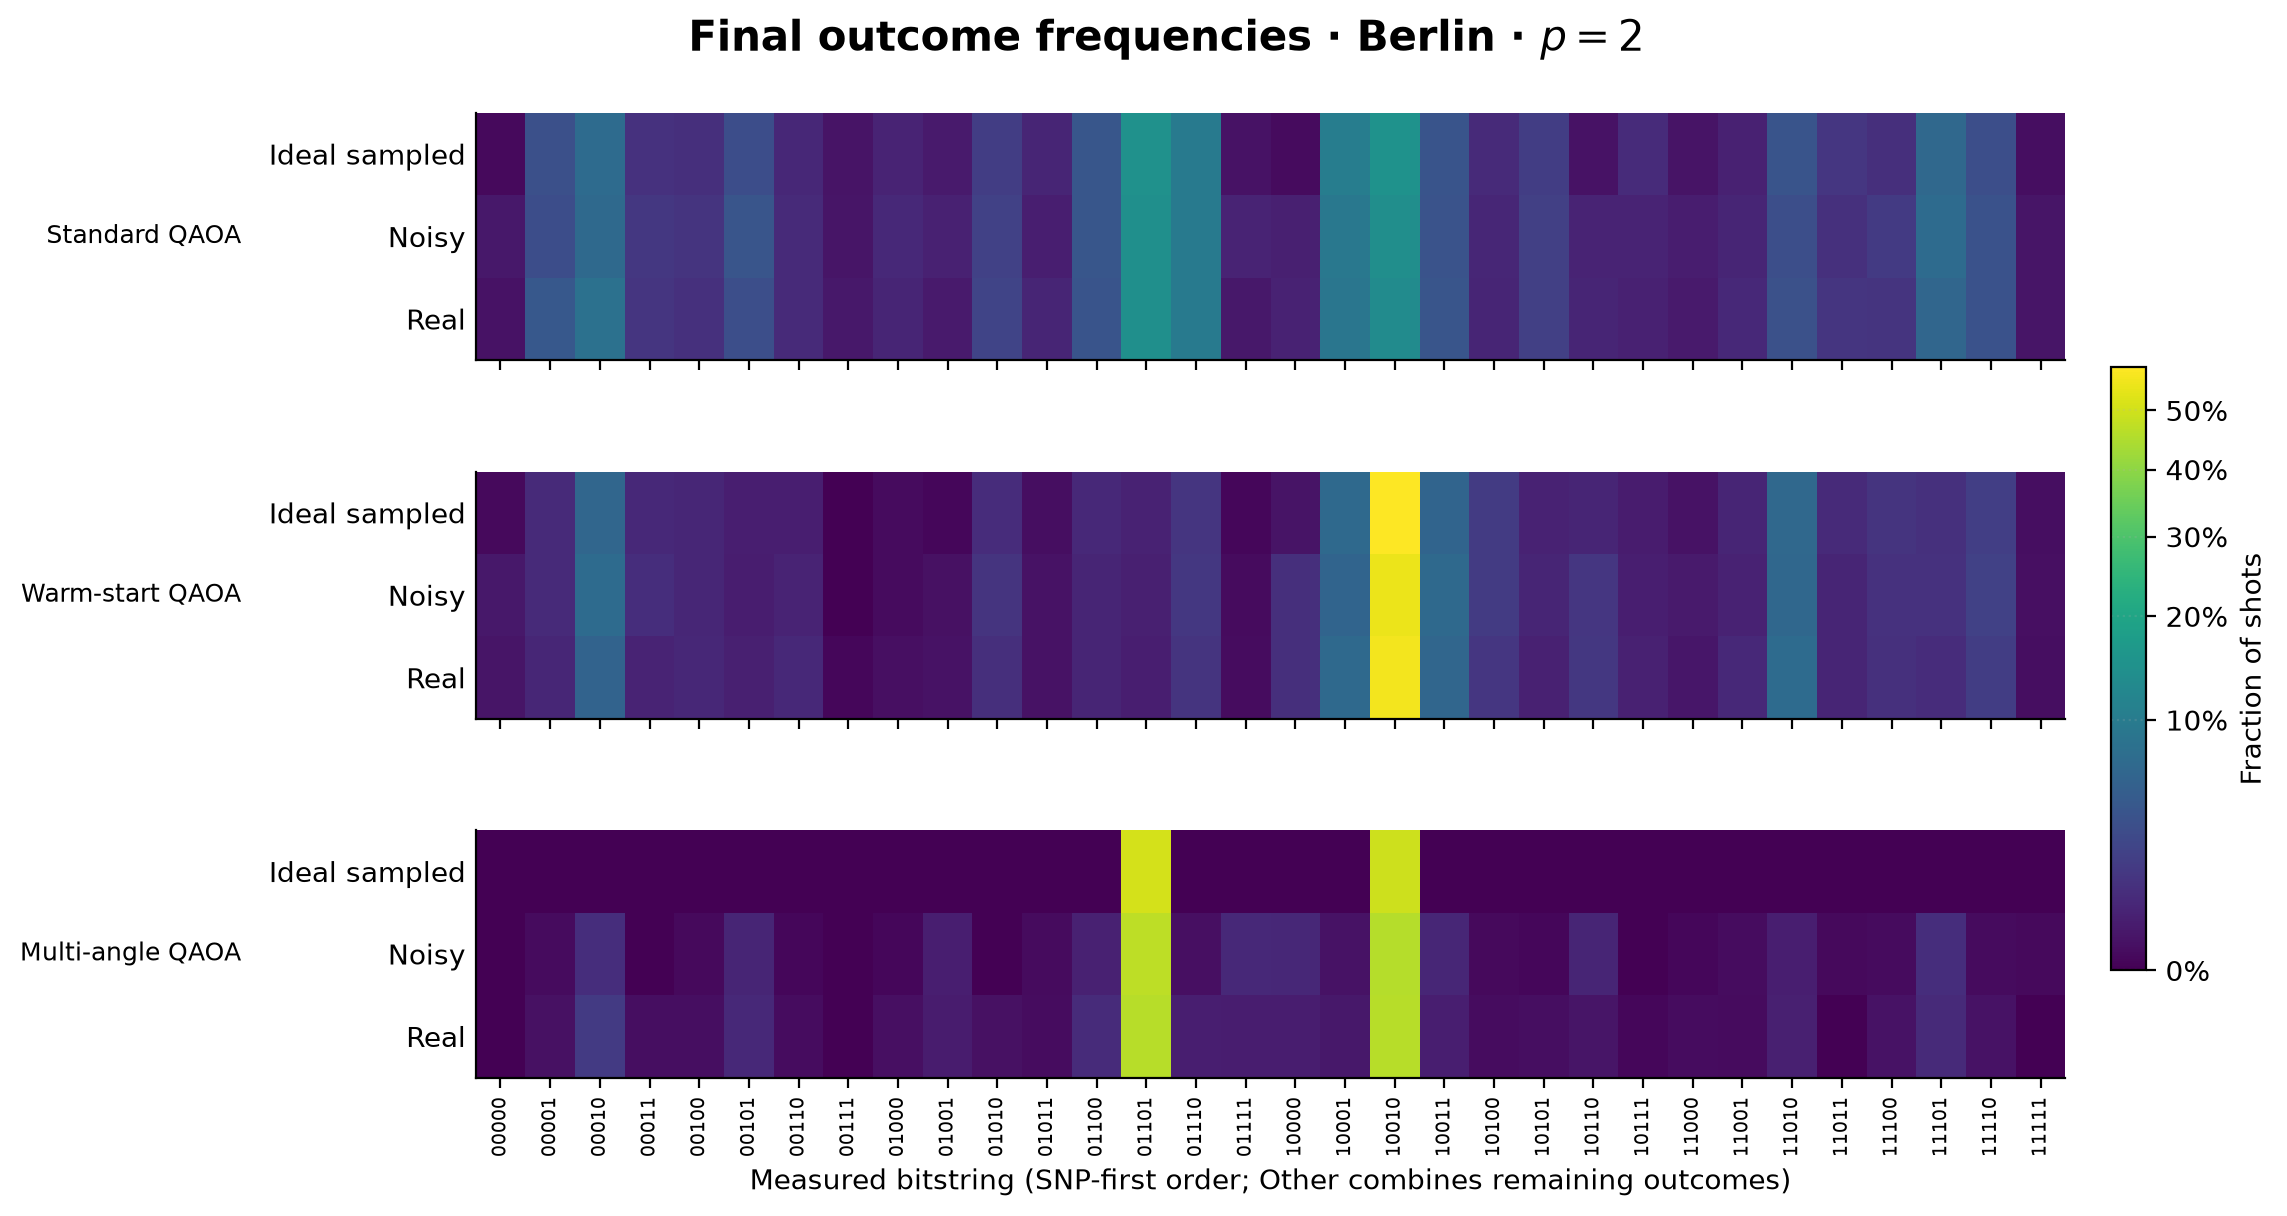

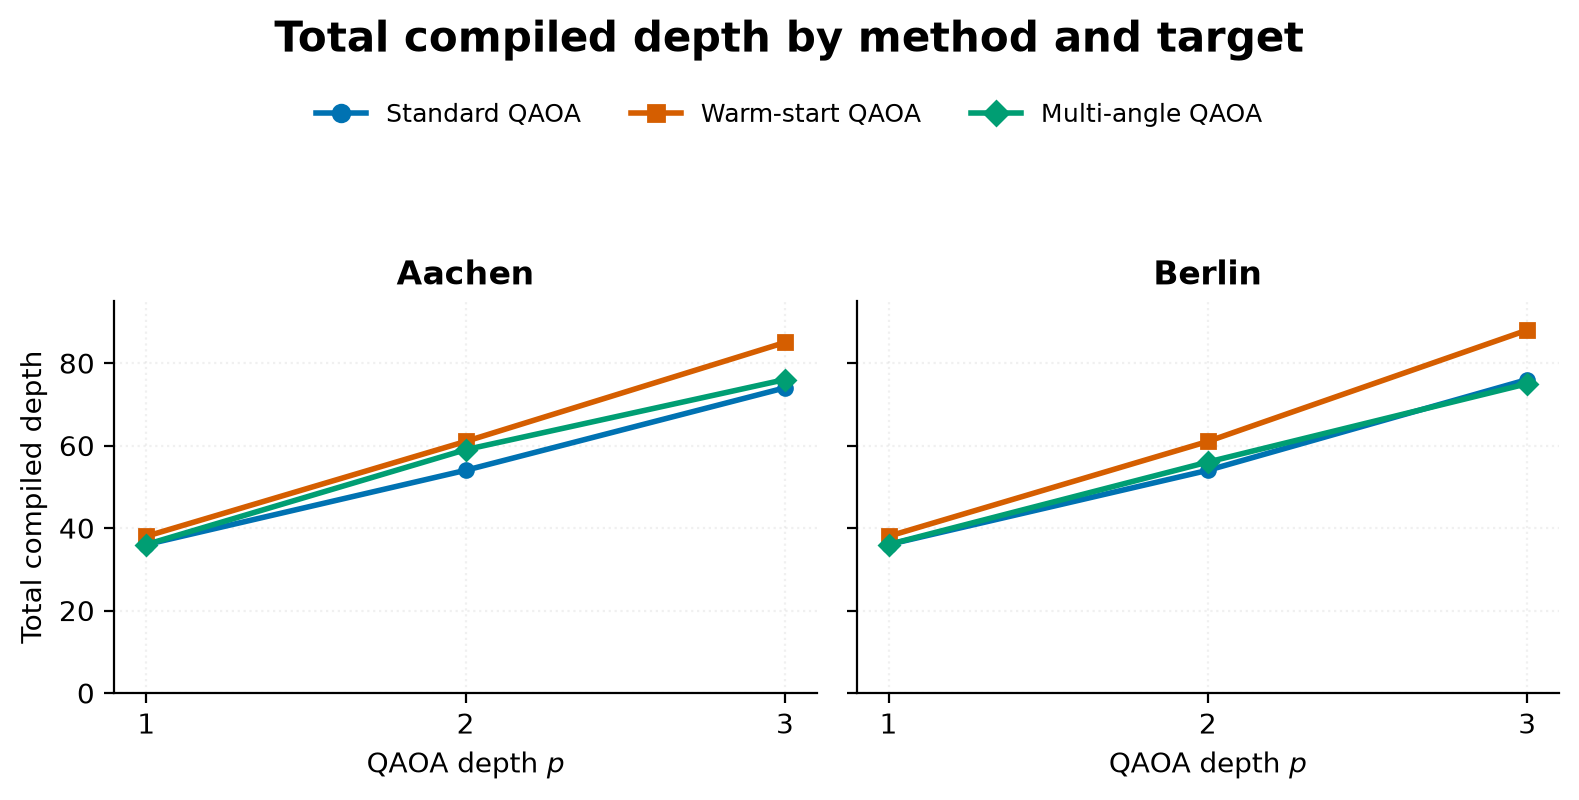

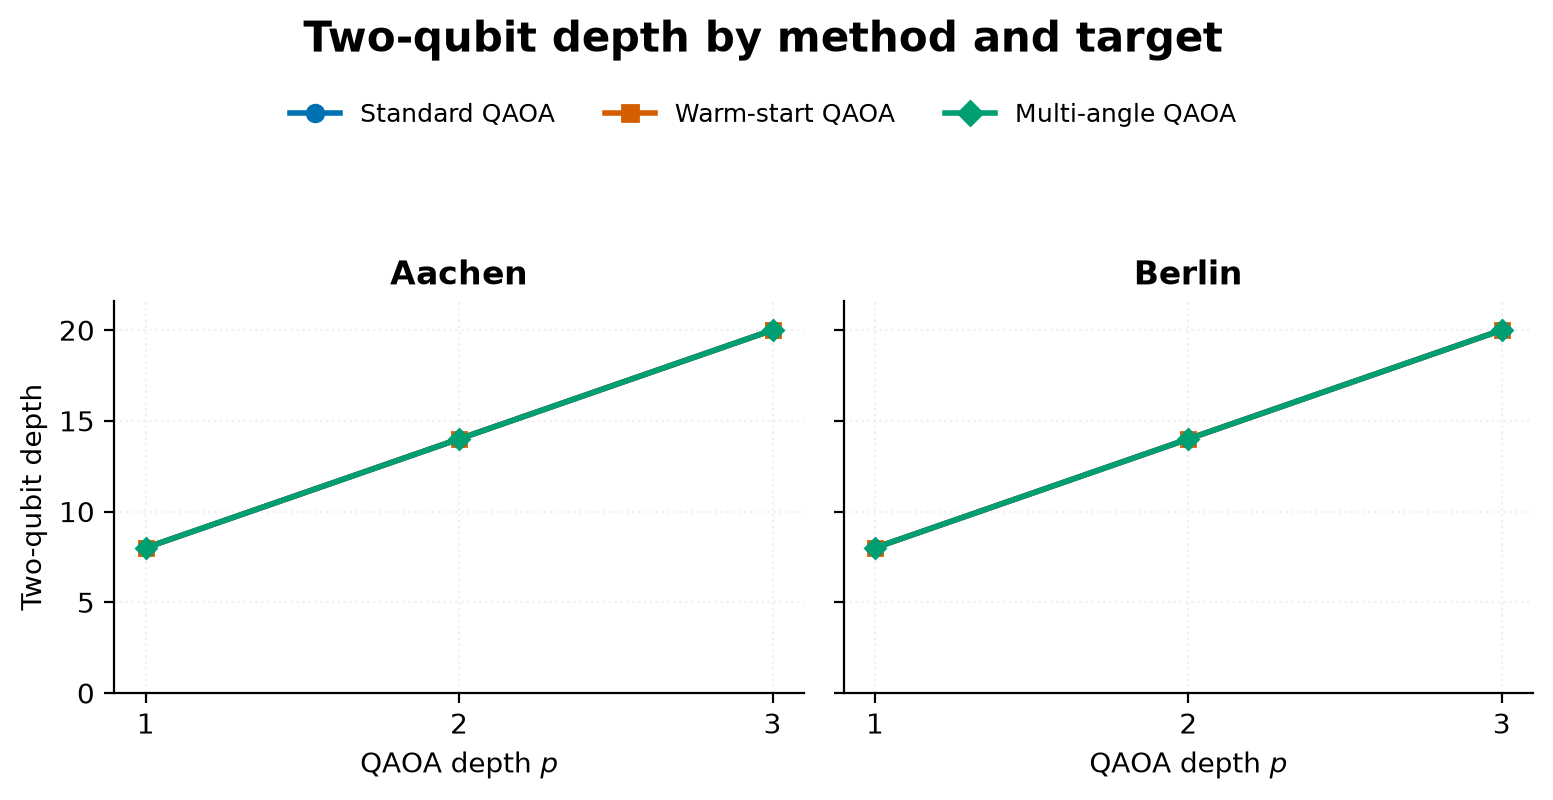

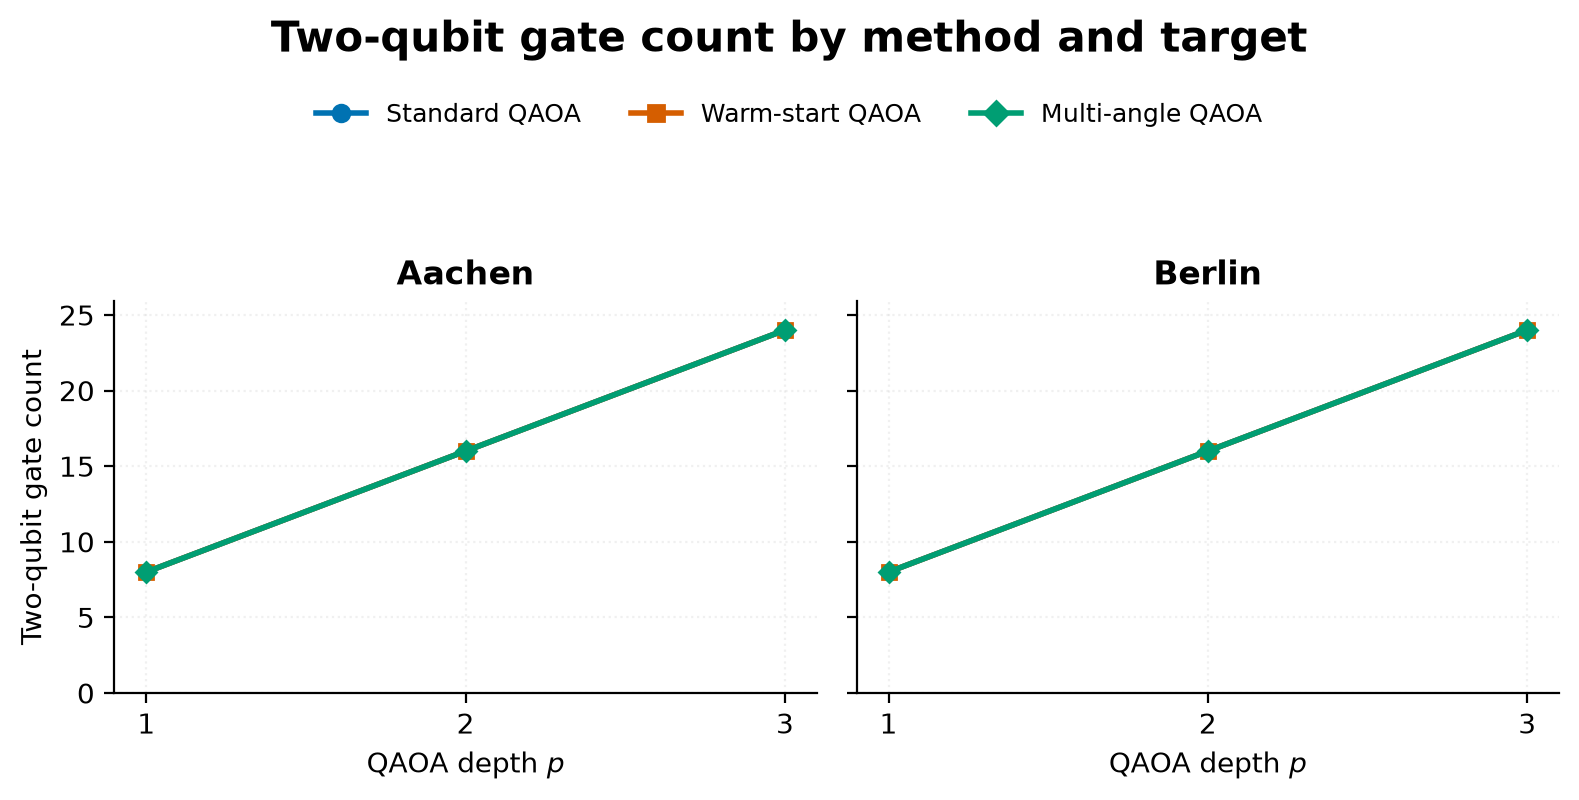

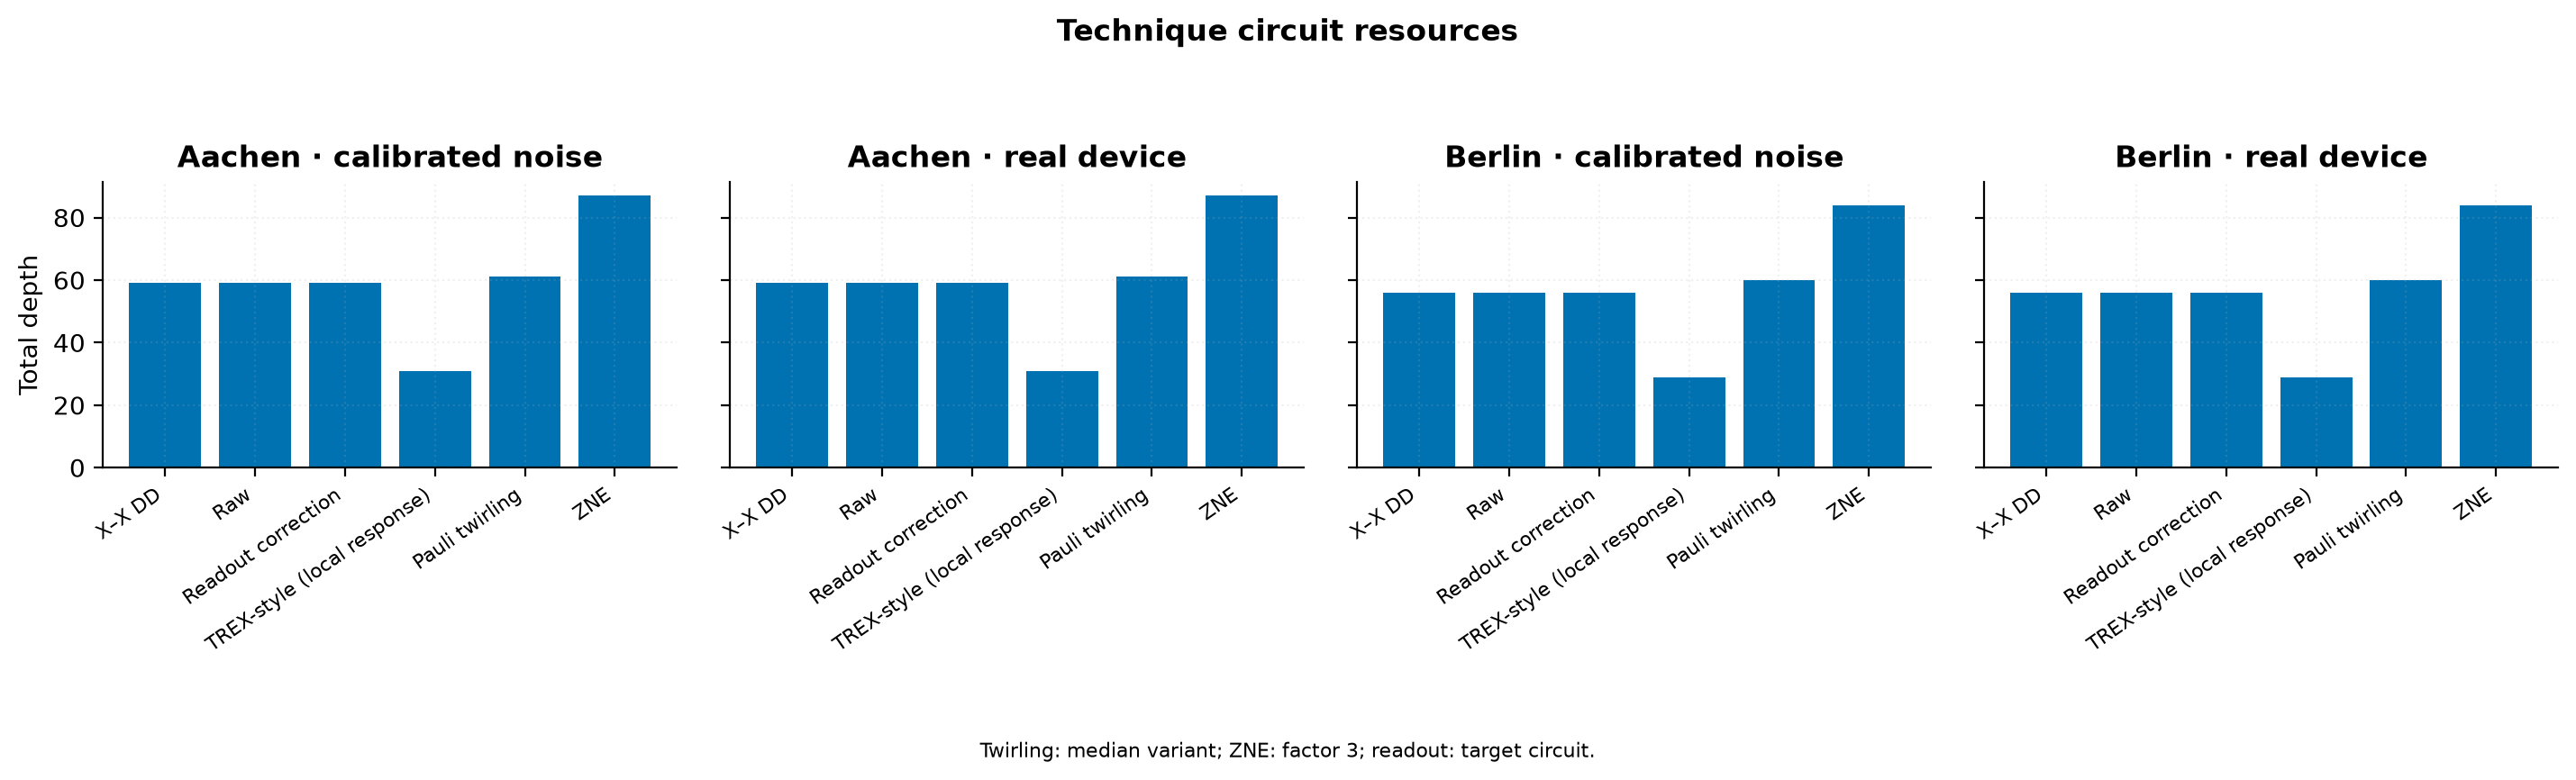

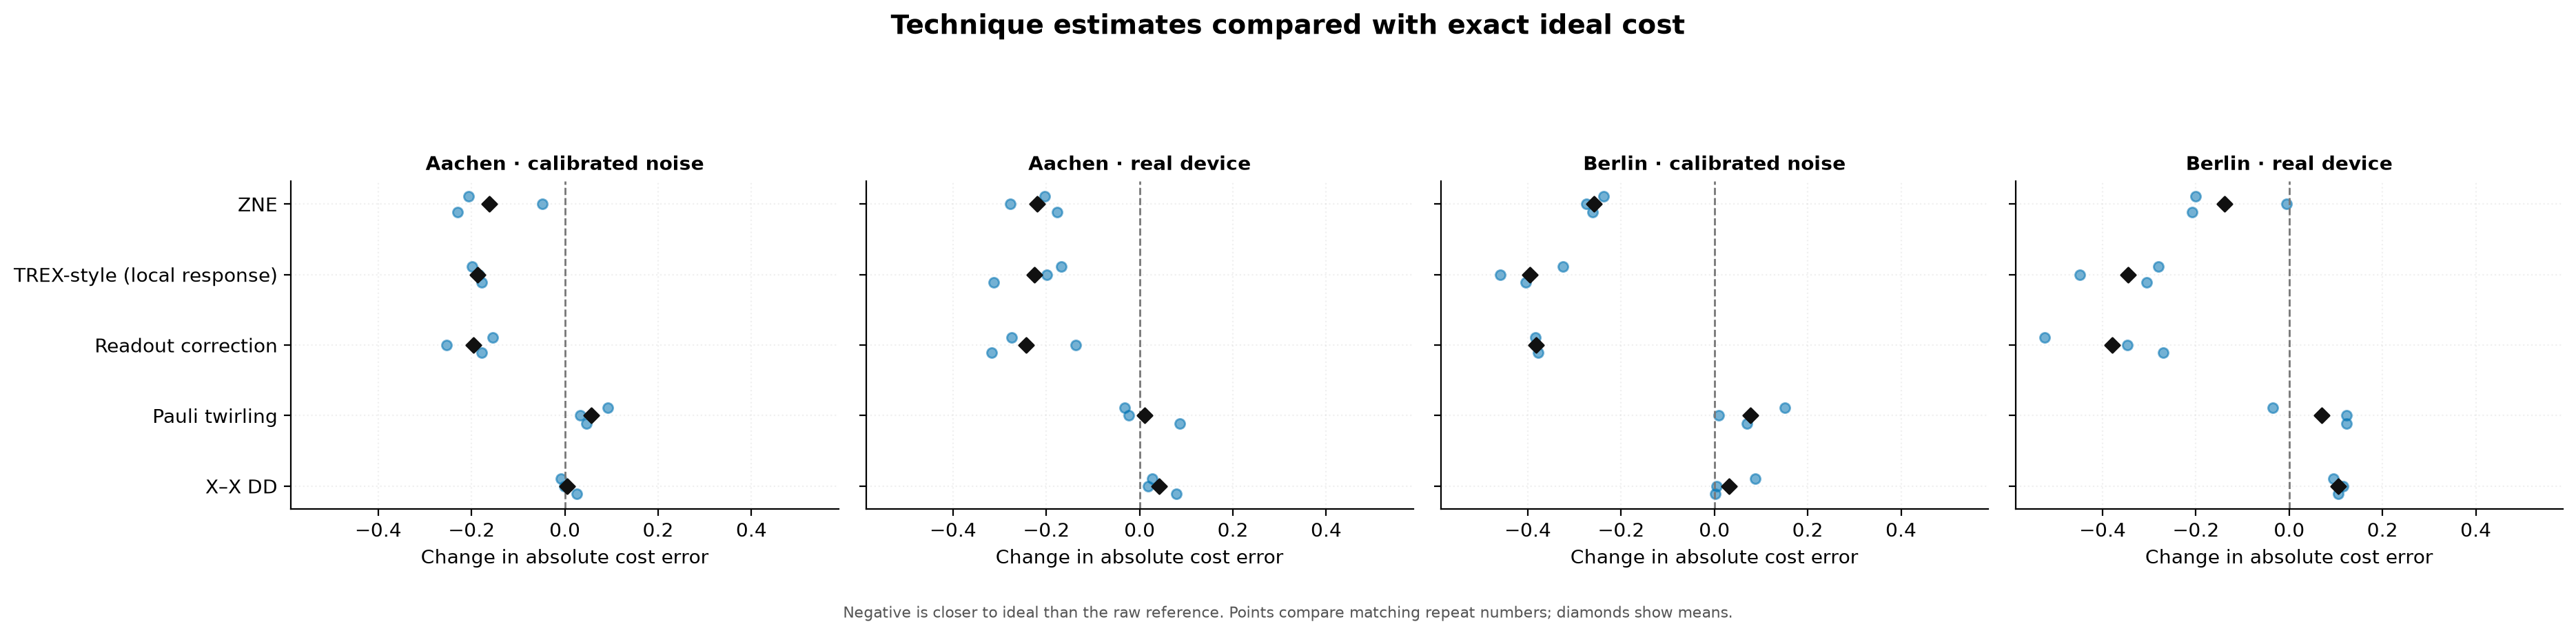

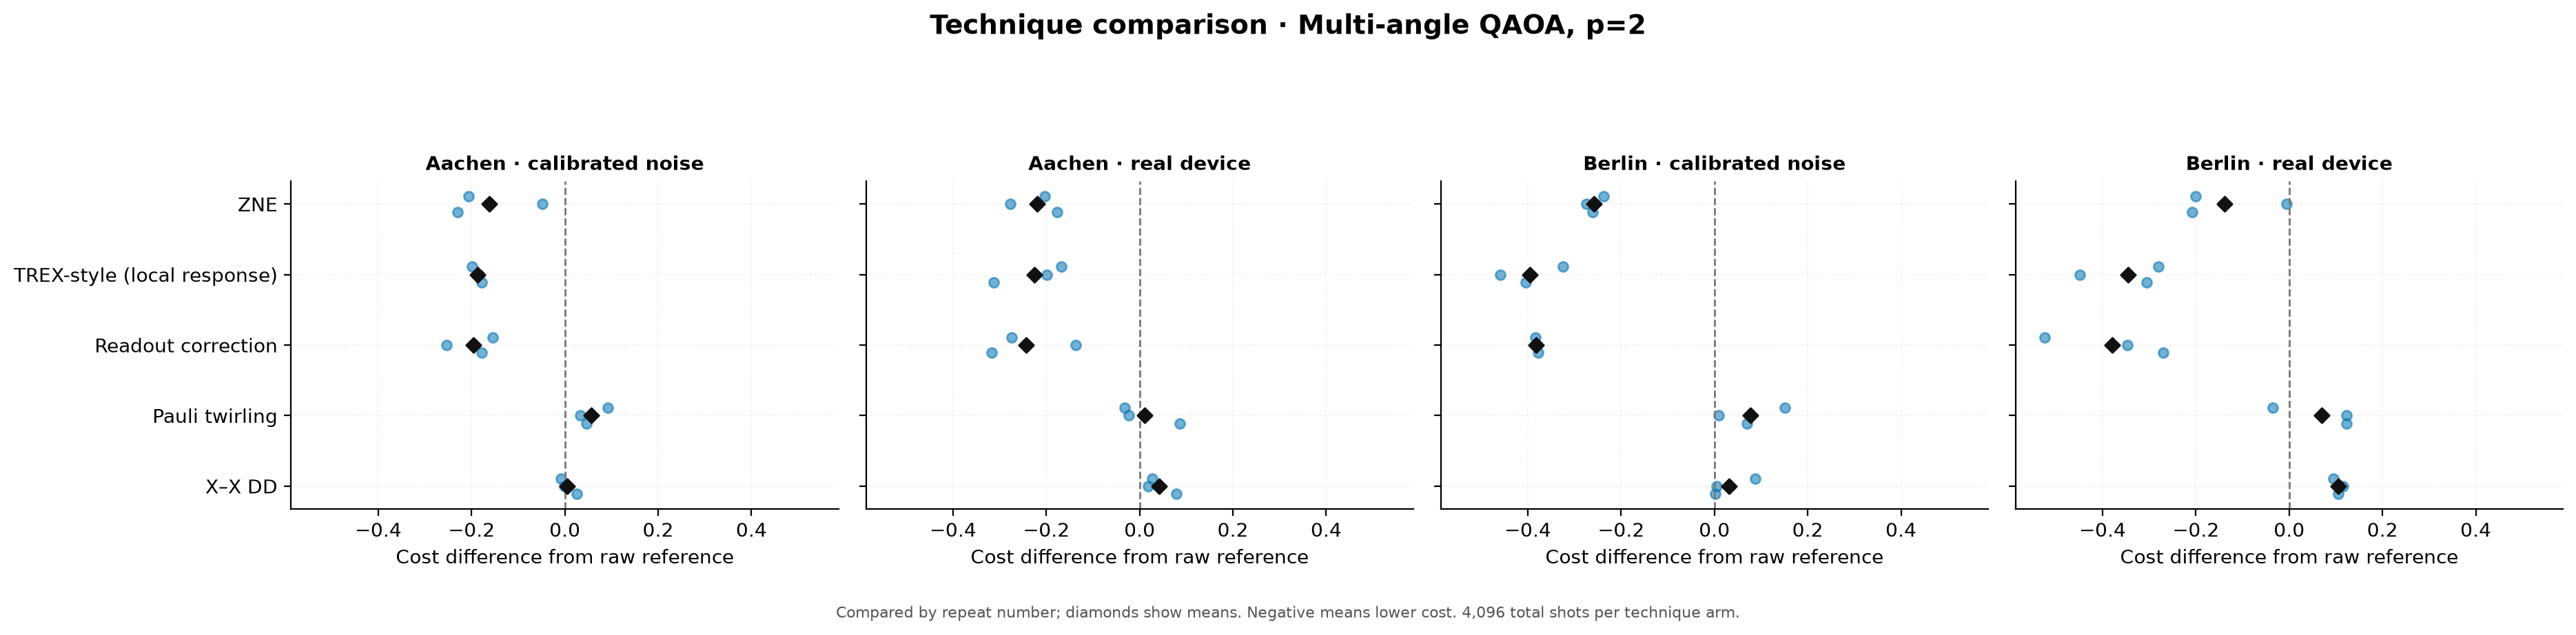

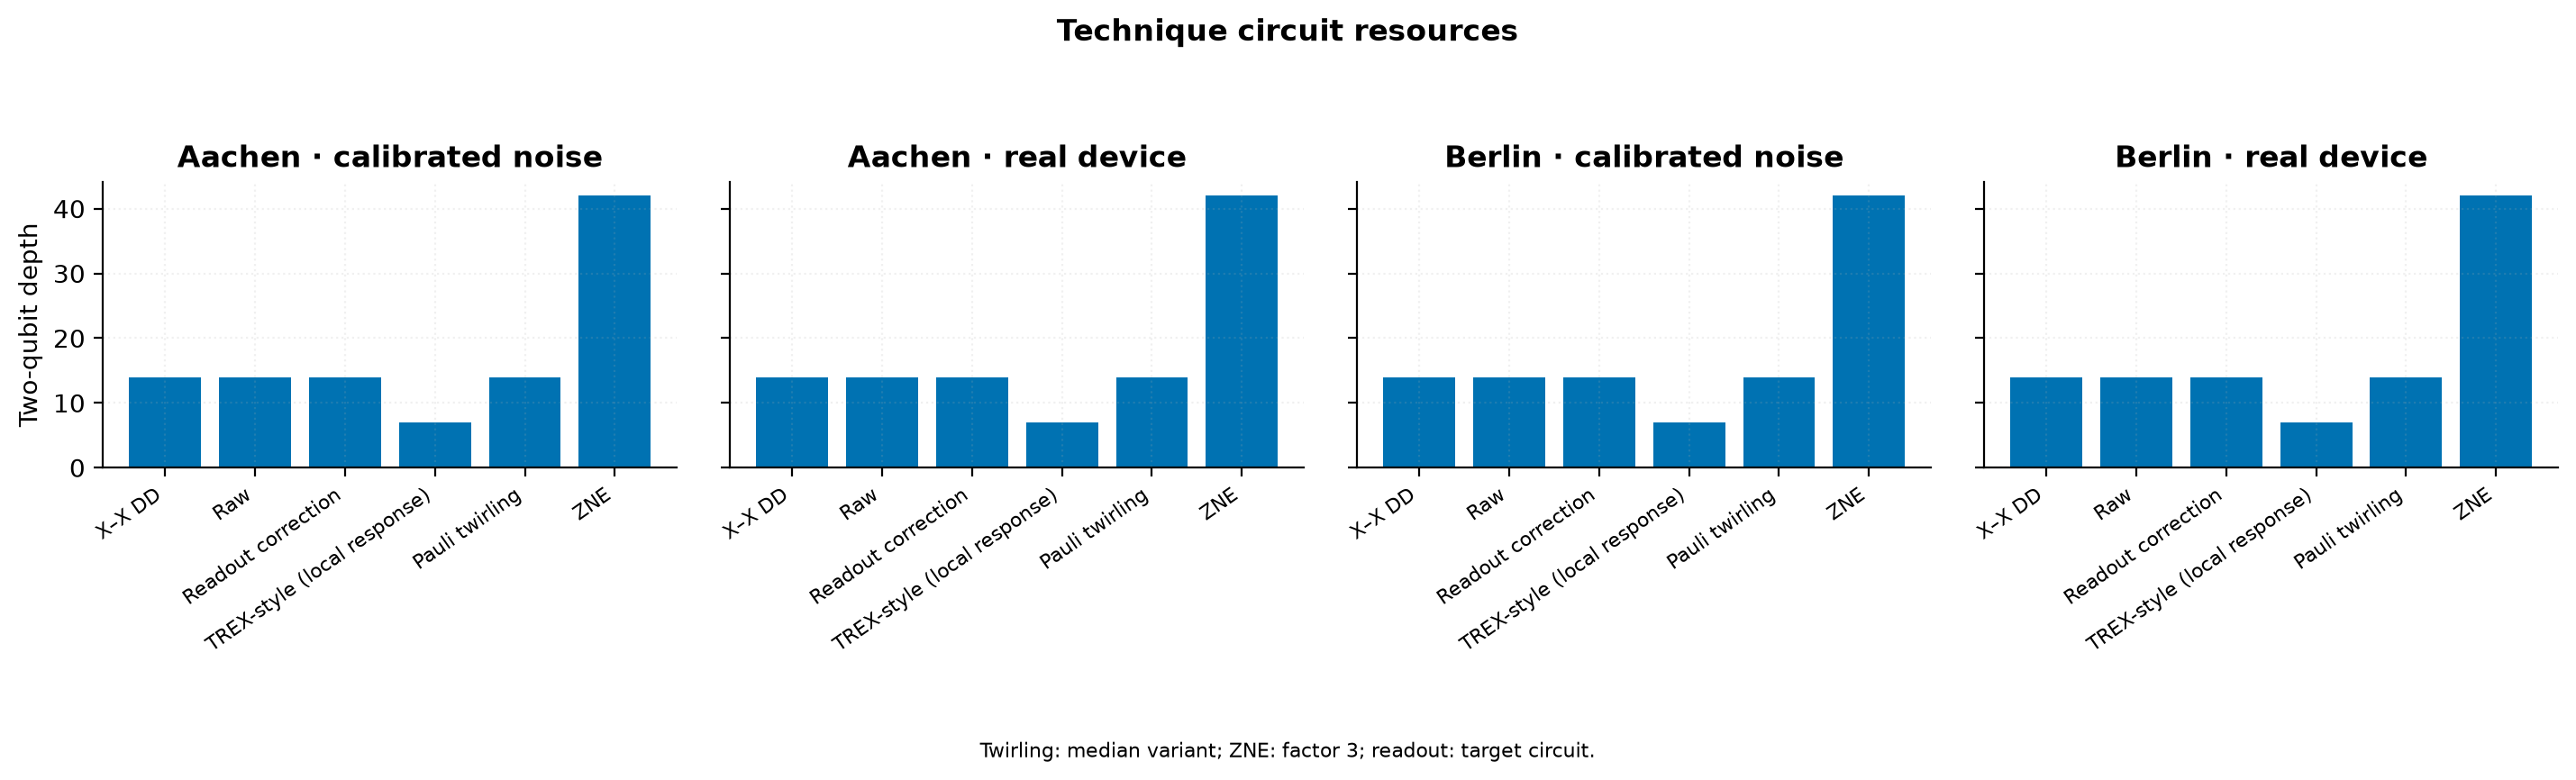

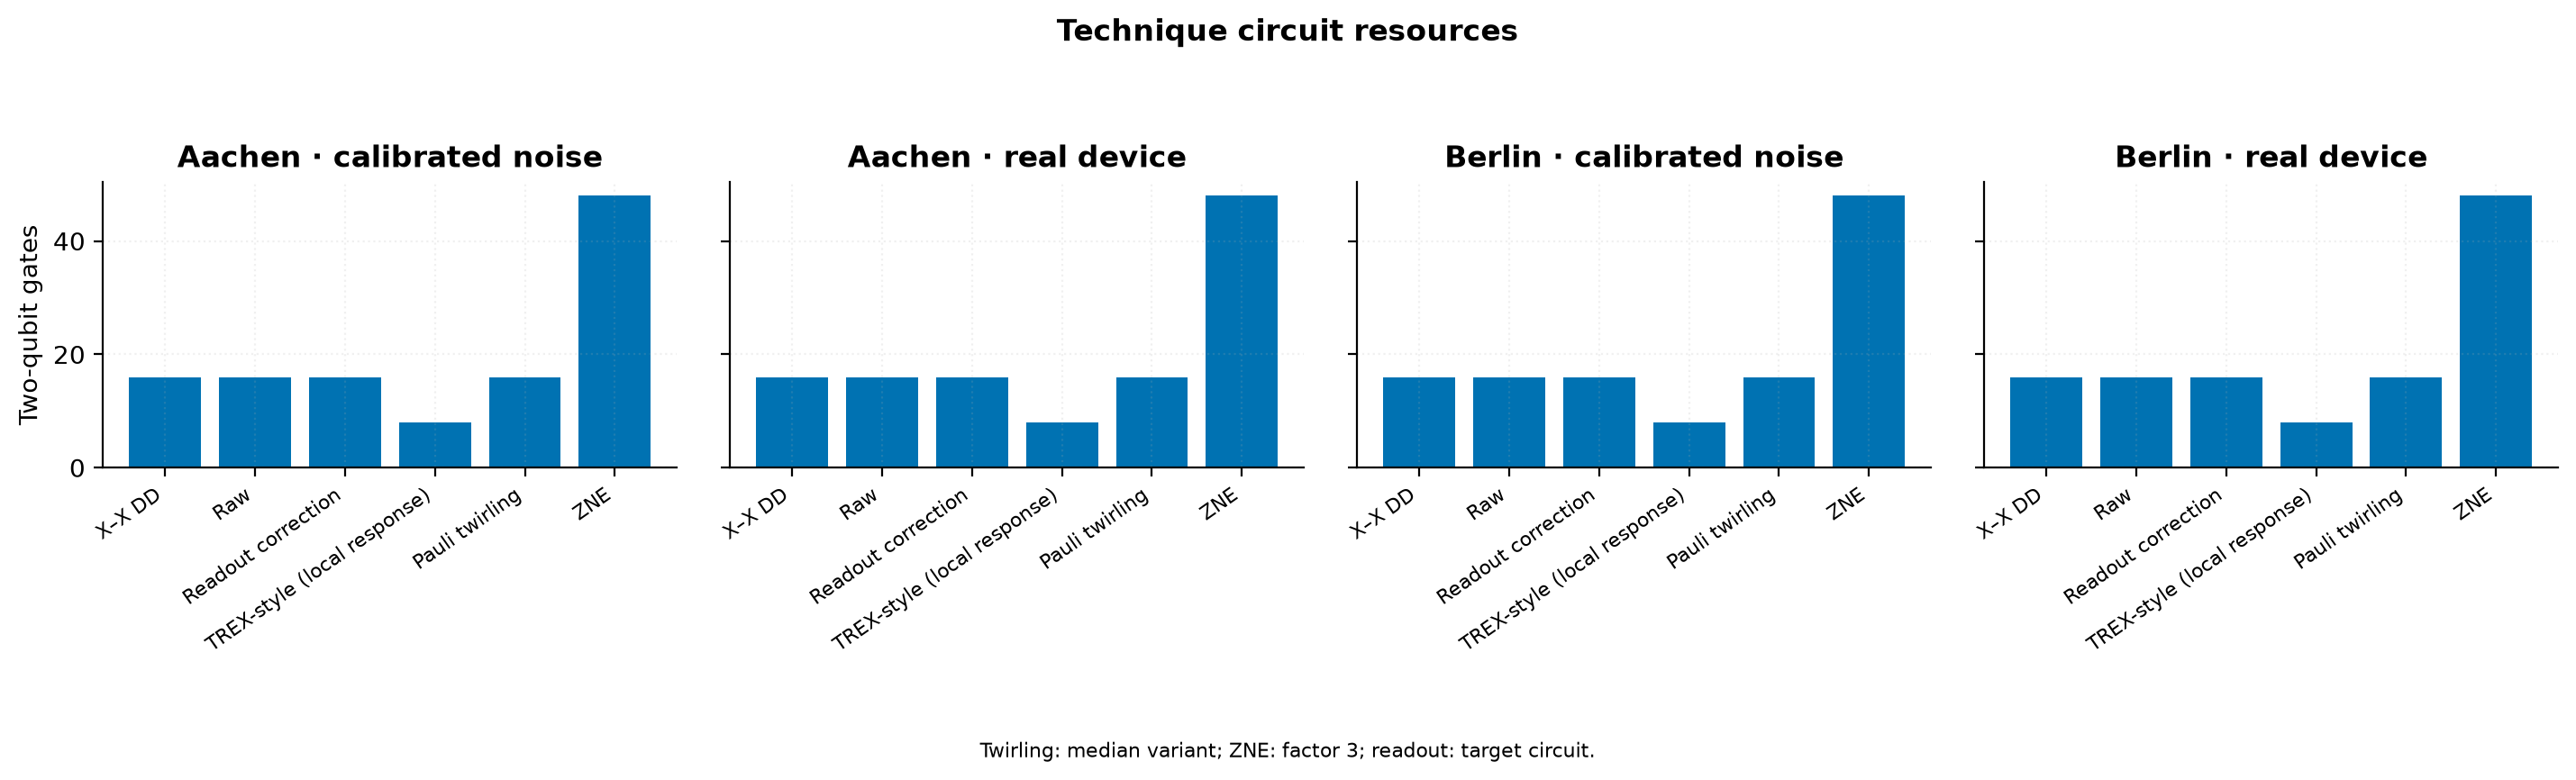

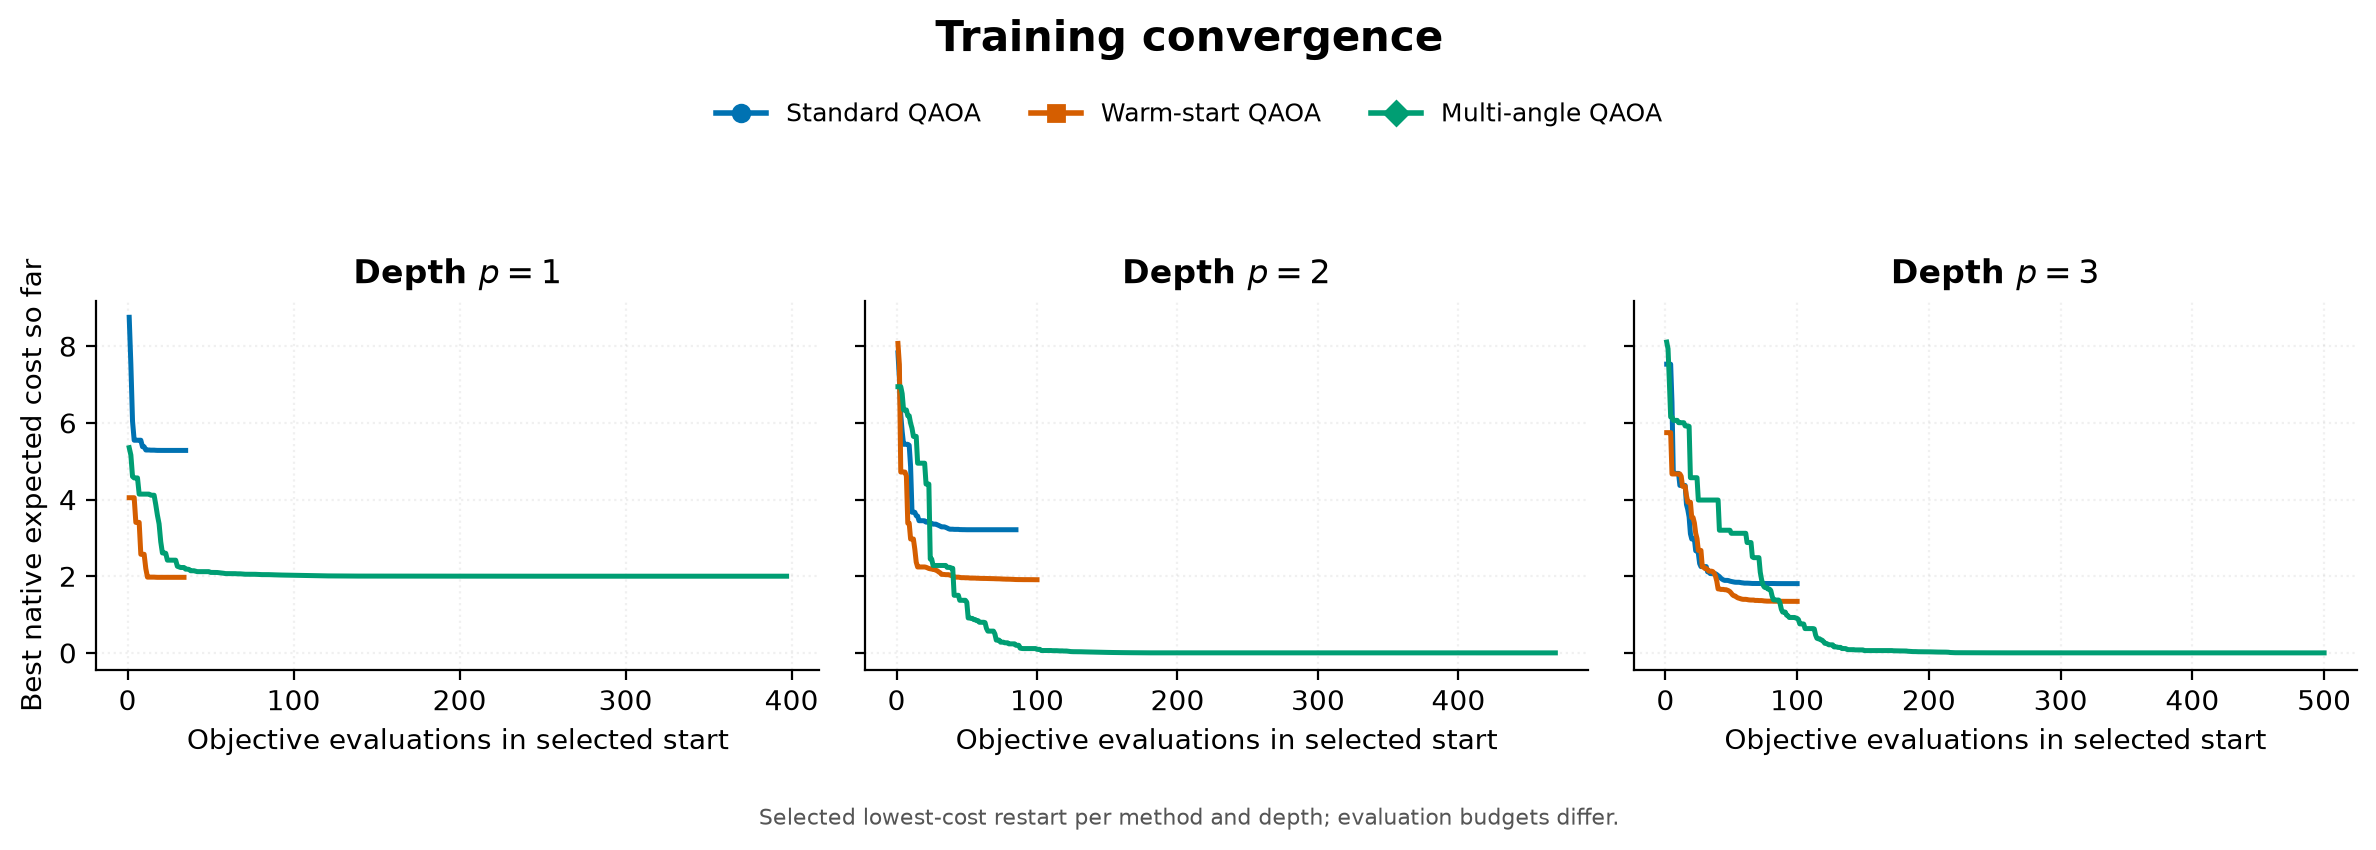

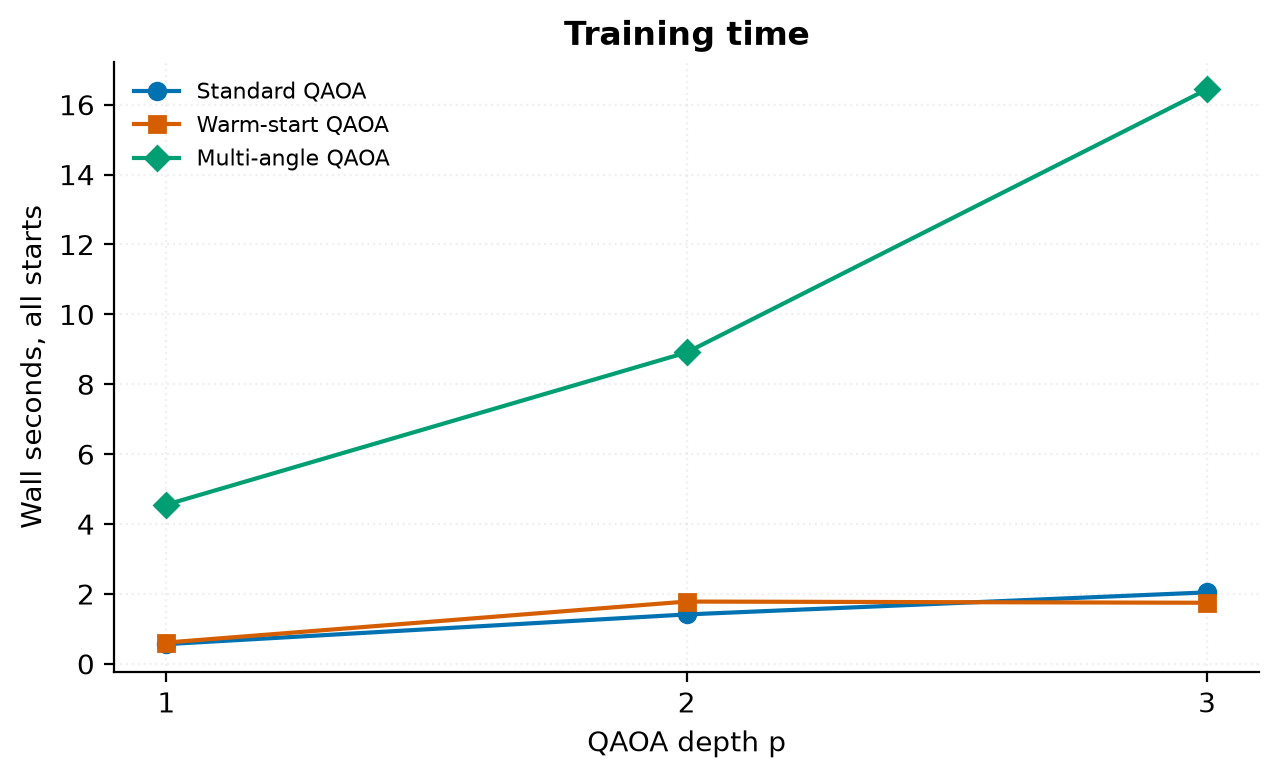

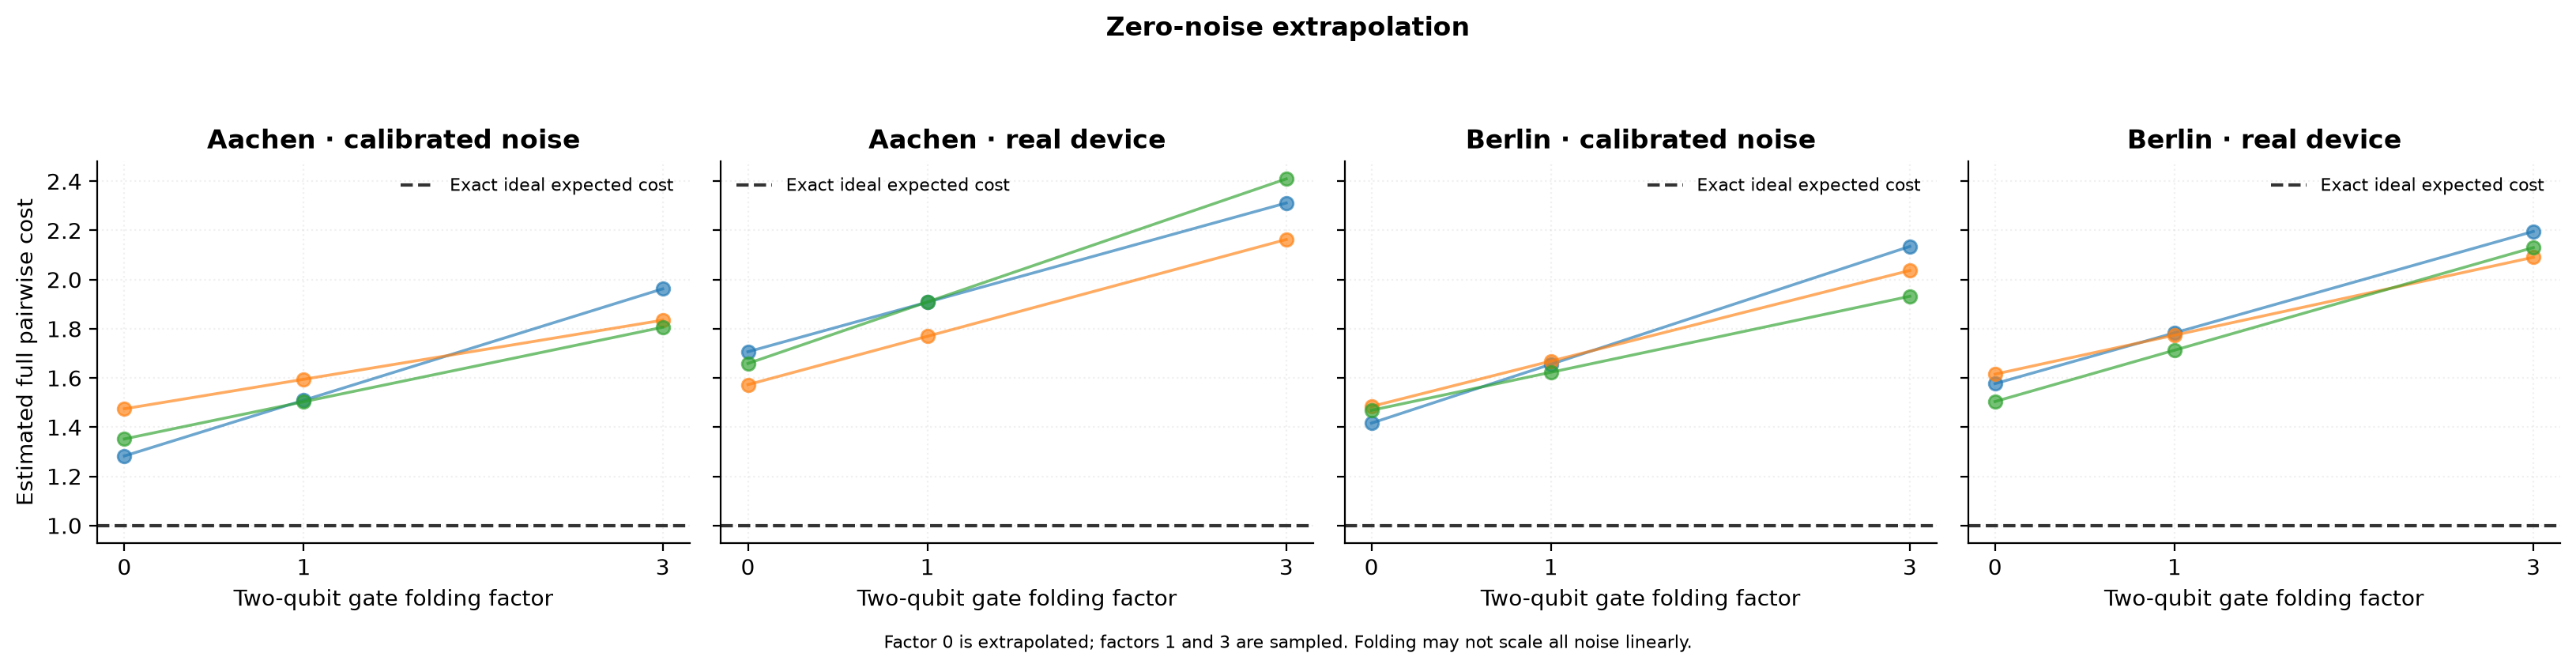

In [39]:
professional_plot_dir = ROOT/'figures'/'backend_comparison'/Path(run_dir).name
professional_ready = False
if GENERATE_PROFESSIONAL_PLOTS:
    import subprocess
    try:
        subprocess.run([sys.executable, str(ROOT/'scripts'/'plots'/'make_plots.py'), '--run', str(run_dir), '--output', str(professional_plot_dir)]
                       + (['--all-depths'] if CONFIG['all_distribution_depths'] else []), check=True)
        professional_ready = True
    except (OSError, subprocess.CalledProcessError) as exc:
        print(f'Measurements remain saved; professional plotting failed: {exc}')
if SHOW_PLOTS:
    if professional_ready:
        for image_path in sorted((professional_plot_dir/'png').glob('0[1-7]_*.png')):
            display(Image(filename=str(image_path)))

## 10. Recover a submitted job
Use `MODE="resume"` with `RUN_FOLDER` and the original settings. Submitted job IDs and their PUB mapping are recovered before further work; a partial job is never submitted again. If submission was interrupted before an ID was received, check IBM for the job and set `RECOVER_JOB_IDS` using the backend and repeat shown in the manifest. The notebook will not resubmit an unknown job. If calibration changed, retrieved results remain saved and a new run is required for comparable local simulation. Runs are saved under `results/backend_comparison/`.